# 🏠 Airbnb Nightly Price Prediction using Machine Learning

### College Machine Learning Mini-Project

| | |
|---|---|
| **Student name** | ____________________ |
| **University / Department** | ____________________ |
| **Course** | ____________________ |
| **Guide / Examiner** | ____________________ |

---

## 01 - Project Introduction

### Abstract
Choosing the right nightly price is one of the hardest decisions for an Airbnb host: too high and the property stays empty, too low and money is lost. This project builds a **supervised regression system** that estimates the nightly price of a listing from its characteristics (city, neighbourhood, room type, size, amenities, host and review information). We download a public Airbnb dataset, clean and explore it, engineer extra features, compare several regression algorithms, tune the best one with cross-validation, explain what drives the predictions, and finally package everything into a reusable pipeline with an interactive prediction interface.

### Introduction
Airbnb is an online marketplace where people rent out rooms and homes. Every listing has a nightly price chosen by the host. Prices depend on many things - *where* the property is, *what type* of place it is, *how many guests* it fits, which *amenities* it offers, and how *trusted* the host and listing are. Machine Learning can learn these relationships automatically from thousands of past listings.

### Problem statement
> Given the attributes of an Airbnb listing, predict its expected nightly rental price.

This is a **regression** problem (the output is a continuous number, not a category).

### Motivation - why is this useful in the real world?
* **Hosts** get a data-driven starting price instead of guessing.
* **Guests** can see whether a listing looks over- or under-priced.
* **Airbnb / property managers** can suggest prices automatically (this is essentially how "Smart Pricing" tools start).
* **Investors** can estimate rental income before buying a property.

### Objectives
1. Download, inspect and understand the dataset (no assumed column names).
2. Clean the data and build a **leak-free** preprocessing pipeline.
3. Explore the data with meaningful visualisations.
4. Engineer useful features (capacity ratios, amenities, location, review activity).
5. Train and compare Linear Regression, Decision Tree, Random Forest, Gradient Boosting and HistGradientBoosting.
6. Tune the best model using cross-validation on the training data only.
7. Evaluate honestly with MAE, MSE, RMSE and R² on an untouched test set.
8. Explain the model (feature importance, permutation importance, SHAP).
9. Build an interactive prediction system and save the full pipeline for re-use.
10. Prepare for viva with questions, answers and a demonstration script.

### Proposed solution
A single scikit-learn **Pipeline** = *feature engineering -> imputation / encoding / scaling (ColumnTransformer) -> regression model*. Because everything lives in one object, the exact same steps run in training, testing and in the final prediction tool, which prevents data leakage and "training/serving mismatch".

### Machine Learning approach
Supervised learning -> regression. The target is the (log of the) nightly price. We compare a simple linear model with tree-based ensembles and pick the winner using **cross-validation on the training set**, not by looking at the test set.

### Tools and technologies
Python - pandas - NumPy - Matplotlib / Seaborn - scikit-learn - SciPy - joblib - KaggleHub - SHAP - ipywidgets - Streamlit (optional deployment)

### Expected outcomes
* A trained model that beats a naive "always predict the median" baseline by a clear margin.
* Understanding of which factors drive Airbnb prices (location, room type, capacity ...).
* A working prediction tool (widgets + plain Python function + optional Streamlit app).

### Project workflow
`Dataset -> Data Understanding -> Cleaning -> EDA -> Feature Engineering -> Train/Test Split -> Model Training -> Evaluation -> Tuning -> Final Prediction -> Model Saving -> Optional Deployment`

> **How to run:** *Kernel -> Restart & Run All*. If the Kaggle download is unavailable, put the dataset's CSV next to this notebook (see Section 03). Set `QUICK_RUN = True` in Section 02 for a faster, lighter demo run.

## 02 - Environment Setup

**Libraries used and why**

| Library | Purpose |
|---|---|
| `pandas` | tables (DataFrames), reading CSV files, cleaning |
| `numpy` | fast numeric arrays, maths such as `log` / `exp` |
| `matplotlib`, `seaborn` | charts |
| `scikit-learn` | preprocessing, models, pipelines, cross-validation, metrics |
| `scipy` | statistics (skewness, normality checks) |
| `joblib` | saving / loading the trained pipeline |
| `kagglehub` | downloading the Kaggle dataset from code |
| `shap` | explaining individual predictions (optional) |
| `ipywidgets` | interactive input form inside Jupyter (optional) |

The cell below installs any **missing** package automatically, then all imports are kept together in one place. A **random seed** makes results reproducible: running the notebook again gives the same split and the same models.

In [1]:
# ---- Install only the packages that are missing (safe to re-run) ----
import importlib.util, subprocess, sys

REQUIRED = {            # import name -> pip name
    "pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib", "seaborn": "seaborn",
    "sklearn": "scikit-learn", "scipy": "scipy", "joblib": "joblib",
}
OPTIONAL = {            # the notebook still works if these cannot be installed
    "kagglehub": "kagglehub", "shap": "shap", "ipywidgets": "ipywidgets",
}

def pip_install(packages):
    if packages:
        print("Installing:", ", ".join(packages))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages], check=False)

pip_install([pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None])
pip_install([pip for mod, pip in OPTIONAL.items() if importlib.util.find_spec(mod) is None])
print("Environment check finished.")

Environment check finished.


In [2]:
# ---- All imports in one organised place ----
import os, re, json, time, warnings, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
import joblib
import sklearn

from sklearn.model_selection import (train_test_split, KFold, cross_val_score,
                                     RandomizedSearchCV, GroupShuffleSplit)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from IPython.display import display, Markdown, HTML

# Optional libraries (the notebook keeps working without them)
try:
    import kagglehub
except ImportError:
    kagglehub = None
try:
    import shap
except ImportError:
    shap = None
try:
    import ipywidgets as widgets
except ImportError:
    widgets = None
try:
    from xgboost import XGBRegressor      # optional extra model
except Exception:
    XGBRegressor = None

warnings.filterwarnings("ignore")

# ---- Global settings ----
RANDOM_STATE = 42          # reproducibility: same seed -> same results
TEST_SIZE    = 0.20        # 80 : 20 train/test split
QUICK_RUN    = False       # True = lighter models/search for a fast demo (results will be a bit worse)
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
                     "legend.fontsize": 10, "figure.autolayout": True})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | scipy {scipy.__version__}")
print("kagglehub:", "yes" if kagglehub else "no", "| shap:", "yes" if shap else "no",
      "| ipywidgets:", "yes" if widgets else "no", "| xgboost:", "yes" if XGBRegressor else "no")

Python 3.12.3 | pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | scipy 1.18.1
kagglehub: yes | shap: yes | ipywidgets: yes | xgboost: no


## 03 - Dataset Download

### What is KaggleHub?
**KaggleHub** is a small Python package that downloads Kaggle datasets and models directly from code, caches them on your computer, and returns the folder path. No manual "download -> unzip -> move" steps are needed.

### Installation
```bash
pip install kagglehub
```

### Kaggle authentication (only if required)
Public datasets usually download without a login. If you see a *401/403 / "authentication required"* error:
1. Open Kaggle -> **Settings -> API -> Create New Token** (downloads `kaggle.json`).
2. Either put `kaggle.json` in `~/.kaggle/` **or** set the environment variables `KAGGLE_USERNAME` and `KAGGLE_KEY`, **or** run `kagglehub.login()` in a notebook cell.
3. Open the dataset page once in your browser and accept its terms if Kaggle asks.

### What this section does
1. Tries `kagglehub.dataset_download("stevezhenghp/airbnb-price-prediction")`.
2. Prints the downloaded **folder structure**.
3. **Discovers** the correct CSV automatically (no assumed file names): it looks for CSV files that contain a price-like column and picks the largest one.
4. If the download fails, it prints troubleshooting tips and falls back to a **local CSV** (a file placed next to the notebook, in `./data`, or the path set in `MANUAL_CSV_PATH`).

In [3]:
DATASET_SLUG    = "stevezhenghp/airbnb-price-prediction"
MANUAL_CSV_PATH = None     # e.g. "train.csv"  <- set this only if the automatic download does not work

dataset_dir = None
try:
    if kagglehub is None:
        raise ImportError("kagglehub is not installed (run: pip install kagglehub)")
    dataset_dir = Path(kagglehub.dataset_download(DATASET_SLUG))
    print("Dataset downloaded to:", dataset_dir)
except Exception as exc:
    print(f"KaggleHub download was not possible -> {type(exc).__name__}: {str(exc)[:200]}")
    print("""
Troubleshooting
  1. Internet: make sure this machine can reach kaggle.com.
  2. Install:  pip install kagglehub
  3. Login:    create a token (Kaggle -> Settings -> API) and set KAGGLE_USERNAME / KAGGLE_KEY
               or run kagglehub.login()
  4. Manual:   download the dataset from https://www.kaggle.com/datasets/stevezhenghp/airbnb-price-prediction,
               put its CSV next to this notebook (or in ./data) and re-run. The notebook will find it automatically.
""")

KaggleHub download was not possible -> ConnectionError: HTTPSConnectionPool(host='api.kaggle.com', port=443): Max retries exceeded with url: /v1/datasets.DatasetApiService/GetDataset (Caused by NameResolutionError("HTTPSConnection(host='api.kaggle.com', po

Troubleshooting
  1. Internet: make sure this machine can reach kaggle.com.
  2. Install:  pip install kagglehub
  3. Login:    create a token (Kaggle -> Settings -> API) and set KAGGLE_USERNAME / KAGGLE_KEY
               or run kagglehub.login()
  4. Manual:   download the dataset from https://www.kaggle.com/datasets/stevezhenghp/airbnb-price-prediction,
               put its CSV next to this notebook (or in ./data) and re-run. The notebook will find it automatically.



In [4]:
def show_tree(root, max_files=40):
    # Print a simple directory tree with file sizes.
    root = Path(root)
    print(f"{root}")
    n = 0
    for p in sorted(root.rglob("*")):
        if p.is_file():
            n += 1
            if n <= max_files:
                print(f"  |-- {p.relative_to(root)}  ({p.stat().st_size/1e6:,.2f} MB)")
    if n > max_files:
        print(f"  ... and {n - max_files} more files")

def price_like_columns(csv_path):
    # Return columns whose name contains 'price' (reads only the header row).
    try:
        cols = pd.read_csv(csv_path, nrows=0).columns
    except Exception:
        return []
    return [c for c in cols if "price" in str(c).lower()]

if dataset_dir is not None:
    print("Directory structure of the downloaded dataset:")
    show_tree(dataset_dir)

# Where do we look for CSV files?
search_roots = []
if dataset_dir is not None:
    search_roots.append(Path(dataset_dir))
if MANUAL_CSV_PATH:
    search_roots.append(Path(MANUAL_CSV_PATH))
if os.environ.get("AIRBNB_CSV_PATH"):
    search_roots.append(Path(os.environ["AIRBNB_CSV_PATH"]))
search_roots += [Path.cwd(), Path.cwd() / "data"]          # fallback: local files

csv_files = []
for root in search_roots:
    if root.is_file() and root.suffix.lower() == ".csv":
        csv_files.append(root)
    elif root.is_dir():
        pattern = "**/*.csv" if root == dataset_dir else "*.csv"
        csv_files += list(root.glob(pattern))
csv_files = list(dict.fromkeys(csv_files))                  # remove duplicates, keep order

candidates = []
for f in csv_files:
    cols = price_like_columns(f)
    if cols:
        candidates.append((f, cols, f.stat().st_size))

print("\nCSV files found:", len(csv_files))
for f, cols, size in candidates:
    print(f"  candidate: {f.name:<25} price-like columns: {cols}   size: {size/1e6:,.1f} MB")

if not candidates:
    raise FileNotFoundError(
        "No CSV with a price column was found. Download the dataset manually, place the CSV next to this "
        "notebook (or set MANUAL_CSV_PATH) and run this cell again.")

# Prefer files from the downloaded folder, then the largest file (a training file has the target, test files do not).
candidates.sort(key=lambda t: (dataset_dir is not None and Path(dataset_dir) in t[0].parents, t[2]), reverse=True)
DATA_FILE = candidates[0][0]
print(f"\nSelected data file: {DATA_FILE.name}   (contains the target column(s): {candidates[0][1]})")


CSV files found: 1
  candidate: train.csv                 price-like columns: ['log_price']   size: 101.5 MB

Selected data file: train.csv   (contains the target column(s): ['log_price'])


## 04 - Data Import

We load the CSV with pandas and look at the first and last rows, the dimensions, and every column with its data type. Then we **automatically identify the target column** and check how the price is stored.

In [5]:
df_raw = pd.read_csv(DATA_FILE)
print("Loaded:", DATA_FILE.name)
print(f"Dimensions: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
display(Markdown("**First 5 rows**"))
display(df_raw.head())
display(Markdown("**Last 5 rows**"))
display(df_raw.tail())
display(Markdown("**All columns and data types**"))
display(pd.DataFrame({"column": df_raw.columns, "dtype": df_raw.dtypes.astype(str).values,
                      "non-null": df_raw.notna().sum().values}).set_index("column"))

Loaded: train.csv
Dimensions: 74,111 rows x 29 columns


**First 5 rows**

,id,log_price,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,description,first_review,host_has_profile_pic,host_identity_verified,host_response_rate,host_since,instant_bookable,last_review,latitude,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,thumbnail_url,zipcode,bedrooms,beds
0,6901257,5.011,Apartment,Entire home/apt,"{""Wireless Internet"",""Air conditioning"",Kitche...",3,1.000,Real Bed,strict,True,NYC,"Beautiful, sunlit brownstone 1-bedroom in the ...",2016-06-18,t,t,NaN,2012-03-26,f,2016-07-18,40.697,-73.992,Beautiful brownstone 1-bedroom,Brooklyn Heights,2,100.000,https://a0.muscache.com/im/pictures/6d7cbbf7-c...,11201,1.000,1.000
1,6304928,5.130,Apartment,Entire home/apt,"{""Wireless Internet"",""Air conditioning"",Kitche...",7,1.000,Real Bed,strict,True,NYC,Enjoy travelling during your stay in Manhattan...,2017-08-05,t,f,100%,2017-06-19,t,2017-09-23,40.766,-73.989,Superb 3BR Apt Located Near Times Square,Hell's Kitchen,6,93.000,https://a0.muscache.com/im/pictures/348a55fe-4...,10019,3.000,3.000
2,7919400,4.977,Apartment,Entire home/apt,"{TV,""Cable TV"",""Wireless Internet"",""Air condit...",5,1.000,Real Bed,moderate,True,NYC,The Oasis comes complete with a full backyard ...,2017-04-30,t,t,100%,2016-10-25,t,2017-09-14,40.808,-73.944,The Garden Oasis,Harlem,10,92.000,https://a0.muscache.com/im/pictures/6fae5362-9...,10027,1.000,3.000
3,13418779,6.620,House,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,1.000,Real Bed,flexible,True,SF,This light-filled home-away-from-home is super...,NaN,t,t,NaN,2015-04-19,f,NaN,37.772,-122.432,Beautiful Flat in the Heart of SF!,Lower Haight,0,NaN,https://a0.muscache.com/im/pictures/72208dad-9...,94117.0,2.000,2.000
4,3808709,4.745,Apartment,Entire home/apt,"{TV,Internet,""Wireless Internet"",""Air conditio...",2,1.000,Real Bed,moderate,True,DC,"Cool, cozy, and comfortable studio located in ...",2015-05-12,t,t,100%,2015-03-01,t,2017-01-22,38.926,-77.035,Great studio in midtown DC,Columbia Heights,4,40.000,NaN,20009,0.000,1.000


**Last 5 rows**

,id,log_price,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,description,first_review,host_has_profile_pic,host_identity_verified,host_response_rate,host_since,instant_bookable,last_review,latitude,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,thumbnail_url,zipcode,bedrooms,beds
74106,14549287,4.605,Apartment,Private room,{},1,1.000,Real Bed,flexible,False,NYC,one room in bushwick apt,NaN,t,t,NaN,2013-03-24,f,NaN,40.709,-73.939,one room bushwick,Williamsburg,0,NaN,https://a0.muscache.com/im/pictures/55162426/6...,11206.0,1.000,1.000
74107,13281809,5.043,Apartment,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,2.000,Real Bed,moderate,True,LA,"Located on the Pacific Coast Highway, this apa...",2016-08-15,t,f,100%,2016-05-03,f,2017-04-15,33.872,-118.396,Spacious Hermosa 2 BR on PCH,Hermosa Beach,16,93.000,https://a0.muscache.com/im/pictures/2b86560b-a...,90254,2.000,4.000
74108,18688039,5.220,Apartment,Entire home/apt,"{TV,Internet,""Wireless Internet"",""Air conditio...",5,1.000,Real Bed,moderate,True,NYC,A modern apartment located in East Williamsbur...,2015-01-03,t,t,100%,2012-01-05,t,2017-09-10,40.707,-73.942,Modern 2 Bedroom Apartment in Williamsburg,Williamsburg,43,94.000,https://a0.muscache.com/im/pictures/7fbe448c-5...,11206.0,2.000,2.000
74109,17045948,5.273,Apartment,Entire home/apt,"{TV,""Wireless Internet"",""Air conditioning"",Kit...",2,1.000,Real Bed,strict,True,NYC,"Fully renovated, designer's studio located in ...",NaN,t,f,100%,2017-09-17,t,NaN,40.739,-74.000,Designer's Apartment in HEART of NYC,West Village,0,NaN,https://a0.muscache.com/im/pictures/b3971b63-0...,10011,0.000,2.000
74110,3534845,4.852,Boat,Entire home/apt,"{TV,Internet,""Wireless Internet"",Kitchen,""Free...",4,1.000,Real Bed,moderate,False,LA,You will stay-aboard the Island Trader at one ...,2013-09-05,t,t,100%,2012-11-26,f,2017-04-30,33.761,-118.192,Cozy Boat at Shoreline Village,Long Beach,205,96.000,https://a0.muscache.com/im/pictures/22968537/d...,90802,1.000,2.000


**All columns and data types**

,dtype,non-null
column,,
id,int64,74111
log_price,float64,74111
property_type,str,74111
room_type,str,74111
amenities,str,74111
accommodates,int64,74111
bathrooms,float64,73911
bed_type,str,74111
cancellation_policy,str,74111


In [6]:
# ---- Automatically identify the target column ----
price_cols = [c for c in df_raw.columns if "price" in c.lower()]
print("Price-like columns:", price_cols)

# Prefer a column literally called "price"; otherwise take the first price-like column.
TARGET_COL = "price" if "price" in df_raw.columns else price_cols[0]
TARGET_IS_LOG = TARGET_COL.lower().startswith("log")
print(f"Target column chosen : {TARGET_COL}   (log-transformed: {TARGET_IS_LOG})")

# If the column stores a log, verify WHICH log (natural / base-10) by checking whether
# the back-transformed values look like whole currency amounts.
if TARGET_IS_LOG:
    for name, fn in [("natural log  (exp)", np.exp), ("log10  (10**x)", lambda v: 10 ** v)]:
        back = fn(df_raw[TARGET_COL].astype(float))
        share_whole = np.mean(np.isclose(back, np.round(back), atol=0.01))
        print(f"  back-transform with {name:<18}: {share_whole:6.1%} of values are whole numbers")
    print("-> The base that yields (almost) whole prices is the one the dataset used.")

Price-like columns: ['log_price']
Target column chosen : log_price   (log-transformed: True)
  back-transform with natural log  (exp): 100.0% of values are whole numbers
  back-transform with log10  (10**x)    :  65.7% of values are whole numbers
-> The base that yields (almost) whole prices is the one the dataset used.


In [7]:
# ---- Currency: never assume, always verify ----
# Step 1: look for documentation / metadata files in the dataset folder.
evidence = []
if dataset_dir is not None:
    for f in Path(dataset_dir).rglob("*"):
        if f.suffix.lower() in {".md", ".txt", ".json", ".yaml", ".yml"} and f.stat().st_size < 2_000_000:
            text = f.read_text(errors="ignore")
            for m in re.finditer(r"(?i)\b(usd|us dollars?|currency)\b", text):
                evidence.append((f.name, text[max(0, m.start()-40): m.end()+40].replace("\n", " ")))
print("Currency mentions found in dataset documentation:", len(evidence))
for name, snippet in evidence[:5]:
    print(f"  {name}: ...{snippet}...")

# Step 2: manual confirmation. After reading the Kaggle dataset page, set this to e.g. "USD".
MANUAL_CURRENCY_CONFIRMATION = None

if MANUAL_CURRENCY_CONFIRMATION:
    CURRENCY = MANUAL_CURRENCY_CONFIRMATION
elif evidence and re.search(r"(?i)usd|us dollar", " ".join(s for _, s in evidence)):
    CURRENCY = "USD"
else:
    CURRENCY = None                       # NOT verified -> the app will not print a currency symbol

print("\nVerified currency:", CURRENCY if CURRENCY else "NOT VERIFIED (no metadata in the files we received)")
if "city" in df_raw.columns:
    print("Supporting hint only (not proof): the listings are from", sorted(df_raw["city"].dropna().unique()))
    print("All of them are US cities. Confirm the currency on the Kaggle page, then set "
          "MANUAL_CURRENCY_CONFIRMATION above if you want it shown with the predictions.")

Currency mentions found in dataset documentation: 0

Verified currency: NOT VERIFIED (no metadata in the files we received)
Supporting hint only (not proof): the listings are from ['Boston', 'Chicago', 'DC', 'LA', 'NYC', 'SF']
All of them are US cities. Confirm the currency on the Kaggle page, then set MANUAL_CURRENCY_CONFIRMATION above if you want it shown with the predictions.


### Target variable and important input features

* **Target:** `log_price` - the **natural logarithm** of the nightly price (the check above confirms it: `exp(log_price)` gives whole amounts). We convert it back with `price = exp(log_price)` whenever we talk about real prices.
* **Why a log target?** Prices are *right-skewed* (many cheap listings, a few very expensive ones). Models trained on `log_price` are less distorted by those extremes and errors become *relative* (about "10% off") instead of absolute.
* **Currency:** documentation inside the files was not found, so the notebook does **not** print a currency symbol unless it is verified (see the cell above).

| Group | Columns | Meaning |
|---|---|---|
| Location | `city`, `neighbourhood`, `latitude`, `longitude`, `zipcode` | where the listing is |
| Property | `property_type`, `room_type`, `bed_type`, `amenities` | what is offered |
| Capacity | `accommodates`, `bedrooms`, `beds`, `bathrooms` | how big it is |
| Policy | `cancellation_policy`, `cleaning_fee`, `instant_bookable` | booking rules |
| Host | `host_since`, `host_response_rate`, `host_identity_verified`, `host_has_profile_pic` | host profile |
| Reviews | `number_of_reviews`, `review_scores_rating`, `first_review`, `last_review` | social proof |
| Text / media | `name`, `description`, `thumbnail_url` | free text and image link |
| Identifier | `id` | listing identifier |

**Not in this dataset** (so they are *not* used or invented): availability, minimum nights, host id, calendar/seasonality, listing photos' content.

## 05 - Data Understanding

Before changing anything we **inspect**: shape, types, uniques, duplicates, missing values, memory and statistics.

In [8]:
df = df_raw.copy()
print(f"Shape: {df.shape}")
print(f"Memory usage: {df.memory_usage(deep=True).sum()/1e6:,.1f} MB")

num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols]
print(f"\nNumerical columns ({len(num_cols)}): {num_cols}")
print(f"\nNon-numerical columns ({len(cat_cols)}): {cat_cols}")

display(Markdown("**Unique values per column**"))
uniq = pd.DataFrame({"unique": df.nunique(), "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns]})
uniq["example"] = uniq["example"].astype(str).str.slice(0, 40)
display(uniq.sort_values("unique", ascending=False))

dup_all = df.duplicated().sum()
dup_noid = df.drop(columns=[c for c in ["id"] if c in df.columns]).duplicated().sum()
print(f"\nDuplicate rows (all columns): {dup_all}   |   duplicates ignoring the id column: {dup_noid}")

Shape: (74111, 29)
Memory usage: 108.5 MB

Numerical columns (10): ['id', 'log_price', 'accommodates', 'bathrooms', 'latitude', 'longitude', 'number_of_reviews', 'review_scores_rating', 'bedrooms', 'beds']

Non-numerical columns (19): ['property_type', 'room_type', 'amenities', 'bed_type', 'cancellation_policy', 'cleaning_fee', 'city', 'description', 'first_review', 'host_has_profile_pic', 'host_identity_verified', 'host_response_rate', 'host_since', 'instant_bookable', 'last_review', 'name', 'neighbourhood', 'thumbnail_url', 'zipcode']


**Unique values per column**

,unique,example
id,74111,6901257
longitude,74111,-73.99161684624262
latitude,74111,40.69652362997076
description,73479,"Beautiful, sunlit brownstone 1-bedroom i"
name,73359,Beautiful brownstone 1-bedroom
amenities,67122,"{""Wireless Internet"",""Air conditioning"","
thumbnail_url,65883,https://a0.muscache.com/im/pictures/6d7c
host_since,3087,2012-03-26
first_review,2554,2016-06-18
last_review,1371,2016-07-18



Duplicate rows (all columns): 0   |   duplicates ignoring the id column: 0


In [9]:
missing = pd.DataFrame({"missing_count": df.isna().sum(),
                        "missing_%": df.isna().mean() * 100,
                        "dtype": df.dtypes.astype(str)})
missing = missing[missing["missing_count"] > 0].sort_values("missing_%", ascending=False)
display(Markdown("**Missing-value summary** (only columns with gaps)"))
display(missing.style.format({"missing_%": "{:.2f}%"}).background_gradient(subset=["missing_%"], cmap="Reds"))

display(Markdown("**Descriptive statistics - numerical columns**"))
display(df[num_cols].describe().T)
display(Markdown("**Descriptive statistics - text / categorical columns**"))
display(df[cat_cols].describe().T)

**Missing-value summary** (only columns with gaps)

,missing_count,missing_%,dtype
host_response_rate,18299,24.69%,str
review_scores_rating,16722,22.56%,float64
first_review,15864,21.41%,str
last_review,15827,21.36%,str
thumbnail_url,8216,11.09%,str
neighbourhood,6872,9.27%,str
zipcode,966,1.30%,str
bathrooms,200,0.27%,float64
host_has_profile_pic,188,0.25%,str
host_identity_verified,188,0.25%,str


**Descriptive statistics - numerical columns**

,count,mean,std,min,25%,50%,75%,max
id,"74,111.000","11,266,617.102","6,081,734.887",344.000,"6,261,964.500","12,254,147.000","16,402,260.500","21,230,903.000"
log_price,"74,111.000",4.782,0.717,0.000,4.317,4.710,5.220,7.600
accommodates,"74,111.000",3.155,2.154,1.000,2.000,2.000,4.000,16.000
bathrooms,"73,911.000",1.235,0.582,0.000,1.000,1.000,1.000,8.000
latitude,"74,111.000",38.446,3.080,33.339,34.128,40.662,40.746,42.390
longitude,"74,111.000",-92.398,21.705,-122.511,-118.342,-76.997,-73.955,-70.985
number_of_reviews,"74,111.000",20.901,37.829,0.000,1.000,6.000,23.000,605.000
review_scores_rating,"57,389.000",94.067,7.837,20.000,92.000,96.000,100.000,100.000
bedrooms,"74,020.000",1.266,0.852,0.000,1.000,1.000,1.000,10.000
beds,"73,980.000",1.711,1.254,0.000,1.000,1.000,2.000,18.000


**Descriptive statistics - text / categorical columns**

,count,unique,top,freq
property_type,74111,35,Apartment,49003
room_type,74111,3,Entire home/apt,41310
amenities,74111,67122,{},586
bed_type,74111,5,Real Bed,72028
cancellation_policy,74111,5,strict,32374
cleaning_fee,74111,2,True,54403
city,74111,6,NYC,32349
description,74111,73479,"Hello, I've been running guest house for Korea...",8
first_review,58247,2554,2017-01-01,293
host_has_profile_pic,73923,2,t,73697


### Column roles: keep, transform or remove - and why

We **do not remove columns blindly**. The table below states the decision for every column.

* **Identifier** - tells rows apart but carries no price information (a model could memorise it).
* **Leakage variable** - information only known *after* the outcome (e.g. the booking price itself). Not present here, but we checked: reviews are produced *after* bookings, so `number_of_reviews` / ratings are available for **existing** listings but not for brand-new ones. We keep them because the project requires review inputs, and we handle "no reviews yet" explicitly (a `has_reviews` flag) - see Limitations.
* **Unsuitable** - free text, image links or messy codes that need heavy processing for little gain.

In [10]:
column_roles = {
    "id":                     ("identifier", "DROP", "Row identifier - no price information, could be memorised."),
    "log_price":              ("target", "TARGET", "Natural log of the nightly price."),
    "property_type":          ("categorical", "KEEP", "Type of property (apartment, house, loft ...)."),
    "room_type":              ("categorical", "KEEP", "Entire home / private room / shared room - a top price driver."),
    "amenities":              ("text list", "TRANSFORM", "Parsed into an amenity count + flags for common amenities."),
    "accommodates":           ("numeric", "KEEP", "Number of guests - capacity."),
    "bathrooms":              ("numeric", "KEEP", "Size indicator."),
    "bed_type":               ("categorical", "KEEP", "Real bed vs sofa / airbed etc."),
    "cancellation_policy":    ("categorical", "KEEP", "Host policy, correlates with listing quality."),
    "cleaning_fee":           ("boolean", "KEEP", "Whether a cleaning fee is charged."),
    "city":                   ("categorical", "KEEP", "Market - largest price driver together with location."),
    "description":            ("free text", "DROP", "Long free text; needs NLP, and cannot be typed in naturally by a user of the tool."),
    "first_review":           ("date", "TRANSFORM", "Converted to 'listing age in days'."),
    "host_has_profile_pic":   ("boolean", "KEEP", "Nearly constant but harmless; kept as a trust signal."),
    "host_identity_verified": ("boolean", "KEEP", "Trust signal."),
    "host_response_rate":     ("text %", "TRANSFORM", "'100%' string -> number 0-100."),
    "host_since":             ("date", "TRANSFORM", "Converted to 'host tenure in years'."),
    "instant_bookable":       ("boolean", "KEEP", "Booking rule."),
    "last_review":            ("date", "TRANSFORM", "Converted to 'days since last review' (activity)."),
    "latitude":               ("numeric", "KEEP", "Exact location."),
    "longitude":              ("numeric", "KEEP", "Exact location."),
    "name":                   ("free text", "DROP", "Listing title - free text."),
    "neighbourhood":          ("categorical", "KEEP", "Area inside a city (rare ones are grouped by the encoder)."),
    "number_of_reviews":      ("numeric", "KEEP", "Popularity / experience (see leakage note above)."),
    "review_scores_rating":   ("numeric", "KEEP", "Quality signal (0-100)."),
    "thumbnail_url":          ("url", "DROP", "Link to a picture - cannot be used without image analysis."),
    "zipcode":                ("messy code", "DROP", "Inconsistent formats; location is already covered by latitude/longitude + neighbourhood."),
    "bedrooms":               ("numeric", "KEEP", "Size indicator."),
    "beds":                   ("numeric", "KEEP", "Size indicator."),
}
roles = pd.DataFrame(column_roles, index=["type", "decision", "reason"]).T
roles = roles.reindex([c for c in df.columns if c in roles.index])
unknown_cols = [c for c in df.columns if c not in roles.index]
print("Columns without an explicit decision:", unknown_cols if unknown_cols else "none")
display(roles.style.set_properties(subset=["reason"], **{"text-align": "left"}))

DROP_COLS = [c for c in roles.index if roles.loc[c, "decision"] == "DROP"]
print("\nColumns that will not be given to the model:", DROP_COLS)

Columns without an explicit decision: none


,type,decision,reason
id,identifier,DROP,"Row identifier - no price information, could be memorised."
log_price,target,TARGET,Natural log of the nightly price.
property_type,categorical,KEEP,"Type of property (apartment, house, loft ...)."
room_type,categorical,KEEP,Entire home / private room / shared room - a top price driver.
amenities,text list,TRANSFORM,Parsed into an amenity count + flags for common amenities.
accommodates,numeric,KEEP,Number of guests - capacity.
bathrooms,numeric,KEEP,Size indicator.
bed_type,categorical,KEEP,Real bed vs sofa / airbed etc.
cancellation_policy,categorical,KEEP,"Host policy, correlates with listing quality."
cleaning_fee,boolean,KEEP,Whether a cleaning fee is charged.



Columns that will not be given to the model: ['id', 'description', 'name', 'thumbnail_url', 'zipcode']


## 06 - Data Cleaning

### Key concepts

| Concept | Meaning | Typical handling |
|---|---|---|
| **Missing values** | cells with no data (`NaN`) | fill (impute) with median / most frequent / "Unknown" |
| **Duplicate values** | the same record stored twice | remove (otherwise it can sit in both train and test and inflate scores) |
| **Outliers** | values far from the rest (very cheap / very expensive) | investigate first: *error* -> fix/remove, *real but rare* -> keep or reduce impact |
| **Categorical variables** | labels (room type, city) | encode as numbers |
| **Numerical variables** | quantities (guests, bedrooms) | may need scaling |
| **Feature encoding** | turning labels into numbers, e.g. **one-hot** (one 0/1 column per label) | needed because models do arithmetic |
| **Feature scaling** | putting numbers on a similar range (e.g. standardisation) | important for linear/distance models, unnecessary for trees |

### Our cleaning strategy (and where it happens)

* Steps that **do not learn anything from the data** (convert price, remove duplicates, drop impossible records) are done now on the whole table.
* Steps that **learn statistics** (median imputation, category lists, scaling, amenity vocabulary) are put **inside the scikit-learn Pipeline** (Sections 08-09) and are fitted on the **training data only** - this is what prevents data leakage.

In [11]:
# ---- 1. Price cleaning: build a numeric nightly price column ----
def to_numeric_price(series):
    # Strip currency symbols/commas if the price is text, then convert to float.
    if series.dtype == object or str(series.dtype).startswith(("str", "string")):
        series = series.astype(str).str.replace(r"[^0-9.\-]", "", regex=True)
    return pd.to_numeric(series, errors="coerce")

target_numeric = to_numeric_price(df[TARGET_COL])
df["log_price"] = target_numeric if TARGET_IS_LOG else np.log(target_numeric.where(target_numeric > 0))
df["price"] = np.exp(df["log_price"]) if TARGET_IS_LOG else target_numeric
print("Price conversion done. Rows with unreadable price:", int(df["price"].isna().sum()))
display(df["price"].describe().to_frame("nightly price").T)

Price conversion done. Rows with unreadable price: 0


,count,mean,std,min,25%,50%,75%,max
nightly price,"74,111.000",160.371,168.580,1.000,75.000,111.000,185.000,"1,999.000"


In [12]:
# ---- 2. Duplicates ----
before = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "id"]).reset_index(drop=True)
print(f"Duplicate records removed: {before - len(df)}")
if "id" in df.columns:
    print("Is 'id' unique?", df["id"].is_unique)

# ---- 3. Invalid / impossible records (rule table) ----
MIN_VALID_PRICE = 10      # a nightly price below 10 is not realistic (looks like a data-entry error)
rules = {
    f"price < {MIN_VALID_PRICE}":              df["price"] < MIN_VALID_PRICE,
    "price missing / not positive":            df["price"].isna() | (df["price"] <= 0),
    "accommodates < 1":                        df["accommodates"] < 1,
    "bedrooms > 20 or beds > 30":              (df["bedrooms"] > 20) | (df["beds"] > 30),
    "bathrooms < 0 or > 15":                   (df["bathrooms"] < 0) | (df["bathrooms"] > 15),
    "review score outside 0-100":              (df["review_scores_rating"] < 0) | (df["review_scores_rating"] > 100),
    "negative number_of_reviews":              df["number_of_reviews"] < 0,
    "bedrooms > accommodates (suspicious, kept)": df["bedrooms"] > df["accommodates"],
    "bathrooms == 0 (shared bath, kept)":      df["bathrooms"] == 0,
}
rule_table = pd.DataFrame({"records": {k: int(v.sum()) for k, v in rules.items()}})
rule_table["action"] = ["REMOVE" if i < 2 else ("NaN in pipeline" if i < 6 else ("REMOVE" if i == 6 else "KEEP")) for i in range(len(rule_table))]
display(rule_table)

Duplicate records removed: 0
Is 'id' unique? True


,records,action
price < 10,2,REMOVE
price missing / not positive,0,REMOVE
accommodates < 1,0,NaN in pipeline
bedrooms > 20 or beds > 30,0,NaN in pipeline
bathrooms < 0 or > 15,0,NaN in pipeline
review score outside 0-100,0,NaN in pipeline
negative number_of_reviews,0,REMOVE
"bedrooms > accommodates (suspicious, kept)",259,KEEP
"bathrooms == 0 (shared bath, kept)",198,KEEP


In [13]:
# ---- 4. Outlier investigation (IQR rule) ----
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for name, s in [("price", df["price"]), ("log_price", df["log_price"])]:
    lo, hi = iqr_bounds(s)
    n_out = int(((s < lo) | (s > hi)).sum())
    rows.append({"variable": name, "Q1": s.quantile(.25), "median": s.median(), "Q3": s.quantile(.75),
                 "lower fence": lo, "upper fence": hi, "outliers": n_out, "outliers %": 100 * n_out / len(s)})
display(pd.DataFrame(rows).set_index("variable"))
print("Skewness of price:", round(stats.skew(df["price"]), 2), "| skewness of log_price:", round(stats.skew(df["log_price"]), 2))
print("Price percentiles:", df["price"].quantile([.01, .05, .5, .95, .99, .999]).round(0).to_dict())

display(Markdown("**The 8 most expensive listings** - are they errors or real luxury properties?"))
display(df.nlargest(8, "price")[["city", "property_type", "room_type", "accommodates", "bedrooms", "bathrooms", "price"]])

,Q1,median,Q3,lower fence,upper fence,outliers,outliers %
variable,,,,,,,
price,75.000,111.000,185.000,-90.000,350.000,5726,7.726
log_price,4.317,4.710,5.220,2.963,6.575,1532,2.067


Skewness of price: 4.3 | skewness of log_price: 0.51
Price percentiles: {0.01: 29.0, 0.05: 40.0, 0.5: 111.0, 0.95: 425.0, 0.99: 987.0, 0.999: 1650.0}


**The 8 most expensive listings** - are they errors or real luxury properties?

,city,property_type,room_type,accommodates,bedrooms,bathrooms,price
19210,LA,House,Entire home/apt,10,4.000,4.500,"1,999.000"
42672,NYC,Apartment,Entire home/apt,2,1.000,1.000,"1,999.000"
55453,NYC,Townhouse,Entire home/apt,7,4.000,3.500,"1,999.000"
60071,DC,Apartment,Entire home/apt,6,1.000,1.000,"1,999.000"
72609,DC,House,Entire home/apt,6,3.000,2.500,"1,999.000"
3063,LA,Villa,Entire home/apt,16,8.000,7.500,"1,995.000"
9390,SF,House,Private room,2,1.000,1.000,"1,995.000"
20722,LA,House,Entire home/apt,16,5.000,5.500,"1,995.000"


**Outlier decision.** Very high prices belong to large, multi-bedroom or luxury properties - they are **real, rare listings**, not mistakes, so we **keep them** (deleting them would make the model unable to price premium homes). Their influence is reduced in a natural way because we model `log_price`. Only records that are clearly **invalid** (price below 10, or impossible values) are removed; impossible *feature* values are turned into missing values and imputed inside the pipeline.

In [14]:
# ---- 5. Apply the cleaning decisions ----
n_start = len(df)
bad_price = rules[f"price < {MIN_VALID_PRICE}"] | rules["price missing / not positive"] | rules["negative number_of_reviews"]
df_clean = df.loc[~bad_price].drop(columns=[c for c in DROP_COLS if c in df.columns]).reset_index(drop=True)

print(f"Rows before: {n_start:,}  |  removed invalid: {n_start - len(df_clean):,}  |  rows after: {len(df_clean):,}")
print(f"Columns now: {df_clean.shape[1]}  (dropped: {DROP_COLS})")
display(df_clean.head(3))

Rows before: 74,111  |  removed invalid: 2  |  rows after: 74,109
Columns now: 25  (dropped: ['id', 'description', 'name', 'thumbnail_url', 'zipcode'])


,log_price,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,first_review,host_has_profile_pic,host_identity_verified,host_response_rate,host_since,instant_bookable,last_review,latitude,longitude,neighbourhood,number_of_reviews,review_scores_rating,bedrooms,beds,price
0,5.011,Apartment,Entire home/apt,"{""Wireless Internet"",""Air conditioning"",Kitche...",3,1.000,Real Bed,strict,True,NYC,2016-06-18,t,t,NaN,2012-03-26,f,2016-07-18,40.697,-73.992,Brooklyn Heights,2,100.000,1.000,1.000,150.000
1,5.130,Apartment,Entire home/apt,"{""Wireless Internet"",""Air conditioning"",Kitche...",7,1.000,Real Bed,strict,True,NYC,2017-08-05,t,f,100%,2017-06-19,t,2017-09-23,40.766,-73.989,Hell's Kitchen,6,93.000,3.000,3.000,169.000
2,4.977,Apartment,Entire home/apt,"{TV,""Cable TV"",""Wireless Internet"",""Air condit...",5,1.000,Real Bed,moderate,True,NYC,2017-04-30,t,t,100%,2016-10-25,t,2017-09-14,40.808,-73.944,Harlem,10,92.000,1.000,3.000,145.000


## 07 - Exploratory Data Analysis (EDA)

EDA means *looking at the data with charts and summary numbers to understand it before modelling*. We go from one variable (**univariate**), to two (**bivariate**), to many (**multivariate**), and finish with an **outlier** analysis.

> **Important:** EDA is *descriptive only*. We look at the cleaned table to understand it, but no modelling decision (imputation values, category lists, scaling, tuning) is learned from it - all of those are fitted later on the training split only.

In [15]:
eda = df_clean.copy()
eda["amenity_count_quick"] = eda["amenities"].fillna("").str.count(",") + 1      # rough count, only for EDA
eda["host_response_num"] = pd.to_numeric(eda["host_response_rate"].astype(str).str.replace("%", "", regex=False), errors="coerce")
PRICE_CAP = eda["price"].quantile(0.99)       # used only to keep charts readable
ROOM_ORDER = ["Entire home/apt", "Private room", "Shared room"]
print(f"EDA table: {eda.shape[0]:,} rows. Charts that show raw prices are capped at the 99th percentile ({PRICE_CAP:,.0f}) for readability.")

EDA table: 74,109 rows. Charts that show raw prices are capped at the 99th percentile (987) for readability.


### A. Univariate analysis (one variable at a time)

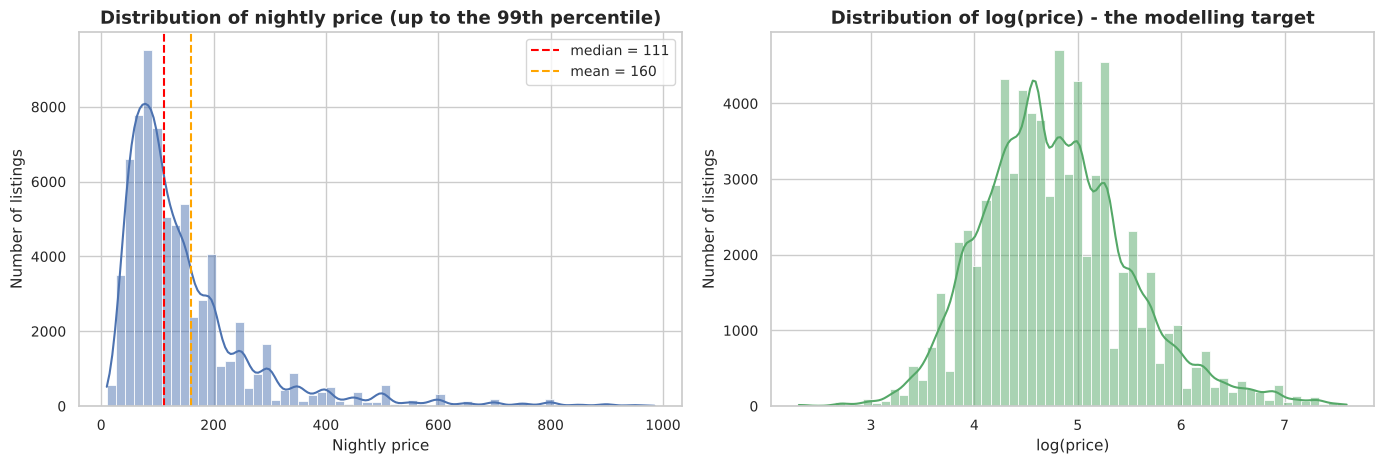

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.histplot(eda.loc[eda["price"] <= PRICE_CAP, "price"], bins=60, kde=True, color="#4C72B0", ax=axes[0])
axes[0].axvline(eda["price"].median(), color="red", ls="--", label=f"median = {eda['price'].median():,.0f}")
axes[0].axvline(eda["price"].mean(), color="orange", ls="--", label=f"mean = {eda['price'].mean():,.0f}")
axes[0].set(title="Distribution of nightly price (up to the 99th percentile)", xlabel="Nightly price", ylabel="Number of listings")
axes[0].legend()
sns.histplot(eda["log_price"], bins=60, kde=True, color="#55A868", ax=axes[1])
axes[1].set(title="Distribution of log(price) - the modelling target", xlabel="log(price)", ylabel="Number of listings")
plt.show()

**Interpretation.** Raw prices are strongly **right-skewed**: most listings are cheap-to-moderate and a long tail is very expensive (the mean sits above the median). After the logarithm the distribution is close to a bell shape, which is much friendlier for regression - that is why the model predicts `log_price`.

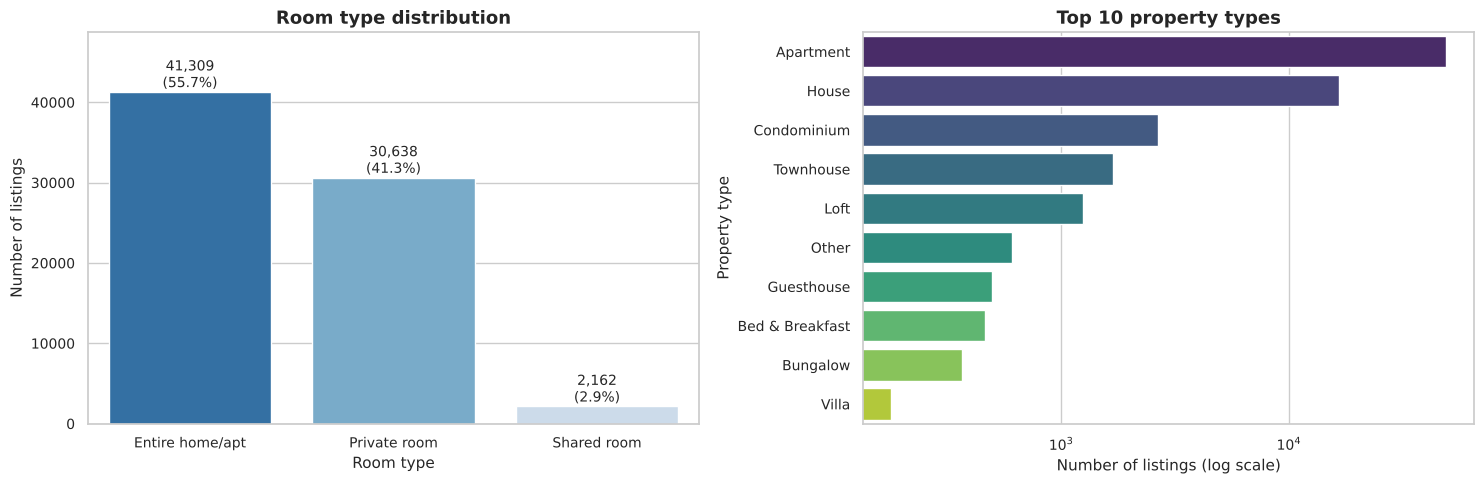

Number of distinct property types: 35


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
rt = eda["room_type"].value_counts().reindex(ROOM_ORDER)
sns.barplot(x=rt.index, y=rt.values, palette="Blues_r", ax=axes[0])
for i, v in enumerate(rt.values):
    axes[0].text(i, v, f"{v:,}\n({v/len(eda):.1%})", ha="center", va="bottom", fontsize=10)
axes[0].set(title="Room type distribution", xlabel="Room type", ylabel="Number of listings")
axes[0].set_ylim(0, rt.max() * 1.18)

pt = eda["property_type"].value_counts().head(10)
sns.barplot(y=pt.index, x=pt.values, palette="viridis", ax=axes[1])
axes[1].set(title="Top 10 property types", xlabel="Number of listings", ylabel="Property type")
axes[1].set_xscale("log")
axes[1].set_xlabel("Number of listings (log scale)")
plt.show()
print("Number of distinct property types:", eda["property_type"].nunique())

**Interpretation.** Most listings are **entire homes** or **private rooms**; shared rooms are rare. Property type is dominated by **apartments and houses**, with a long tail of unusual types (boats, castles, yurts ...). Rare categories have too few examples to learn from reliably - so the encoder will group very rare categories together.

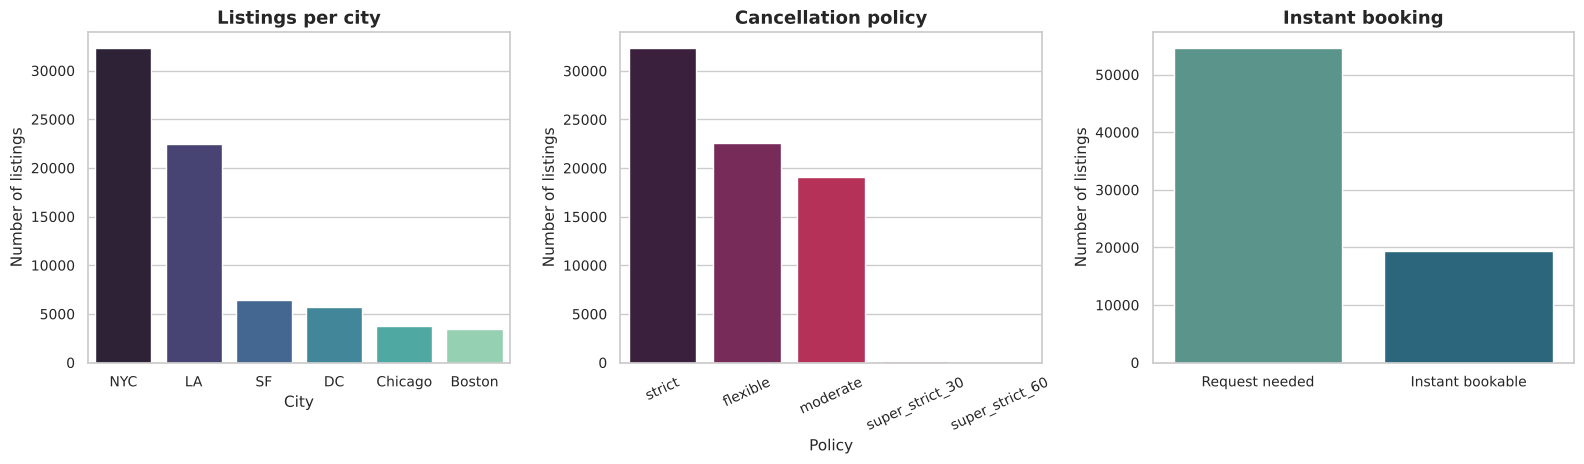

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
city_counts = eda["city"].value_counts()
sns.barplot(x=city_counts.index, y=city_counts.values, palette="mako", ax=axes[0])
axes[0].set(title="Listings per city", xlabel="City", ylabel="Number of listings")
cp = eda["cancellation_policy"].value_counts()
sns.barplot(x=cp.index, y=cp.values, palette="rocket", ax=axes[1])
axes[1].set(title="Cancellation policy", xlabel="Policy", ylabel="Number of listings")
axes[1].tick_params(axis="x", rotation=25)
ib = eda["instant_bookable"].map({"t": "Instant bookable", "f": "Request needed"}).value_counts()
sns.barplot(x=ib.index, y=ib.values, palette="crest", ax=axes[2])
axes[2].set(title="Instant booking", xlabel="", ylabel="Number of listings")
plt.show()

**Availability:** this dataset has **no availability column** (no calendar, no days-available count), so an availability distribution cannot be drawn - and the feature is not invented. 
Instead the chart above shows the other *categorical* variables. The market is dominated by **New York and Los Angeles**, so the model will learn those two cities best; smaller cities (e.g. Boston, Chicago) have fewer examples.

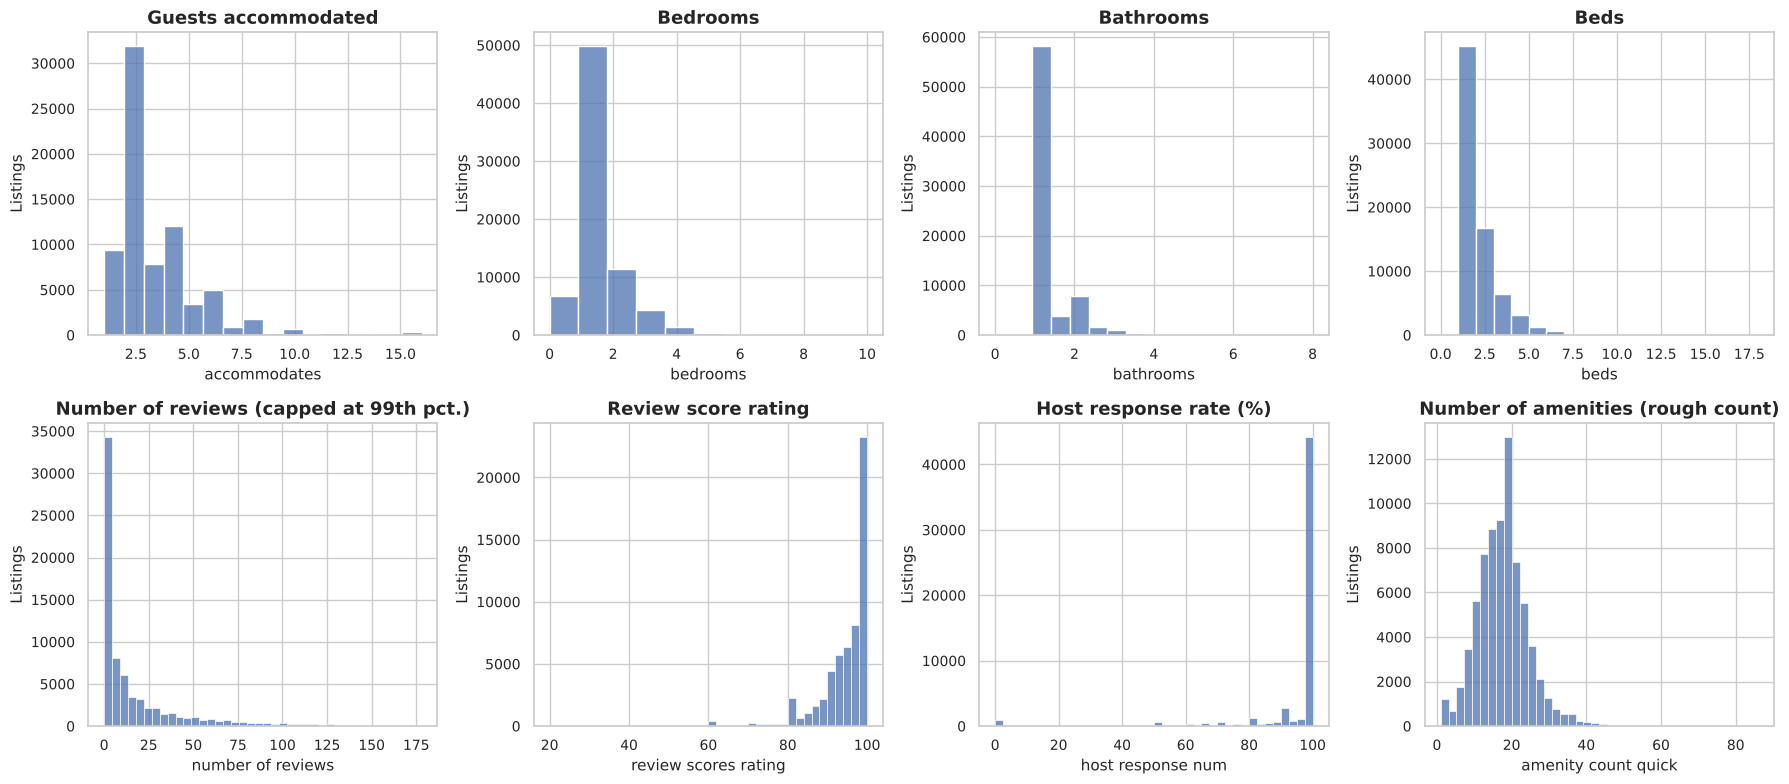

,accommodates,bedrooms,bathrooms,beds,number_of_reviews,review_scores_rating,host_response_num,amenity_count_quick
skewness,2.230,1.990,3.690,3.360,3.700,-3.380,-4.080,0.790


In [19]:
num_plot = ["accommodates", "bedrooms", "bathrooms", "beds", "number_of_reviews", "review_scores_rating", "host_response_num", "amenity_count_quick"]
titles = ["Guests accommodated", "Bedrooms", "Bathrooms", "Beds", "Number of reviews (capped at 99th pct.)",
          "Review score rating", "Host response rate (%)", "Number of amenities (rough count)"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col, title in zip(axes.ravel(), num_plot, titles):
    s = eda[col].dropna()
    if col == "number_of_reviews":
        s = s[s <= s.quantile(0.99)]
    sns.histplot(s, bins=min(40, max(8, s.nunique())), color="#4C72B0", ax=ax)
    ax.set(title=title, xlabel=col.replace("_", " "), ylabel="Listings")
plt.show()
display(eda[num_plot].skew().round(2).to_frame("skewness").T)

**Interpretation.** Most listings host **2 guests** with **1 bedroom, 1 bathroom, 1 bed**. `number_of_reviews` is very skewed (many new listings, a few with hundreds of reviews). Ratings **pile up near 90-100** (people rarely give low scores), so rating differences at the top are small but informative. Host response rate is mostly 100 %. These shapes tell us tree-based models (insensitive to skew) should do well, and that missing review data is common.

### B. Bivariate analysis (feature vs price)

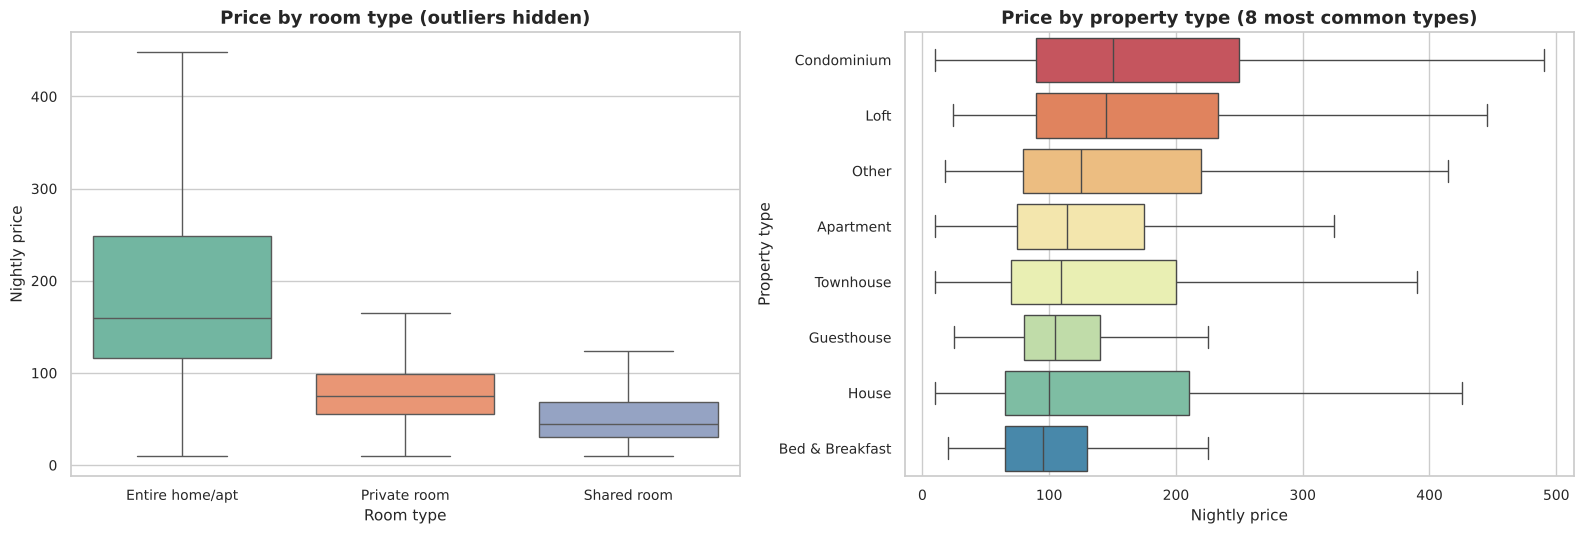

,count,median,mean
room_type,,,
Entire home/apt,41309,160.000,218.751
Private room,30638,75.000,88.488
Shared room,2162,45.000,63.711


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.boxplot(data=eda, x="room_type", y="price", order=ROOM_ORDER, palette="Set2", showfliers=False, ax=axes[0])
axes[0].set(title="Price by room type (outliers hidden)", xlabel="Room type", ylabel="Nightly price")
top8 = eda["property_type"].value_counts().head(8).index
order8 = eda[eda["property_type"].isin(top8)].groupby("property_type")["price"].median().sort_values(ascending=False).index
sns.boxplot(data=eda[eda["property_type"].isin(top8)], x="price", y="property_type", order=order8, palette="Spectral", showfliers=False, ax=axes[1])
axes[1].set(title="Price by property type (8 most common types)", xlabel="Nightly price", ylabel="Property type")
plt.show()
display(eda.groupby("room_type")["price"].agg(["count", "median", "mean"]).reindex(ROOM_ORDER))

**Interpretation.** **Room type is a major price driver:** entire homes cost clearly more than private rooms, which cost more than shared rooms. Property types also differ (e.g. houses / villas / lofts vs apartments / dorms), but part of that difference is really *size and location* showing through - one reason we use models that can combine features.

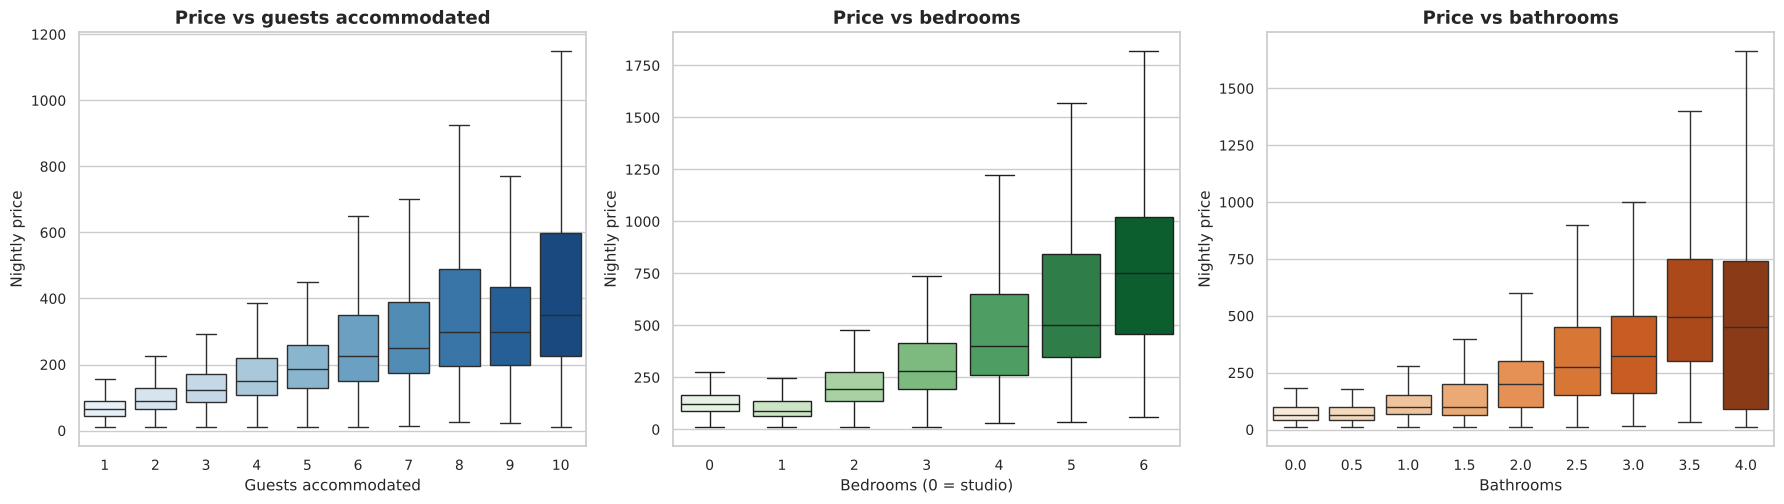

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
acc = eda[eda["accommodates"] <= 10]
sns.boxplot(data=acc, x="accommodates", y="price", palette="Blues", showfliers=False, ax=axes[0])
axes[0].set(title="Price vs guests accommodated", xlabel="Guests accommodated", ylabel="Nightly price")
bd = eda[eda["bedrooms"].between(0, 6)]
sns.boxplot(data=bd, x=bd["bedrooms"].astype(int), y="price", palette="Greens", showfliers=False, ax=axes[1])
axes[1].set(title="Price vs bedrooms", xlabel="Bedrooms (0 = studio)", ylabel="Nightly price")
bt = eda[eda["bathrooms"].between(0, 4)]
sns.boxplot(data=bt, x="bathrooms", y="price", palette="Oranges", showfliers=False, ax=axes[2])
axes[2].set(title="Price vs bathrooms", xlabel="Bathrooms", ylabel="Nightly price")
plt.show()

**Interpretation.** Price **rises steadily with size** - more guests, bedrooms and bathrooms mean higher prices. The *spread* also widens for bigger properties (bigger homes are priced very differently depending on city and quality), so capacity alone cannot give an exact price.

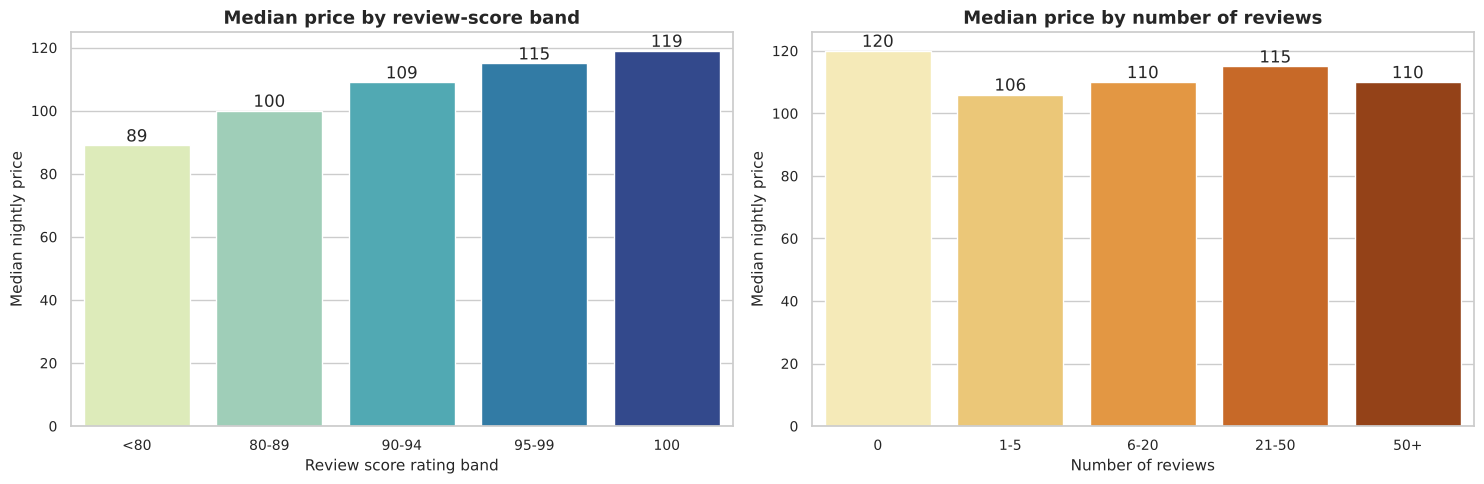

Correlation (Spearman) price vs rating: 0.085 | price vs number_of_reviews: -0.033


In [22]:
rated = eda.dropna(subset=["review_scores_rating"]).copy()
rated["rating band"] = pd.cut(rated["review_scores_rating"], [0, 79, 89, 94, 99, 100],
                              labels=["<80", "80-89", "90-94", "95-99", "100"])
eda["reviews band"] = pd.cut(eda["number_of_reviews"], [-1, 0, 5, 20, 50, 1000], labels=["0", "1-5", "6-20", "21-50", "50+"])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
med = rated.groupby("rating band", observed=True)["price"].median()
sns.barplot(x=med.index.astype(str), y=med.values, palette="YlGnBu", ax=axes[0])
for i, v in enumerate(med.values):
    axes[0].text(i, v, f"{v:,.0f}", ha="center", va="bottom")
axes[0].set(title="Median price by review-score band", xlabel="Review score rating band", ylabel="Median nightly price")
med2 = eda.groupby("reviews band", observed=True)["price"].median()
sns.barplot(x=med2.index.astype(str), y=med2.values, palette="YlOrBr", ax=axes[1])
for i, v in enumerate(med2.values):
    axes[1].text(i, v, f"{v:,.0f}", ha="center", va="bottom")
axes[1].set(title="Median price by number of reviews", xlabel="Number of reviews", ylabel="Median nightly price")
plt.show()
print("Correlation (Spearman) price vs rating:", round(rated[["price", "review_scores_rating"]].corr(method="spearman").iloc[0, 1], 3),
      "| price vs number_of_reviews:", round(eda[["price", "number_of_reviews"]].corr(method="spearman").iloc[0, 1], 3))

**Interpretation.** Review information has only a **weak** link with price (see the small Spearman correlations printed above): the median price changes little across rating bands, and the number of reviews is almost uncorrelated with price. A high rating does not mean a high price - **price is mostly about what and where, not about how well it is rated**. Availability vs price cannot be plotted: the dataset has no availability field.

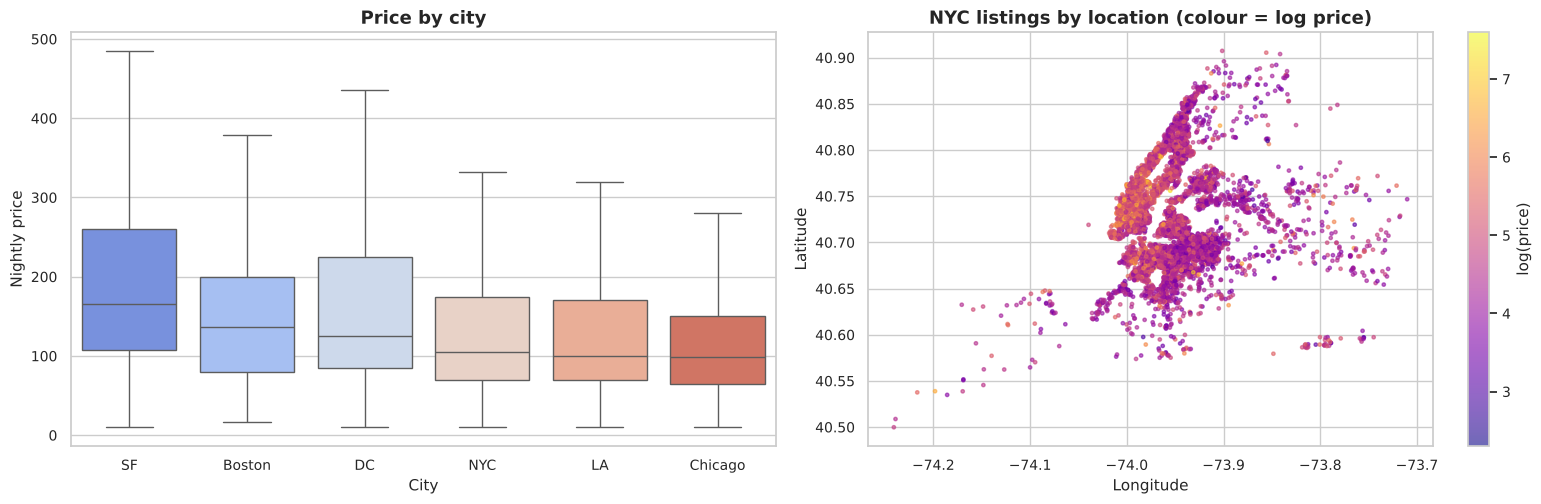

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
order_city = eda.groupby("city")["price"].median().sort_values(ascending=False).index
sns.boxplot(data=eda, x="city", y="price", order=order_city, palette="coolwarm", showfliers=False, ax=axes[0])
axes[0].set(title="Price by city", xlabel="City", ylabel="Nightly price")

# Location map for the biggest market (NYC) - colour = log price
nyc = eda[eda["city"] == "NYC"].sample(min(8000, (eda["city"] == "NYC").sum()), random_state=RANDOM_STATE)
sc = axes[1].scatter(nyc["longitude"], nyc["latitude"], c=nyc["log_price"], cmap="plasma", s=6, alpha=0.6)
plt.colorbar(sc, ax=axes[1], label="log(price)")
axes[1].set(title="NYC listings by location (colour = log price)", xlabel="Longitude", ylabel="Latitude")
plt.show()

**Interpretation.** **City matters a lot** (compare the medians). Inside a city, price depends strongly on **location**: in the New York map the high-priced (bright) listings concentrate in central Manhattan and nearby areas, while outer areas are cheaper. This is why latitude/longitude, neighbourhood and distance-to-centre are valuable features.

### C. Multivariate analysis (many variables together)

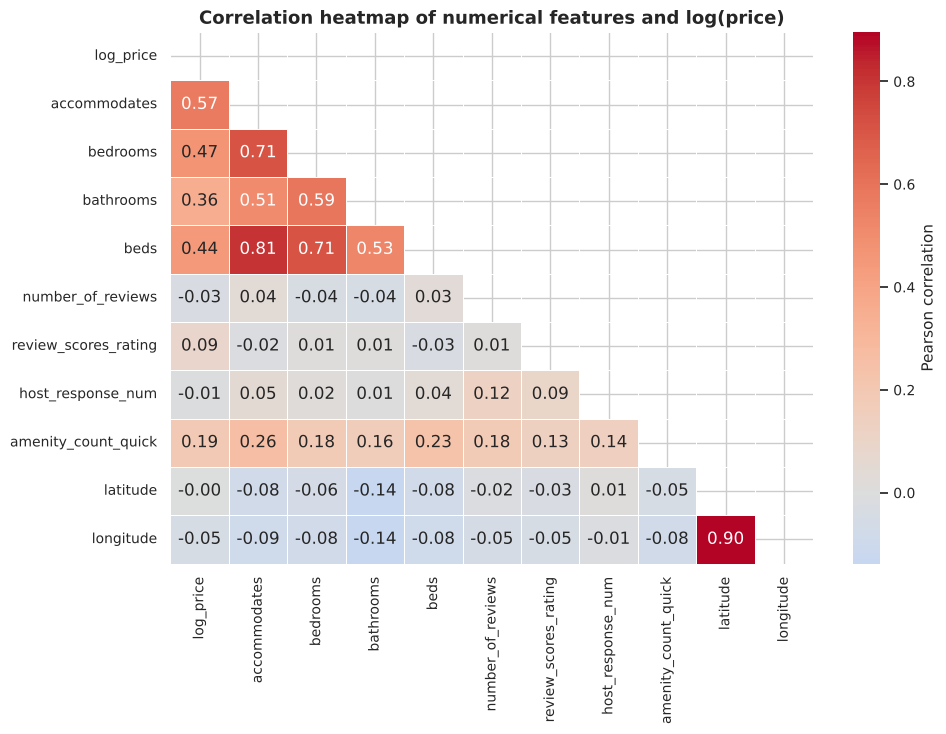

,accommodates,bedrooms,beds,bathrooms,amenity_count_quick,review_scores_rating,latitude,host_response_num,number_of_reviews,longitude
correlation with log_price,0.568,0.473,0.442,0.356,0.194,0.091,-0.002,-0.007,-0.033,-0.047


In [24]:
corr_cols = ["log_price", "accommodates", "bedrooms", "bathrooms", "beds", "number_of_reviews",
             "review_scores_rating", "host_response_num", "amenity_count_quick", "latitude", "longitude"]
corr = eda[corr_cols].corr(method="pearson")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 7.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation heatmap of numerical features and log(price)")
plt.show()
display(corr["log_price"].drop("log_price").sort_values(ascending=False).round(3).to_frame("correlation with log_price").T)

**Interpretation.** Size features (`accommodates`, `bedrooms`, `beds`, `bathrooms`) are the most correlated with price **and strongly correlated with each other** (multicollinearity - they tell a similar story, which can make linear-regression coefficients unstable). Correlation only measures **linear** relationships between numbers: it says nothing about categories like city or room type, or about non-linear/geographic effects - another reason to go beyond correlations.

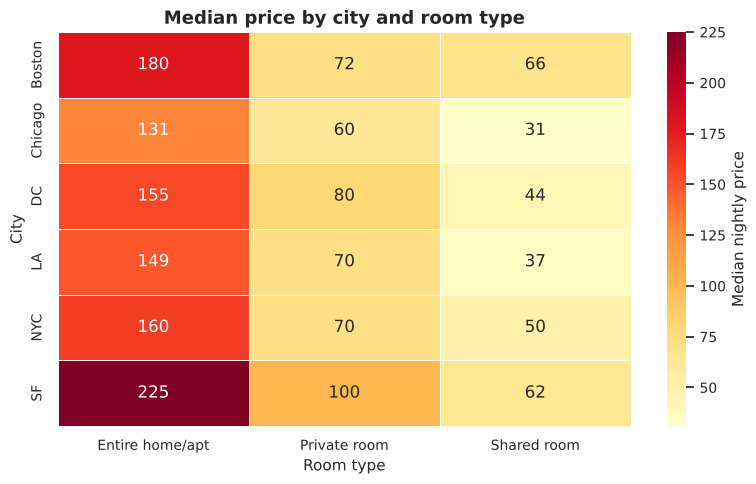

In [25]:
pivot = eda.pivot_table(index="city", columns="room_type", values="price", aggfunc="median")[ROOM_ORDER]
plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5, cbar_kws={"label": "Median nightly price"})
plt.title("Median price by city and room type")
plt.xlabel("Room type"); plt.ylabel("City")
plt.show()

**Interpretation.** The room-type ordering (entire > private > shared) holds in **every city**, but the *level* differs by market. Price is a result of **combinations** (city x room type x size x location) - exactly what flexible models are good at and why we create a `property_type | room_type` combination feature.

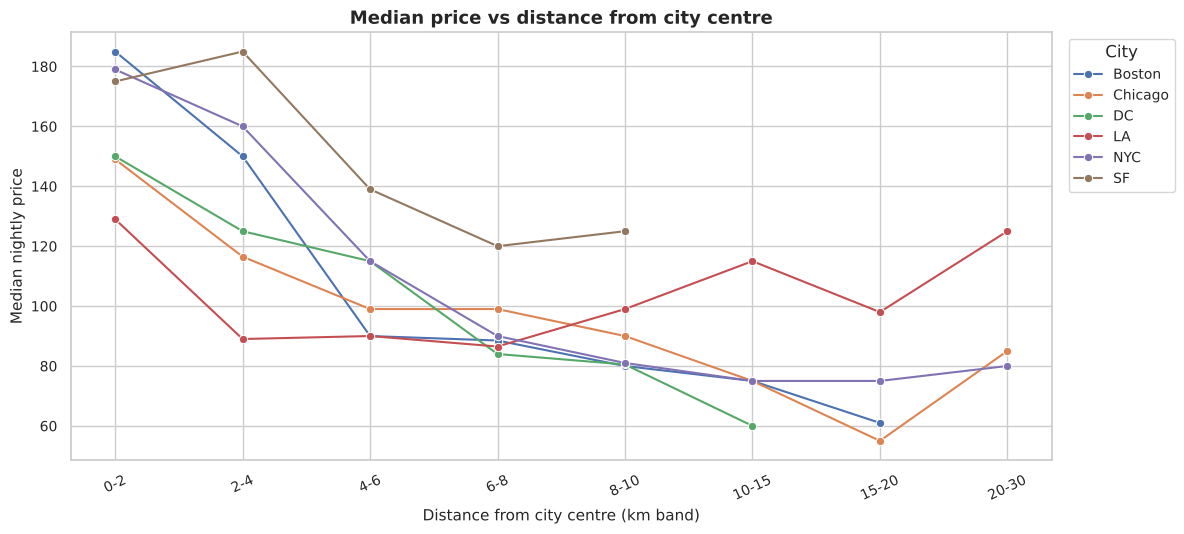

In [26]:
# Price vs distance from the city centre (uses fixed, publicly known city-centre coordinates)
CENTRES = {"NYC": (40.7580, -73.9855), "LA": (34.0522, -118.2437), "SF": (37.7749, -122.4194),
           "DC": (38.9072, -77.0369), "Chicago": (41.8781, -87.6298), "Boston": (42.3601, -71.0589)}
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))
eda["dist_km"] = [haversine(la, lo, *CENTRES[c]) for la, lo, c in zip(eda["latitude"], eda["longitude"], eda["city"])]
eda["dist band"] = pd.cut(eda["dist_km"], [0, 2, 4, 6, 8, 10, 15, 20, 30], include_lowest=True,
                          labels=["0-2", "2-4", "4-6", "6-8", "8-10", "10-15", "15-20", "20-30"])
trend = eda.groupby(["dist band", "city"], observed=True)["price"].median().reset_index()
trend["dist band"] = trend["dist band"].astype(str)
plt.figure(figsize=(12, 5.5))
sns.lineplot(data=trend, x="dist band", y="price", hue="city", marker="o")
plt.title("Median price vs distance from city centre")
plt.xlabel("Distance from city centre (km band)"); plt.ylabel("Median nightly price")
plt.xticks(rotation=25); plt.legend(title="City", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

**Interpretation.** In most cities (Boston, Chicago, DC, NYC, SF) the median price **falls as we move away from the centre**, with different levels per city. Los Angeles is the exception: it is spread out and has attractive areas far from downtown, so its curve is flat or rises again - which is why the model also needs `city`, latitude and longitude and not only the distance. The distance gives us a useful, interpretable **location-derived feature**: `dist_to_centre_km`.

### D. Outlier analysis

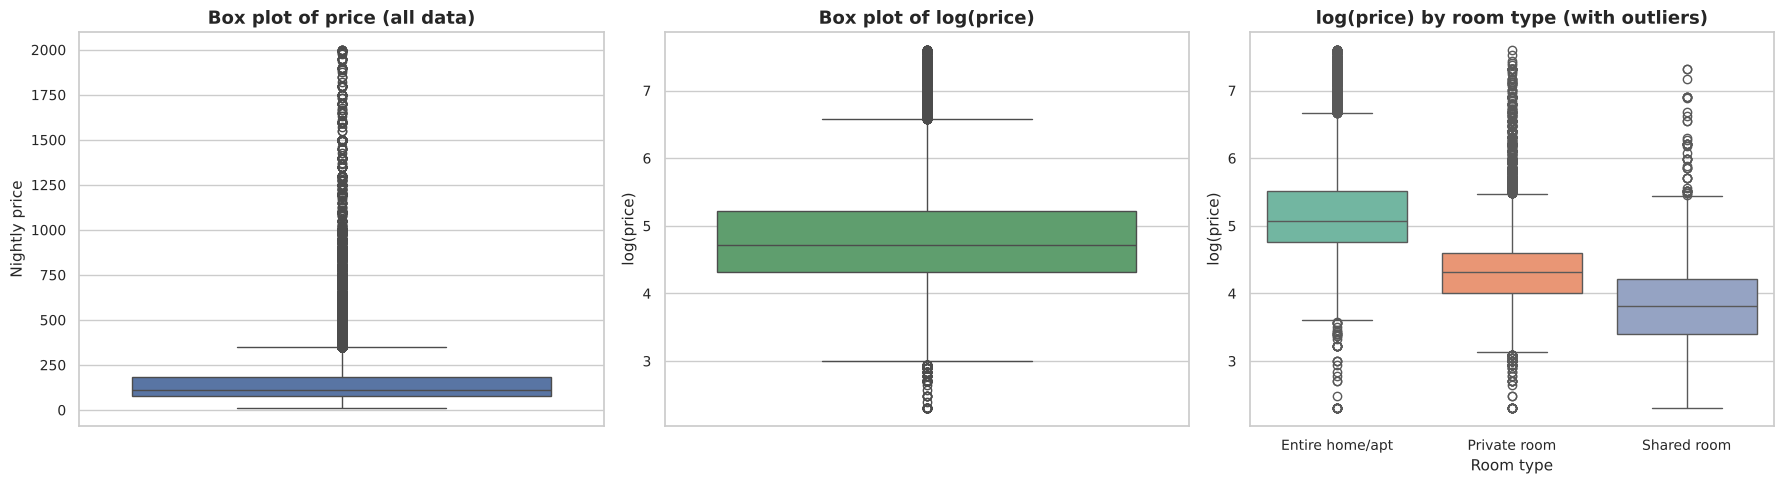

,Q1,Q3,upper fence (Q3+1.5xIQR),outliers,outliers %,max price
room type,,,,,,
Entire home/apt,116.000,249.000,448.500,3367,8.151,"1,999.000"
Private room,55.000,99.000,165.000,1782,5.816,"1,995.000"
Shared room,30.000,68.000,125.000,147,6.799,"1,500.000"


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(y=eda["price"], color="#4C72B0", ax=axes[0])
axes[0].set(title="Box plot of price (all data)", ylabel="Nightly price")
sns.boxplot(y=eda["log_price"], color="#55A868", ax=axes[1])
axes[1].set(title="Box plot of log(price)", ylabel="log(price)")
sns.boxplot(data=eda, x="room_type", y="log_price", order=ROOM_ORDER, palette="Set2", ax=axes[2])
axes[2].set(title="log(price) by room type (with outliers)", xlabel="Room type", ylabel="log(price)")
plt.show()

rows = []
for rt in ROOM_ORDER:
    s = eda.loc[eda["room_type"] == rt, "price"]
    lo, hi = iqr_bounds(s)
    out = s[(s < lo) | (s > hi)]
    rows.append({"room type": rt, "Q1": s.quantile(.25), "Q3": s.quantile(.75), "upper fence (Q3+1.5xIQR)": hi,
                 "outliers": len(out), "outliers %": 100 * len(out) / len(s), "max price": s.max()})
display(pd.DataFrame(rows).set_index("room type"))

**Explanation of extreme prices.** On the raw scale the box plot shows a thick cloud of points above the upper fence (Q3 + 1.5 x IQR) - these are **not mistakes** but large homes, luxury properties and prime locations. On the **log scale** the cloud shrinks a lot and the distribution is nearly symmetric. Decision: keep them, model the log price, and judge errors with MAE/RMSE on both scales.

In [28]:
by_room = eda.groupby("room_type")["price"].median()
by_city = eda.groupby("city")["price"].median().sort_values(ascending=False)
corr_t = corr["log_price"].drop("log_price").sort_values(ascending=False)
display(Markdown(f"""
### EDA summary - most important insights (computed from the data above)

1. **Price is right-skewed**: median **{eda['price'].median():,.0f}** vs mean **{eda['price'].mean():,.0f}**; modelling `log_price` fixes the skew.
2. **Room type** ordering: entire home (median {by_room['Entire home/apt']:,.0f}) > private room ({by_room['Private room']:,.0f}) > shared room ({by_room['Shared room']:,.0f}).
3. **City** matters: most expensive median market is **{by_city.index[0]}** ({by_city.iloc[0]:,.0f}), cheapest is **{by_city.index[-1]}** ({by_city.iloc[-1]:,.0f}).
4. **Size drives price**: the numerical feature most correlated with `log_price` is **{corr_t.index[0]}** (r = {corr_t.iloc[0]:.2f}); the size features are also highly correlated with one another.
5. **Location inside a city matters** (price map, distance-to-centre curve).
6. **Review variables** are only weakly related to price; **availability** is not in this dataset.
7. **Outliers** are mostly genuine luxury/large listings -> kept, handled by the log transform.
8. Missing data is concentrated in **review fields** (listings with no reviews yet), host fields and `neighbourhood` -> imputed inside the pipeline.
"""))


### EDA summary - most important insights (computed from the data above)

1. **Price is right-skewed**: median **111** vs mean **160**; modelling `log_price` fixes the skew.
2. **Room type** ordering: entire home (median 160) > private room (75) > shared room (45).
3. **City** matters: most expensive median market is **SF** (165), cheapest is **Chicago** (99).
4. **Size drives price**: the numerical feature most correlated with `log_price` is **accommodates** (r = 0.57); the size features are also highly correlated with one another.
5. **Location inside a city matters** (price map, distance-to-centre curve).
6. **Review variables** are only weakly related to price; **availability** is not in this dataset.
7. **Outliers** are mostly genuine luxury/large listings -> kept, handled by the log transform.
8. Missing data is concentrated in **review fields** (listings with no reviews yet), host fields and `neighbourhood` -> imputed inside the pipeline.


## 08 - Feature Engineering

**Feature engineering** = creating new, more informative columns from existing ones. Only features that can be computed from columns that really exist in this dataset are created, and each one is available at prediction time (a host can type it in).

| Engineered feature | How it is made | Why it may improve prediction |
|---|---|---|
| `guests_per_bedroom`, `guests_per_bed` | accommodates / bedrooms (beds) | crowding; shows whether space is generous or cramped |
| `bath_per_guest`, `total_rooms` | bathrooms / guests; bedrooms + bathrooms | comfort & overall size |
| `amenity_count` | number of amenities listed | richer listings tend to be priced higher |
| `amen_*` flags (top 25) | 1/0 for the most common amenities (Wifi, Kitchen, Air conditioning, TV, Washer ...) | specific amenities can move the price; vocabulary is learned on **training data only** |
| `dist_to_centre_km` | haversine distance from the city's centre | price falls with distance from the centre (seen in EDA) |
| `property_room` | `property_type \| room_type` | the same property type behaves differently as entire home vs private room |
| `host_tenure_years` | years between `host_since` and the scrape date | experienced hosts price differently |
| `days_since_last_review`, `listing_age_days`, `reviews_per_year`, `has_reviews` | from review dates and counts | review **activity** and "no reviews yet" status |
| cleaned numerics/flags | `host_response_rate` "100%" -> 100; `t/f` -> 1/0; impossible values -> NaN | model-ready data |

**Why a custom class in its own file?** All of this logic is written as a scikit-learn *transformer* (`ListingFeatureEngineer`) with `fit()` and `transform()`. `fit()` learns only from the data it is given (the amenity vocabulary and neighbourhood centroids), so when used inside a Pipeline it sees **training data only**. It lives in `airbnb_features.py` so the saved model can be loaded later from *any* script (pickle stores classes by module name).

In [29]:
%%writefile airbnb_features.py
"""
airbnb_features.py
------------------
Feature engineering used by BOTH the training notebook and the Streamlit app.

Why a separate .py file?
    joblib/pickle stores custom classes *by reference* (module name + class name).
    If the class lived only inside the notebook (module "__main__"), the saved
    model could not be re-loaded from another script such as app.py.
    Keeping it here makes the saved pipeline fully portable.

Everything that LEARNS something from data (the amenity vocabulary and the
neighbourhood centroids) does so in .fit(), i.e. on TRAINING DATA ONLY.
"""
import ast
import re

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

# Reference "today" for date features. The scrape ended on 2017-10-05
# (latest review / host_since date in the data), so we measure time against it.
REFERENCE_DATE = pd.Timestamp("2017-10-05")

# Approximate city-centre coordinates (public domain knowledge, not learned from the target).
CITY_CENTRES = {
    "NYC": (40.7580, -73.9855),      # Times Square
    "LA": (34.0522, -118.2437),      # Downtown LA
    "SF": (37.7749, -122.4194),      # Downtown San Francisco
    "DC": (38.9072, -77.0369),       # Downtown Washington DC
    "Chicago": (41.8781, -87.6298),  # The Loop
    "Boston": (42.3601, -71.0589),   # Downtown Boston
}


def parse_amenities(value):
    """Turn the raw amenities cell into a clean list of strings.

    Raw format in the dataset:  {TV,"Wireless Internet","Air conditioning"}
    The function also accepts a Python list/tuple/set (used by the app/widgets).
    """
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return []
    if isinstance(value, (list, tuple, set)):
        return [str(v).strip() for v in value if str(v).strip()]
    text = str(value).strip().strip("{}")
    if not text:
        return []
    items = re.findall(r'"([^"]+)"|([^,]+)', text)
    out = []
    for quoted, plain in items:
        name = (quoted or plain).strip()
        # drop the dataset's untranslated placeholders such as "translation missing: en.hosting_amenity_49"
        if name and not name.lower().startswith("translation missing"):
            out.append(name)
    return out


def _haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in kilometres (vectorised)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))


def _slug(name):
    return "amen_" + re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")


def _to_bool01(series):
    """'t'/'f', True/False, 1/0, 'true'/'false' -> 1/0 (NaN stays NaN)."""
    mapping = {"t": 1, "true": 1, "1": 1, "yes": 1, "f": 0, "false": 0, "0": 0, "no": 0}
    return series.map(lambda v: np.nan if pd.isna(v) else mapping.get(str(v).strip().lower(), np.nan)).astype(float)


class ListingFeatureEngineer(BaseEstimator, TransformerMixin):
    """Cleans raw listing columns and creates engineered features.

    Learned in fit (training data only):
        * amenity_vocab_      - the `top_amenities` most common amenities
        * neigh_centroids_    - median (lat, lon) of every (city, neighbourhood)
        * city_centroids_     - median (lat, lon) of every city (fallback)
    """

    def __init__(self, top_amenities=25, min_amenity_share=0.02):
        self.top_amenities = top_amenities
        self.min_amenity_share = min_amenity_share

    # ------------------------------------------------------------------ fit
    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()
        # 1) amenity vocabulary
        counts = {}
        for cell in X["amenities"] if "amenities" in X else []:
            for a in set(parse_amenities(cell)):
                counts[a] = counts.get(a, 0) + 1
        n = max(len(X), 1)
        ranked = sorted(counts.items(), key=lambda kv: -kv[1])
        self.amenity_vocab_ = [a for a, c in ranked if c / n >= self.min_amenity_share][: self.top_amenities]

        # 2) location fall-backs
        geo = X[["city", "neighbourhood", "latitude", "longitude"]].dropna(subset=["latitude", "longitude"])
        self.neigh_centroids_ = (geo.dropna(subset=["neighbourhood"])
                                 .groupby(["city", "neighbourhood"])[["latitude", "longitude"]].median())
        self.city_centroids_ = geo.groupby("city")[["latitude", "longitude"]].median()
        return self

    # ------------------------------------------------------------ transform
    def transform(self, X):
        X = pd.DataFrame(X).copy()
        out = pd.DataFrame(index=X.index)

        # ---- categorical columns (missing text -> "Unknown")
        for col in ["city", "property_type", "room_type", "bed_type", "cancellation_policy", "neighbourhood"]:
            out[col] = X[col].astype("object").where(X[col].notna(), "Unknown") if col in X else "Unknown"
            out[col] = out[col].astype(str)
        out["property_room"] = out["property_type"] + " | " + out["room_type"]   # combination feature

        # ---- numeric basics, impossible values -> NaN (imputed later in the pipeline)
        def num(col):
            return pd.to_numeric(X[col], errors="coerce") if col in X else pd.Series(np.nan, index=X.index)

        acc = num("accommodates").where(lambda s: (s >= 1) & (s <= 30))
        bath = num("bathrooms").where(lambda s: (s >= 0) & (s <= 15))
        bed_r = num("bedrooms").where(lambda s: (s >= 0) & (s <= 20))
        beds = num("beds").where(lambda s: (s >= 0) & (s <= 30))
        n_rev = num("number_of_reviews").clip(lower=0)
        rating = num("review_scores_rating").where(lambda s: (s >= 0) & (s <= 100))
        out["accommodates"], out["bathrooms"], out["bedrooms"], out["beds"] = acc, bath, bed_r, beds
        out["number_of_reviews"], out["review_scores_rating"] = n_rev, rating

        # ---- binary flags
        for col in ["cleaning_fee", "instant_bookable", "host_identity_verified", "host_has_profile_pic"]:
            out[col] = _to_bool01(X[col]) if col in X else np.nan
        resp = X["host_response_rate"] if "host_response_rate" in X else pd.Series(np.nan, index=X.index)
        resp = pd.to_numeric(resp.astype(str).str.replace("%", "", regex=False), errors="coerce")
        out["host_response_rate"] = resp.where((resp >= 0) & (resp <= 100))

        # ---- location
        lat = num("latitude").copy()
        lon = num("longitude").copy()
        # fill missing coordinates from the neighbourhood centroid, then the city centroid
        miss = (lat.isna() | lon.isna()).to_numpy()
        if miss.any():
            lat_v, lon_v = lat.to_numpy(dtype=float).copy(), lon.to_numpy(dtype=float).copy()
            cities = X["city"].to_numpy() if "city" in X else np.array([None] * len(X))
            neighs = X["neighbourhood"].to_numpy() if "neighbourhood" in X else np.array([None] * len(X))
            for pos in np.flatnonzero(miss):
                key = (cities[pos], neighs[pos])
                if key in self.neigh_centroids_.index:
                    lat_v[pos], lon_v[pos] = self.neigh_centroids_.loc[key].values
                elif cities[pos] in self.city_centroids_.index:
                    lat_v[pos], lon_v[pos] = self.city_centroids_.loc[cities[pos]].values
            lat = pd.Series(lat_v, index=X.index)
            lon = pd.Series(lon_v, index=X.index)
        out["latitude"], out["longitude"] = lat, lon
        centre = out["city"].map(CITY_CENTRES)
        c_lat = centre.map(lambda t: t[0] if isinstance(t, tuple) else np.nan)
        c_lon = centre.map(lambda t: t[1] if isinstance(t, tuple) else np.nan)
        out["dist_to_centre_km"] = _haversine_km(lat, lon, c_lat, c_lon)

        # ---- ratios / capacity features
        out["guests_per_bedroom"] = acc / bed_r.clip(lower=1)
        out["guests_per_bed"] = acc / beds.clip(lower=1)
        out["bath_per_guest"] = bath / acc
        out["total_rooms"] = bed_r + bath

        # ---- date features (relative to the scrape date)
        def days_since(col):
            if col not in X:
                return pd.Series(np.nan, index=X.index)
            return (REFERENCE_DATE - pd.to_datetime(X[col], errors="coerce")).dt.days

        out["host_tenure_years"] = days_since("host_since") / 365.25
        out["days_since_last_review"] = days_since("last_review")
        out["listing_age_days"] = days_since("first_review")
        # allow the app to pass the engineered values directly instead of dates
        for col in ["host_tenure_years", "days_since_last_review", "listing_age_days"]:
            if col in X:
                direct = pd.to_numeric(X[col], errors="coerce")
                out[col] = out[col].where(out[col].notna(), direct)
        out["has_reviews"] = (n_rev.fillna(0) > 0).astype(int)
        out["reviews_per_year"] = n_rev / (out["listing_age_days"].clip(lower=30) / 365.25)
        out["reviews_per_year"] = out["reviews_per_year"].where(out["has_reviews"] == 1, 0)

        # ---- amenities
        parsed = X["amenities"].map(parse_amenities) if "amenities" in X else pd.Series([[]] * len(X), index=X.index)
        out["amenity_count"] = parsed.map(len)
        for a in self.amenity_vocab_:
            out[_slug(a)] = parsed.map(lambda lst, a=a: int(a in lst))
        return out

    # names used by the notebook to build the ColumnTransformer
    @property
    def amenity_columns_(self):
        return [_slug(a) for a in self.amenity_vocab_]


CATEGORICAL_FEATURES = ["city", "property_type", "room_type", "bed_type", "cancellation_policy",
                        "neighbourhood", "property_room"]
NUMERIC_FEATURES = ["accommodates", "bathrooms", "bedrooms", "beds", "number_of_reviews",
                    "review_scores_rating", "host_response_rate", "latitude", "longitude",
                    "dist_to_centre_km", "guests_per_bedroom", "guests_per_bed", "bath_per_guest",
                    "total_rooms", "host_tenure_years", "days_since_last_review", "listing_age_days",
                    "reviews_per_year", "amenity_count"]
BINARY_FEATURES = ["cleaning_fee", "instant_bookable", "host_identity_verified", "host_has_profile_pic",
                   "has_reviews"]


# =====================================================================================
# Prediction helpers (shared by the notebook widgets, the plain-Python function and app.py)
# =====================================================================================
RAW_INPUT_COLUMNS = ["city", "neighbourhood", "property_type", "room_type", "bed_type", "cancellation_policy",
                     "accommodates", "bedrooms", "beds", "bathrooms", "cleaning_fee", "instant_bookable",
                     "host_identity_verified", "host_has_profile_pic", "host_response_rate", "host_since",
                     "number_of_reviews", "review_scores_rating", "first_review", "last_review",
                     "latitude", "longitude", "amenities"]
# A user cannot type exact dates, so the pipeline also accepts these three ready-made values.
PREDICTION_COLUMNS = RAW_INPUT_COLUMNS + ["host_tenure_years", "days_since_last_review", "listing_age_days"]

CATEGORICAL_INPUTS = ["city", "property_type", "room_type", "bed_type", "cancellation_policy"]
NUMERIC_INPUTS = ["accommodates", "bedrooms", "beds", "bathrooms", "number_of_reviews", "review_scores_rating",
                  "host_response_rate", "host_tenure_years", "days_since_last_review", "listing_age_days"]
BOOLEAN_INPUTS = ["cleaning_fee", "instant_bookable", "host_identity_verified", "host_has_profile_pic"]
OPTIONAL_INPUTS = ["review_scores_rating", "host_response_rate", "host_tenure_years",
                   "days_since_last_review", "listing_age_days"]       # may be left empty (None)


def validate_inputs(inputs, spec):
    """Check user input against the specification learned from the TRAINING data.

    Returns (clean_inputs, warnings). Raises ValueError listing every problem found."""
    errors, warns = [], []
    clean = {}
    d = spec["defaults"]

    for f in CATEGORICAL_INPUTS:
        v = inputs.get(f, d[f])
        if v not in spec["categories"][f]:
            errors.append(f"'{f}' = {v!r} is not valid. Choose one of: {spec['categories'][f]}")
        clean[f] = v

    city = clean["city"]
    neigh = inputs.get("neighbourhood", "Unknown") or "Unknown"
    allowed = ["Unknown"] + spec["neighbourhoods"].get(city, [])
    if neigh not in allowed:
        errors.append(f"'neighbourhood' = {neigh!r} is not known for {city}. Use 'Unknown' or one of the "
                      f"{len(allowed)-1} known neighbourhoods.")
    clean["neighbourhood"] = neigh

    for f in NUMERIC_INPUTS:
        v = inputs.get(f, d.get(f) if f not in OPTIONAL_INPUTS else None)
        if v is None or (isinstance(v, float) and np.isnan(v)):
            if f not in OPTIONAL_INPUTS:
                errors.append(f"'{f}' is required.")
            clean[f] = np.nan
            continue
        try:
            v = float(v)
        except (TypeError, ValueError):
            errors.append(f"'{f}' must be a number (got {v!r}).")
            continue
        lo, hi = spec["ranges"][f]
        if not (lo <= v <= hi):
            errors.append(f"'{f}' = {v} is outside the range seen in training data ({lo} to {hi}).")
        clean[f] = v

    for f in BOOLEAN_INPUTS:
        clean[f] = bool(inputs.get(f, d[f]))

    am = inputs.get("amenities", ())
    clean["amenities"] = parse_amenities(list(am) if not isinstance(am, str) else am)

    if errors:
        raise ValueError("Invalid input:\n  - " + "\n  - ".join(errors))

    # cross-field sanity checks (warnings only)
    if clean["bedrooms"] > clean["accommodates"]:
        warns.append("More bedrooms than guests is unusual; the estimate may be less reliable.")
    if clean["beds"] > 2 * clean["accommodates"]:
        warns.append("Many more beds than guests is unusual; the estimate may be less reliable.")
    if clean["number_of_reviews"] == 0:
        for f in ["review_scores_rating", "days_since_last_review", "listing_age_days"]:
            clean[f] = np.nan                      # a listing without reviews has no rating / review dates
    return clean, warns


def build_input_frame(clean):
    """One-row DataFrame with exactly the columns the saved pipeline expects."""
    row = {c: np.nan for c in PREDICTION_COLUMNS}
    row.update(clean)
    return pd.DataFrame([row], columns=PREDICTION_COLUMNS)


def predict_price(model, spec, **inputs):
    """Validate -> DataFrame -> pipeline.predict -> price (+ typical range)."""
    clean, warns = validate_inputs(inputs, spec)
    log_p = float(model.predict(build_input_frame(clean))[0])
    lo_q, hi_q = spec["residual_quantiles"]                  # 16th / 84th percentile of test residuals (log scale)
    return {"price": float(np.exp(log_p)), "log_price": log_p,
            "low": float(np.exp(log_p + lo_q)), "high": float(np.exp(log_p + hi_q)),
            "warnings": warns, "inputs": clean}


def explain_prediction(model, spec, **inputs):
    """Approximate, one-feature-at-a-time explanation.

    For each input we replace ONLY that input by the 'typical' value from the training data and see how the
    prediction changes. effect = (price with your value) - (price with the typical value).
    This is a what-if analysis, not a causal statement."""
    base = predict_price(model, spec, **inputs)
    clean = base["inputs"]
    d = spec["defaults"]
    groups = {
        "neighbourhood": {"neighbourhood": "Unknown"},
        "room_type": {"room_type": d["room_type"]},
        "property_type": {"property_type": d["property_type"]},
        "bed_type": {"bed_type": d["bed_type"]},
        "cancellation_policy": {"cancellation_policy": d["cancellation_policy"]},
        "accommodates": {"accommodates": d["accommodates"]},
        "bedrooms": {"bedrooms": d["bedrooms"]},
        "beds": {"beds": d["beds"]},
        "bathrooms": {"bathrooms": d["bathrooms"]},
        "cleaning_fee": {"cleaning_fee": d["cleaning_fee"]},
        "instant_bookable": {"instant_bookable": d["instant_bookable"]},
        "host_identity_verified": {"host_identity_verified": d["host_identity_verified"]},
        "amenities": {"amenities": spec["default_amenities"]},
        "review history": {"number_of_reviews": d["number_of_reviews"],
                           "review_scores_rating": d["review_scores_rating"],
                           "days_since_last_review": d["days_since_last_review"],
                           "listing_age_days": d["listing_age_days"]},
    }
    rows = []
    for name, change in groups.items():
        alt = dict(clean)
        alt.update(change)
        alt_log = float(model.predict(build_input_frame(alt))[0])
        shown = ", ".join(f"{k}={clean[k]}" for k in change if k != "amenities") if name != "amenities" \
            else f"{len(clean['amenities'])} amenities"
        rows.append({"factor": name, "your value": shown[:60],
                     "effect on price": base["price"] - float(np.exp(alt_log))})
    out = pd.DataFrame(rows).sort_values("effect on price", key=np.abs, ascending=False).reset_index(drop=True)
    return out

Writing airbnb_features.py


In [30]:
import importlib, airbnb_features
importlib.reload(airbnb_features)
from airbnb_features import (ListingFeatureEngineer, CATEGORICAL_FEATURES, NUMERIC_FEATURES,
                             BINARY_FEATURES, parse_amenities)

# DEMO ONLY: fit on a small sample to *show* what the transformer produces.
# The transformer that is actually used for modelling is fitted later, inside the Pipeline, on the training split only.
demo_fe = ListingFeatureEngineer().fit(df_clean.sample(5000, random_state=RANDOM_STATE))
demo = demo_fe.transform(df_clean.head(5))
print("Raw columns in :", df_clean.shape[1], "  ->  engineered columns out:", demo.shape[1])
print("Amenity vocabulary learned (top 25):", demo_fe.amenity_vocab_[:8], "...")
print("Example raw amenities :", df_clean.loc[0, "amenities"][:90], "...")
print("Parsed                :", parse_amenities(df_clean.loc[0, "amenities"])[:6], "...")
display(demo[["city", "property_room", "accommodates", "bedrooms", "guests_per_bedroom", "dist_to_centre_km",
              "host_tenure_years", "days_since_last_review", "amenity_count", "amen_kitchen", "has_reviews"]])

Raw columns in : 25   ->  engineered columns out: 56
Amenity vocabulary learned (top 25): ['Wireless Internet', 'Kitchen', 'Heating', 'Essentials', 'Smoke detector', 'Air conditioning', 'TV', 'Hangers'] ...
Example raw amenities : {"Wireless Internet","Air conditioning",Kitchen,Heating,"Family/kid friendly",Essentials," ...
Parsed                : ['Wireless Internet', 'Air conditioning', 'Kitchen', 'Heating', 'Family/kid friendly', 'Essentials'] ...


,city,property_room,accommodates,bedrooms,guests_per_bedroom,dist_to_centre_km,host_tenure_years,days_since_last_review,amenity_count,amen_kitchen,has_reviews
0,NYC,Apartment | Entire home/apt,3,1.000,3.000,6.855,5.528,444.000,8,1,1
1,NYC,Apartment | Entire home/apt,7,3.000,2.333,0.950,0.296,12.000,14,1,1
2,NYC,Apartment | Entire home/apt,5,1.000,5.000,6.588,0.945,21.000,18,1,1
3,SF,House | Entire home/apt,4,2.000,2.000,1.121,2.464,NaN,15,1,0
4,DC,Apartment | Entire home/apt,2,0.000,2.000,2.059,2.598,256.000,12,1,1


## 09 - Data Preprocessing (the Pipeline)

After feature engineering, each column group gets the treatment it needs:

| Column group | Missing values | Transformation |
|---|---|---|
| Numerical | **median** (robust to outliers) | **StandardScaler** - *only for Linear Regression* (trees do not need scaling) |
| Binary flags & amenity flags | most frequent value | none (already 0/1) |
| Categorical | the label **"Unknown"** | **One-hot encoding**; categories with fewer than 50 listings are merged into an "infrequent" group, unseen categories at prediction time are handled safely |

All of it is wrapped in a `ColumnTransformer` and then in a `Pipeline` together with the model:

`Pipeline = [ ListingFeatureEngineer -> ColumnTransformer -> Model ]`

When we call `pipeline.fit(X_train, y_train)`, every `fit` step (medians, scaling parameters, category lists, amenity vocabulary) uses **training rows only**; when we call `pipeline.predict(X_test)` the same fitted steps are only *applied*. That is exactly what **prevents data leakage**.

In [31]:
from sklearn.compose import make_column_selector
from sklearn import set_config
set_config(display="diagram")

# Raw columns the pipeline expects (what a user / a CSV row must provide)
RAW_INPUT_COLUMNS = ["city", "neighbourhood", "property_type", "room_type", "bed_type", "cancellation_policy",
                     "accommodates", "bedrooms", "beds", "bathrooms", "cleaning_fee", "instant_bookable",
                     "host_identity_verified", "host_has_profile_pic", "host_response_rate", "host_since",
                     "number_of_reviews", "review_scores_rating", "first_review", "last_review",
                     "latitude", "longitude", "amenities"]
missing_cols = [c for c in RAW_INPUT_COLUMNS if c not in df_clean.columns]
assert not missing_cols, f"Columns missing in the data: {missing_cols}"

X = df_clean[RAW_INPUT_COLUMNS].copy()
y = df_clean["log_price"].copy()
print("Feature table X:", X.shape, "| target y:", y.shape)

def build_preprocessor(scale=False):
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    return ColumnTransformer(transformers=[
        ("num",  Pipeline(numeric_steps), NUMERIC_FEATURES),
        ("bin",  SimpleImputer(strategy="most_frequent"), BINARY_FEATURES),
        ("amen", "passthrough", make_column_selector(pattern="^amen_")),
        ("cat",  Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                           ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                    min_frequency=50, sparse_output=False))]),
         CATEGORICAL_FEATURES),
    ], remainder="drop")

def build_pipeline(model, scale=False):
    return Pipeline([("features", ListingFeatureEngineer()),
                     ("prep", build_preprocessor(scale)),
                     ("model", model)])

# Show the structure of one pipeline
display(build_pipeline(LinearRegression(), scale=True))

Feature table X: (74109, 23) | target y: (74109,)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,top_amenities,25
,min_amenity_share,0.02
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_thres

## 10 - Train-Test Split

### Key ideas (beginner-friendly)

* **Supervised learning** - learning from examples where the right answer (the label) is known. Here: listings with known prices.
* **Regression** - supervised learning where the answer is a *number* (price). (Classification predicts a *category*.)
* **Training data** - the part of the data the model learns from.
* **Testing data** - a separate part the model **never sees** while learning; it simulates *new, unseen listings* and gives an honest score.
* **Why split?** A model can simply memorise its training data. Scores on memorised data are over-optimistic, so we judge it on data it has not seen.
* **`random_state`** - the seed of the random shuffling. Same number -> same split -> reproducible results.
* **Overfitting** - the model memorises noise: *excellent on training data, much worse on test data*.
* **Underfitting** - the model is too simple to capture the pattern: *poor on both*.

### Our split: 80 % train / 20 % test
We **stratify by city** so that every city has the same share in both parts. The test set is locked away: it is **not** used for training, fitting preprocessing, choosing features, or tuning hyper-parameters (we use cross-validation *inside the training set* for that).

### Should we use a group-based split instead?
If several listings of the *same host* (or the same building) were spread across train and test, the model could recognise them and the test score would be too optimistic. **This dataset has no host-id column**, so host-based grouping is impossible. Listings from the same *neighbourhood* do share information, but that is legitimate: the real use case is pricing a **new listing in an area we already know**. A random (stratified) split therefore matches the real use case. As an extra robustness check, Section 14 also tests a harder **neighbourhood-group split** (predicting for areas the model has never seen) to check whether performance holds up.

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=df_clean["city"])

print(f"Training set: {X_train.shape[0]:,} rows ({X_train.shape[0]/len(X):.0%})")
print(f"Test set    : {X_test.shape[0]:,} rows ({X_test.shape[0]/len(X):.0%})")
print("Index overlap between train and test:", len(set(X_train.index) & set(X_test.index)), "(must be 0)")

check = pd.DataFrame({
    "train share": X_train["city"].value_counts(normalize=True),
    "test share":  X_test["city"].value_counts(normalize=True)})
display(check.style.format("{:.2%}"))
print(f"log_price mean/std  train: {y_train.mean():.3f} / {y_train.std():.3f}   test: {y_test.mean():.3f} / {y_test.std():.3f}")

Training set: 59,287 rows (80%)
Test set    : 14,822 rows (20%)
Index overlap between train and test: 0 (must be 0)


,train share,test share
city,,
NYC,43.65%,43.64%
LA,30.30%,30.30%
SF,8.68%,8.68%
DC,7.67%,7.68%
Chicago,5.02%,5.02%
Boston,4.68%,4.68%


log_price mean/std  train: 4.784 / 0.715   test: 4.776 / 0.723


## 11 - Model Training

All models predict `log_price` and are wrapped in the **same pipeline** (only the scaler differs for Linear Regression).

| Model | How it works (simple explanation) | Strengths / weaknesses |
|---|---|---|
| **Baseline (median)** | always predicts the median training price | the "dumb guess" any real model must beat |
| **Linear Regression** | fits one straight-line equation: `price = b0 + b1*x1 + b2*x2 + ...` | fast, very interpretable; cannot capture interactions (e.g. a bedroom is worth more in Manhattan than in a small town) |
| **Decision Tree** | a flowchart of yes/no questions ("accommodates > 4?") that ends in a price | easy to visualise; a single deep tree overfits, so we limit its depth |
| **Random Forest** | averages **many** trees, each trained on a random part of the data/features (*bagging*) | accurate, robust, less overfitting than one tree; large & slower |
| **Gradient Boosting** | builds trees **one after another**, each fixing the errors of the previous ones | very accurate; sensitive to settings; slower to train |
| **HistGradientBoosting** | a fast, modern gradient-boosting that groups values into histogram bins | usually the best accuracy/speed trade-off on large tables |
| *XGBoost (optional)* | a popular optimised gradient-boosting library | used only if installed |

In [33]:
def make_models(quick=False):
    models = {
        "Baseline (median)":      (DummyRegressor(strategy="median"), False),
        "Linear Regression":      (LinearRegression(), True),
        "Decision Tree":          (DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=RANDOM_STATE), False),
        "Random Forest":          (RandomForestRegressor(n_estimators=40 if quick else 100, min_samples_leaf=3, max_features=0.33,
                                                         n_jobs=-1, random_state=RANDOM_STATE), False),
        "Gradient Boosting":      (GradientBoostingRegressor(n_estimators=80 if quick else 200, max_depth=4, learning_rate=0.1,
                                                             subsample=0.8, random_state=RANDOM_STATE), False),
        "HistGradientBoosting":   (HistGradientBoostingRegressor(max_iter=150 if quick else 300, learning_rate=0.1,
                                                                 random_state=RANDOM_STATE), False),
    }
    if XGBRegressor is not None:
        models["XGBoost"] = (XGBRegressor(n_estimators=150 if quick else 300, max_depth=6, learning_rate=0.1,
                                          subsample=0.8, tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE), False)
    return models

def regression_report(y_true_log, y_pred_log):
    # Metrics on the log scale (what the model optimises) AND on the real price scale.
    yt, yp = np.exp(np.asarray(y_true_log)), np.exp(np.asarray(y_pred_log))
    return {
        "MAE (log)":   mean_absolute_error(y_true_log, y_pred_log),
        "MSE (log)":   mean_squared_error(y_true_log, y_pred_log),
        "RMSE (log)":  np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        "R2 (log)":    r2_score(y_true_log, y_pred_log),
        "MAE (price)": mean_absolute_error(yt, yp),
        "MSE (price)": mean_squared_error(yt, yp),
        "RMSE (price)": np.sqrt(mean_squared_error(yt, yp)),
        "R2 (price)":  r2_score(yt, yp),
    }

model_specs = make_models(QUICK_RUN)
if XGBRegressor is None:
    print("XGBoost is not installed -> skipped (optional).  Install with: pip install xgboost")

fitted, fit_times, train_reports, test_reports, test_preds = {}, {}, {}, {}, {}
for name, (estimator, scale) in model_specs.items():
    pipe = build_pipeline(estimator, scale)
    t0 = time.time()
    pipe.fit(X_train, y_train)                    # preprocessing is fitted on TRAINING data only
    fit_times[name] = time.time() - t0
    fitted[name] = pipe
    train_reports[name] = regression_report(y_train, pipe.predict(X_train))
    test_preds[name] = pipe.predict(X_test)       # test predictions
    test_reports[name] = regression_report(y_test, test_preds[name])
    print(f"{name:<24} trained in {fit_times[name]:6.1f} s | test RMSE(log) = {test_reports[name]['RMSE (log)']:.4f}")

n_features_out = fitted["Linear Regression"].named_steps["prep"].get_feature_names_out().shape[0]
print(f"\nThe preprocessing produced {n_features_out} model input columns from {len(RAW_INPUT_COLUMNS)} raw columns.")

XGBoost is not installed -> skipped (optional).  Install with: pip install xgboost


Baseline (median)        trained in    1.9 s | test RMSE(log) = 0.7257


Linear Regression        trained in    2.6 s | test RMSE(log) = 0.4138


Decision Tree            trained in    2.5 s | test RMSE(log) = 0.4317


Random Forest            trained in   28.3 s | test RMSE(log) = 0.3909


Gradient Boosting        trained in   99.6 s | test RMSE(log) = 0.3931


HistGradientBoosting     trained in   23.1 s | test RMSE(log) = 0.3828

The preprocessing produced 325 model input columns from 23 raw columns.


In [34]:
# ---- Overfitting demonstration: an UNRESTRICTED decision tree (not a candidate model) ----
deep = build_pipeline(DecisionTreeRegressor(max_depth=None, min_samples_leaf=1, random_state=RANDOM_STATE))
deep.fit(X_train, y_train)
demo_tbl = pd.DataFrame({
    "Unrestricted tree (overfits)": [r2_score(y_train, deep.predict(X_train)), r2_score(y_test, deep.predict(X_test))],
    "Decision Tree, depth<=12 (used)": [train_reports["Decision Tree"]["R2 (log)"], test_reports["Decision Tree"]["R2 (log)"]],
}, index=["R2 on TRAIN data", "R2 on TEST data"])
display(demo_tbl)
print("A huge gap between train and test R2 = overfitting. Limiting depth / leaf size is a way to control it.")
del deep

,Unrestricted tree (overfits),"Decision Tree, depth<=12 (used)"
R2 on TRAIN data,1.000,0.716
R2 on TEST data,0.417,0.644


A huge gap between train and test R2 = overfitting. Limiting depth / leaf size is a way to control it.


## 12 - Model Comparison

**How we choose the model (rules fixed before looking at results):**
1. The primary criterion is the **3-fold cross-validated RMSE on the training set** (several mini train/validation splits inside the training data), *not* training accuracy and *not* the test set.
2. We also check the **generalisation gap** (train vs test) and the practical side: speed, size, interpretability.
3. The test scores are reported for all models for transparency, but they are **not used to pick or tune** the model.

**Cross-validation (CV)** splits the training data into *k* parts; each part is used once as a validation set while the model trains on the others, and the scores are averaged. It is a more stable estimate than a single split.

In [35]:
CV_FOLDS = 2 if QUICK_RUN else 3
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

cv_scores = {}
for name, (estimator, scale) in model_specs.items():
    t0 = time.time()
    s = -cross_val_score(build_pipeline(estimator, scale), X_train, y_train, cv=cv,
                         scoring="neg_root_mean_squared_error", n_jobs=1)
    cv_scores[name] = s
    print(f"{name:<24} CV RMSE(log) = {s.mean():.4f} +/- {s.std():.4f}   ({time.time()-t0:5.0f} s)")

Baseline (median)        CV RMSE(log) = 0.7186 +/- 0.0009   (    6 s)


Linear Regression        CV RMSE(log) = 0.4092 +/- 0.0031   (    7 s)


Decision Tree            CV RMSE(log) = 0.4305 +/- 0.0021   (    7 s)


Random Forest            CV RMSE(log) = 0.3859 +/- 0.0031   (   58 s)


Gradient Boosting        CV RMSE(log) = 0.3855 +/- 0.0016   (  143 s)


HistGradientBoosting     CV RMSE(log) = 0.3767 +/- 0.0030   (   37 s)


,Model,CV RMSE (log),CV std,Train RMSE (log),Test RMSE (log),Test R2 (log),Test MAE (price),Test RMSE (price),Test R2 (price),Train-Test R2 gap,Fit time (s)
0,HistGradientBoosting,0.3767,0.0030,0.3367,0.3828,0.7200,49.3997,115.4725,0.5424,0.0586,23.0523
1,Gradient Boosting,0.3855,0.0016,0.3695,0.3931,0.7047,50.6057,118.1680,0.5207,0.0286,99.6390
2,Random Forest,0.3859,0.0031,0.2259,0.3909,0.7080,50.1963,118.4668,0.5183,0.1923,28.3099
3,Linear Regression,0.4092,0.0031,0.4044,0.4138,0.6729,53.4106,124.5837,0.4673,0.0077,2.5803
4,Decision Tree,0.4305,0.0021,0.3813,0.4317,0.6439,55.6090,124.4420,0.4685,0.0721,2.5190
5,Baseline (median),0.7186,0.0009,0.7185,0.7257,-0.0063,88.4771,177.3605,-0.0796,-0.0020,1.8523


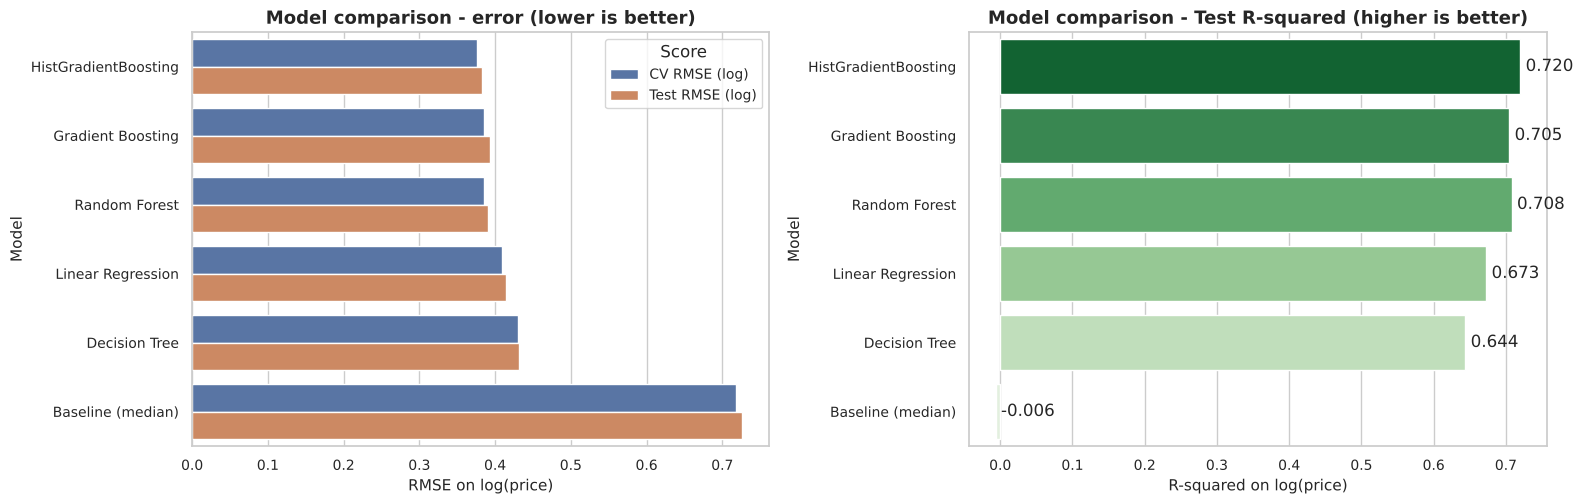

Selected candidate for tuning (lowest CV RMSE): HistGradientBoosting
Runner-up: Gradient Boosting
Linear Regression is +8.6% worse in CV RMSE than the winner but is the most interpretable model.


In [36]:
rows = []
for name in model_specs:
    rows.append({
        "Model": name,
        "CV RMSE (log)": cv_scores[name].mean(),
        "CV std": cv_scores[name].std(),
        "Train RMSE (log)": train_reports[name]["RMSE (log)"],
        "Test RMSE (log)": test_reports[name]["RMSE (log)"],
        "Test R2 (log)": test_reports[name]["R2 (log)"],
        "Test MAE (price)": test_reports[name]["MAE (price)"],
        "Test RMSE (price)": test_reports[name]["RMSE (price)"],
        "Test R2 (price)": test_reports[name]["R2 (price)"],
        "Train-Test R2 gap": train_reports[name]["R2 (log)"] - test_reports[name]["R2 (log)"],
        "Fit time (s)": fit_times[name],
    })
comparison = pd.DataFrame(rows).sort_values("CV RMSE (log)").reset_index(drop=True)
display(comparison.style.format(precision=4).background_gradient(subset=["CV RMSE (log)"], cmap="Greens_r")
        .background_gradient(subset=["Test R2 (log)"], cmap="Greens"))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
plot_df = comparison.melt(id_vars="Model", value_vars=["CV RMSE (log)", "Test RMSE (log)"], var_name="Score", value_name="RMSE (log price)")
sns.barplot(data=plot_df, y="Model", x="RMSE (log price)", hue="Score", palette=["#4C72B0", "#DD8452"], ax=axes[0])
axes[0].set(title="Model comparison - error (lower is better)", xlabel="RMSE on log(price)", ylabel="Model")
sns.barplot(data=comparison, y="Model", x="Test R2 (log)", palette="Greens_r", ax=axes[1])
axes[1].set(title="Model comparison - Test R-squared (higher is better)", xlabel="R-squared on log(price)", ylabel="Model")
for p in axes[1].patches:
    axes[1].text(p.get_width(), p.get_y() + p.get_height()/2, f" {p.get_width():.3f}", va="center")
plt.show()

# ---- Selection (candidates exclude the baseline) ----
candidates = comparison[comparison["Model"] != "Baseline (median)"]
best_name = candidates.iloc[0]["Model"]
runner_up = candidates.iloc[1]["Model"]
print(f"Selected candidate for tuning (lowest CV RMSE): {best_name}")
print(f"Runner-up: {runner_up}")
print(f"Linear Regression is {comparison.loc[comparison['Model']=='Linear Regression','CV RMSE (log)'].iloc[0] / candidates.iloc[0]['CV RMSE (log)'] - 1:+.1%} "
      f"worse in CV RMSE than the winner but is the most interpretable model.")

**How to read the table.** All models beat the median **baseline** by a wide margin, which proves the features carry real information. The boosted/ensemble tree models capture **non-linear effects and interactions** (e.g. location x size) that a straight-line model cannot. Check the **Train-Test R² gap**: a large gap (typically the deep/flexible models) warns of overfitting; a small gap means the model generalises well. The CV column agrees with the test column, which is evidence that the choice is not luck.

## 13 - Hyperparameter Tuning

**Parameters vs hyper-parameters.** *Parameters* are learned from data (e.g. the split points inside a tree). *Hyper-parameters* are settings **we choose before training** (e.g. how many trees, how fast to learn, how deep a tree may grow). Good values reduce both underfitting and overfitting.

| Hyper-parameter | Meaning |
|---|---|
| `learning_rate` | size of each boosting step - small = careful & slower, large = fast but risky |
| `max_iter` / `n_estimators` | number of trees |
| `max_leaf_nodes` / `max_depth` | how complex each tree may be (more = more flexible, more overfitting risk) |
| `min_samples_leaf` | minimum listings per leaf - larger values smooth the model |
| `l2_regularization` | penalty that shrinks extreme leaf values |
| `max_features` / `subsample` | share of features / rows each tree may use (adds randomness, reduces overfitting) |

**Method: `RandomizedSearchCV`** tries a limited number of random combinations (cheaper than trying every combination in a grid), scoring each with **cross-validation on the training set only**. The test set is not touched. We use the *same* CV folds as in Section 12, so the baseline and tuned scores are directly comparable. The tuned model is adopted **only if** it improves the CV score.

In [37]:
from sklearn.base import clone

SEARCH_SPACES = {
    "HistGradientBoosting": {"learning_rate": [0.03, 0.05, 0.08, 0.1], "max_iter": [200, 300, 500],
                             "max_leaf_nodes": [31, 63, 127], "min_samples_leaf": [20, 40, 80],
                             "l2_regularization": [0.0, 0.1, 1.0], "max_depth": [None, 8, 12]},
    "Gradient Boosting":    {"n_estimators": [150, 250, 350], "learning_rate": [0.05, 0.1, 0.15],
                             "max_depth": [3, 4, 5, 6], "min_samples_leaf": [5, 20, 50], "subsample": [0.7, 0.8, 1.0]},
    "Random Forest":        {"n_estimators": [100, 200], "max_features": [0.2, 0.33, 0.5],
                             "min_samples_leaf": [1, 3, 5, 10], "max_depth": [None, 20, 30]},
    "Decision Tree":        {"max_depth": [8, 10, 12, 16, 20], "min_samples_leaf": [5, 10, 20, 50]},
    "XGBoost":              {"n_estimators": [200, 300, 500], "learning_rate": [0.03, 0.05, 0.1],
                             "max_depth": [4, 6, 8], "subsample": [0.7, 0.85, 1.0], "min_child_weight": [1, 5, 10]},
}
N_ITER = 3 if QUICK_RUN else 6

baseline_pipe = fitted[best_name]
baseline_cv   = cv_scores[best_name].mean()
space = SEARCH_SPACES.get(best_name)

if not space:
    print(f"{best_name} has no hyper-parameters worth tuning -> keeping the baseline pipeline.")
    tuned_pipe, tuned_cv, search = baseline_pipe, baseline_cv, None
else:
    estimator, scale = model_specs[best_name]
    search = RandomizedSearchCV(
        build_pipeline(clone(estimator), scale),
        param_distributions={f"model__{k}": v for k, v in space.items()},
        n_iter=N_ITER, cv=cv, scoring="neg_root_mean_squared_error",
        random_state=RANDOM_STATE, n_jobs=1, refit=True, verbose=1)
    t0 = time.time()
    search.fit(X_train, y_train)                          # training data only
    print(f"Search finished in {time.time()-t0:.0f} s")
    tuned_pipe, tuned_cv = search.best_estimator_, -search.best_score_

    res = pd.DataFrame(search.cv_results_)
    res["CV RMSE (log)"] = -res["mean_test_score"]
    res["params"] = res["params"].apply(lambda d: {k.replace("model__", ""): v for k, v in d.items()})
    display(res.sort_values("CV RMSE (log)")[["CV RMSE (log)", "params"]].head(6).reset_index(drop=True))
    print("Best parameters:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})

print(f"\nBaseline {best_name}: CV RMSE = {baseline_cv:.4f}")
print(f"Tuned    {best_name}: CV RMSE = {tuned_cv:.4f}")

if tuned_cv < baseline_cv:
    final_model, final_name = tuned_pipe, f"{best_name} (tuned)"
    print("-> Tuning improved the cross-validated score: the TUNED model is adopted.")
else:
    final_model, final_name = baseline_pipe, best_name
    print("-> Tuning did not improve the cross-validated score: the default model is kept.")

Fitting 3 folds for each of 6 candidates, totalling 18 fits


Search finished in 391 s


,CV RMSE (log),params
0,0.374,"{'min_samples_leaf': 20, 'max_leaf_nodes': 63,..."
1,0.374,"{'min_samples_leaf': 40, 'max_leaf_nodes': 127..."
2,0.376,"{'min_samples_leaf': 80, 'max_leaf_nodes': 63,..."
3,0.377,"{'min_samples_leaf': 80, 'max_leaf_nodes': 127..."
4,0.378,"{'min_samples_leaf': 20, 'max_leaf_nodes': 31,..."
5,0.380,"{'min_samples_leaf': 20, 'max_leaf_nodes': 63,..."


Best parameters: {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 500, 'max_depth': None, 'learning_rate': 0.05, 'l2_regularization': 0.0}

Baseline HistGradientBoosting: CV RMSE = 0.3767
Tuned    HistGradientBoosting: CV RMSE = 0.3737
-> Tuning improved the cross-validated score: the TUNED model is adopted.


## 14 - Model Evaluation

The final model was selected using **only training data** (cross-validation). Only now do we evaluate it on the untouched test set.

### The four metrics in simple words

| Metric | Formula idea | Meaning for Airbnb prices |
|---|---|---|
| **MAE** - Mean Absolute Error | average of &#124;actual - predicted&#124; | "On average the prediction is off by this many price units." Easy to understand; treats all errors equally. |
| **MSE** - Mean Squared Error | average of (actual - predicted)² | Squares the errors, so big mistakes are punished heavily. Units are squared (hard to read). |
| **RMSE** - Root MSE | square root of MSE | Like MAE but more sensitive to large errors; back in normal units. RMSE >= MAE always; a big gap means some very large errors. |
| **R² score** | 1 - (model error / error of always guessing the mean) | The *share of the price variation* the model explains. 1 = perfect, 0 = no better than guessing the average. |

> ⚠️ **R² is NOT "percentage accuracy".** R² = 0.73 does **not** mean "73 % of predictions are correct". Regression predicts numbers that are never exactly right; we measure *how far off* they are. Accuracy / precision / recall belong to **classification**.

We report the metrics on the **log-price** scale (what the model optimises; an error of 0.1 is roughly 10 %) and on the **real price** scale (more intuitive). 

In [38]:
final_pred = final_model.predict(X_test)
final_report = regression_report(y_test, final_pred)
baseline_report = test_reports["Baseline (median)"]

summary = pd.DataFrame({
    "Median baseline": baseline_report,
    f"{best_name} (default)": test_reports[best_name],
    f"FINAL: {final_name}": final_report,
}).T
display(summary.style.format(precision=4))

resid = y_test.values - final_pred                       # residual = actual - predicted (log scale)
price_true, price_pred = np.exp(y_test.values), np.exp(final_pred)
abs_pct = np.abs(price_pred - price_true) / price_true
print(f"Median absolute % error : {np.median(abs_pct):.1%}")
print(f"Predictions within +/-25% of the real price: {np.mean(abs_pct <= 0.25):.1%}")
print(f"Predictions within +/-50% of the real price: {np.mean(abs_pct <= 0.50):.1%}")

,MAE (log),MSE (log),RMSE (log),R2 (log),MAE (price),MSE (price),RMSE (price),R2 (price)
Median baseline,0.5640,0.5267,0.7257,-0.0063,88.4771,31456.7301,177.3605,-0.0796
HistGradientBoosting (default),0.2757,0.1465,0.3828,0.7200,49.3997,13333.8966,115.4725,0.5424
FINAL: HistGradientBoosting (tuned),0.2731,0.1450,0.3808,0.7230,49.0791,13344.8554,115.5199,0.5420


Median absolute % error : 20.5%
Predictions within +/-25% of the real price: 58.5%
Predictions within +/-50% of the real price: 85.7%


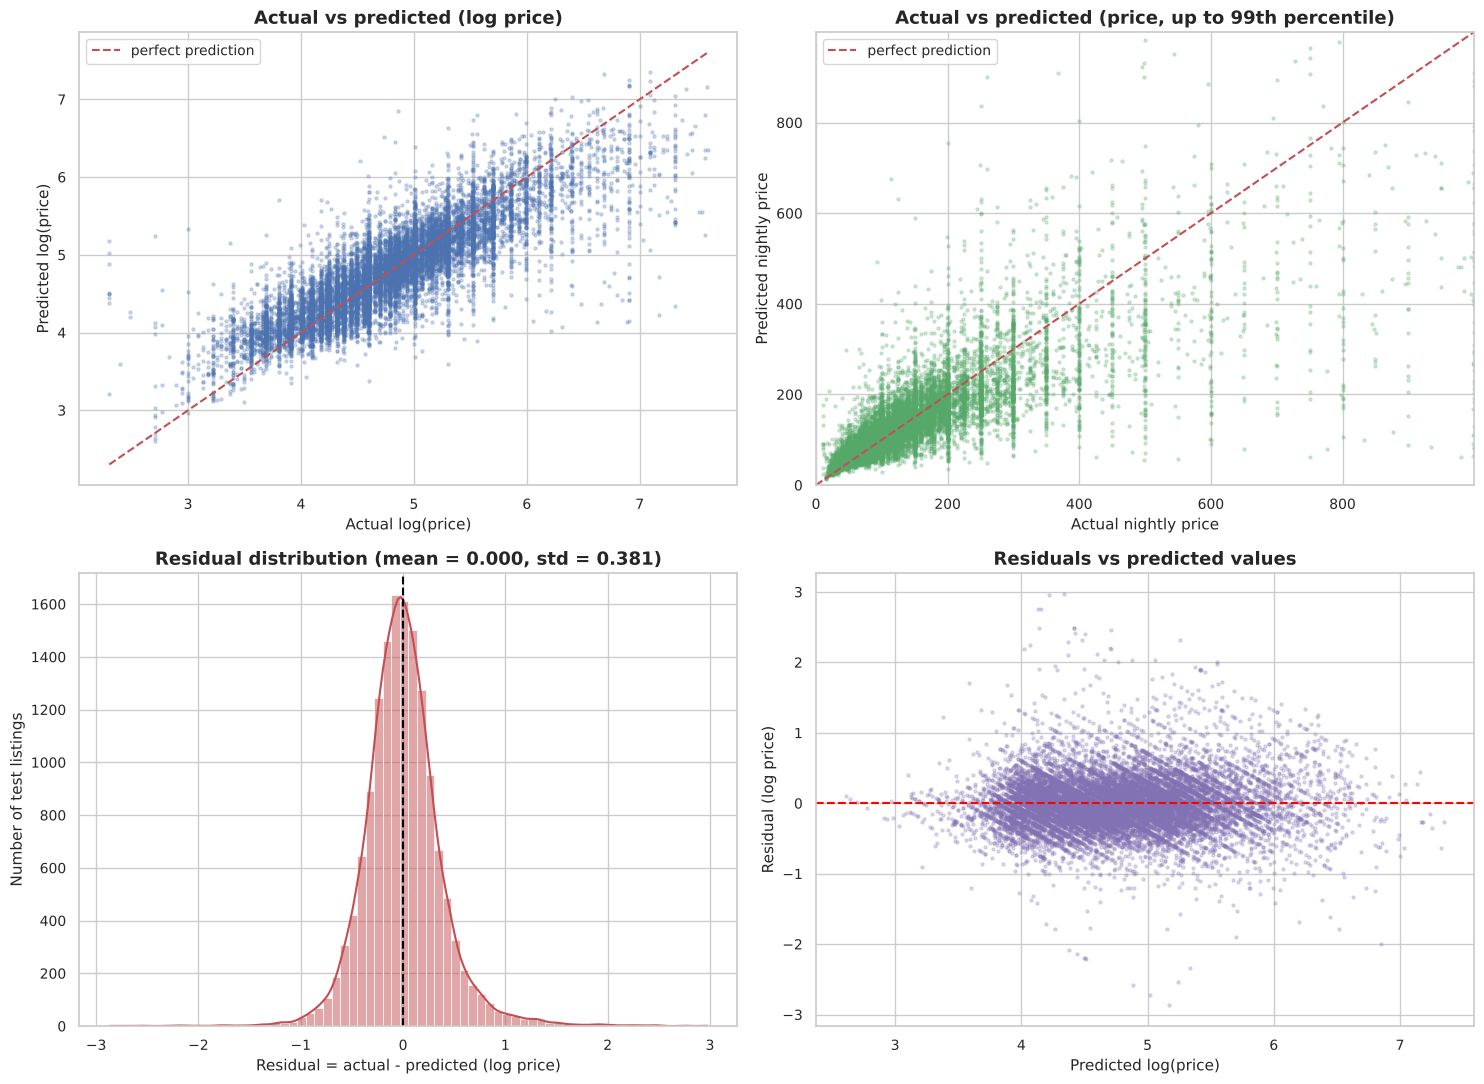

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. actual vs predicted (log)
ax = axes[0, 0]
ax.scatter(y_test, final_pred, s=5, alpha=0.25, color="#4C72B0")
lims = [min(y_test.min(), final_pred.min()), max(y_test.max(), final_pred.max())]
ax.plot(lims, lims, "r--", label="perfect prediction")
ax.set(title="Actual vs predicted (log price)", xlabel="Actual log(price)", ylabel="Predicted log(price)")
ax.legend()

# 2. actual vs predicted (price)
ax = axes[0, 1]
cap = np.quantile(price_true, 0.99)
ax.scatter(price_true, price_pred, s=5, alpha=0.25, color="#55A868")
ax.plot([0, cap], [0, cap], "r--", label="perfect prediction")
ax.set(xlim=(0, cap), ylim=(0, cap), title="Actual vs predicted (price, up to 99th percentile)",
       xlabel="Actual nightly price", ylabel="Predicted nightly price")
ax.legend()

# 3. residual distribution
ax = axes[1, 0]
sns.histplot(resid, bins=70, kde=True, color="#C44E52", ax=ax)
ax.axvline(0, color="black", ls="--")
ax.set(title=f"Residual distribution (mean = {resid.mean():.3f}, std = {resid.std():.3f})",
       xlabel="Residual = actual - predicted (log price)", ylabel="Number of test listings")

# 4. residuals vs predicted
ax = axes[1, 1]
ax.scatter(final_pred, resid, s=5, alpha=0.25, color="#8172B3")
ax.axhline(0, color="red", ls="--")
ax.set(title="Residuals vs predicted values", xlabel="Predicted log(price)", ylabel="Residual (log price)")
plt.show()

**How to read the plots.**
* **Actual vs predicted:** points close to the red diagonal are good predictions. The cloud is centred on the line (no systematic bias) but has noticeable spread - the model cannot know things such as photo quality, exact view or the host's pricing strategy.
* **Residual distribution:** a roughly bell-shaped curve centred on 0 means errors are mostly random and unbiased.
* **Residuals vs predicted:** we want a shapeless cloud around 0. Any trend or funnel shape would reveal systematic problems. Expect a mild tilt: models "shrink towards the average", so the **cheapest listings tend to be over-predicted and the most expensive under-predicted** (check the price-band table below - `mean_log_residual` is negative for the lowest band and positive for the highest).

In [40]:
err = pd.DataFrame({"city": X_test["city"].values, "room_type": X_test["room_type"].values,
                    "actual": price_true, "predicted": price_pred, "resid_log": resid})
err["abs_error"] = np.abs(err["actual"] - err["predicted"])
err["abs_pct_error"] = err["abs_error"] / err["actual"]
err["price band"] = pd.qcut(err["actual"], 5, labels=["lowest 20%", "20-40%", "40-60%", "60-80%", "highest 20%"])

def error_table(by):
    return err.groupby(by, observed=True).agg(listings=("actual", "size"), MAE_price=("abs_error", "mean"),
                                              median_abs_pct_error=("abs_pct_error", "median"),
                                              mean_log_residual=("resid_log", "mean")).round(3)
display(Markdown("**Prediction error by city**"));          display(error_table("city"))
display(Markdown("**Prediction error by room type**"));     display(error_table("room_type"))
display(Markdown("**Prediction error by actual price band** (mean_log_residual > 0 means under-prediction)"));  display(error_table("price band"))
display(Markdown("**The 8 largest errors in the test set**"))
display(err.nlargest(8, "abs_error")[["city", "room_type", "actual", "predicted", "abs_error"]].round(1))

**Prediction error by city**

,listings,MAE_price,median_abs_pct_error,mean_log_residual
city,,,,
Boston,693,45.761,0.199,0.011
Chicago,744,39.326,0.223,-0.013
DC,1138,92.641,0.262,-0.005
LA,4491,45.946,0.200,-0.002
NYC,6469,39.193,0.195,0.005
SF,1287,78.610,0.217,-0.008


**Prediction error by room type**

,listings,MAE_price,median_abs_pct_error,mean_log_residual
room_type,,,,
Entire home/apt,8212,66.877,0.202,0.008
Private room,6147,26.668,0.203,-0.007
Shared room,463,30.943,0.270,-0.032


**Prediction error by actual price band** (mean_log_residual > 0 means under-prediction)

,listings,MAE_price,median_abs_pct_error,mean_log_residual
price band,,,,
lowest 20%,3061,16.803,0.253,-0.254
20-40%,2895,19.116,0.176,-0.067
40-60%,3027,27.326,0.174,-0.025
60-80%,2989,38.045,0.178,0.069
highest 20%,2850,148.858,0.273,0.297


**The 8 largest errors in the test set**

,city,room_type,actual,predicted,abs_error
1694,DC,Entire home/apt,"1,950.000",192.600,"1,757.400"
9715,LA,Entire home/apt,"1,900.000",257.500,"1,642.500"
5879,NYC,Private room,"1,850.000",256.900,"1,593.100"
1785,DC,Entire home/apt,"1,950.000",515.200,"1,434.800"
10674,DC,Entire home/apt,"1,999.000",574.300,"1,424.700"
10588,LA,Private room,"1,500.000",76.500,"1,423.500"
7418,LA,Entire home/apt,"1,950.000",569.700,"1,380.300"
13260,SF,Entire home/apt,"1,750.000",425.500,"1,324.500"


In [41]:
# ---- Robustness check: predicting for NEIGHBOURHOODS the model has never seen (group split) ----
groups = (X["city"].astype(str) + "|" + X["neighbourhood"].fillna("Unknown").astype(str))
gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
g_train, g_test = next(gss.split(X, y, groups))
g_model = clone(final_model).fit(X.iloc[g_train], y.iloc[g_train])
g_rep = regression_report(y.iloc[g_test], g_model.predict(X.iloc[g_test]))
cmp = pd.DataFrame({"Random split (used)": final_report, "Neighbourhood-group split": g_rep}).loc[["RMSE (log)", "R2 (log)", "MAE (price)", "RMSE (price)"]].T
display(cmp)
print(f"Unseen neighbourhoods in the group-split test set: {groups.iloc[g_test].nunique()} groups "
      f"(no group appears in both train and test).")
delta = g_rep["RMSE (log)"] - final_report["RMSE (log)"]
print(f"RMSE(log) changes by {delta:+.3f} when whole neighbourhoods are held out "
      f"({'performance holds up' if abs(delta) < 0.03 else 'a noticeable change'}). The model relies on coordinates and "
      "distance-to-centre, which let it generalise to nearby unseen areas. (The two splits contain different listings, so small differences are expected.)")

,RMSE (log),R2 (log),MAE (price),RMSE (price)
Random split (used),0.381,0.723,49.079,115.520
Neighbourhood-group split,0.374,0.721,48.796,102.352


Unseen neighbourhoods in the group-split test set: 130 groups (no group appears in both train and test).
RMSE(log) changes by -0.007 when whole neighbourhoods are held out (performance holds up). The model relies on coordinates and distance-to-centre, which let it generalise to nearby unseen areas. (The two splits contain different listings, so small differences are expected.)


In [42]:
mae_p, rmse_p = final_report["MAE (price)"], final_report["RMSE (price)"]
display(Markdown(f"""
### What these numbers mean for Airbnb prices
* **R² (log price) = {final_report['R2 (log)']:.3f}** - the model explains about **{final_report['R2 (log)']*100:.0f} %** of the variation in log prices. This is *explained variance*, **not** "{final_report['R2 (log)']*100:.0f} % accuracy".
* **MAE = {mae_p:,.1f}** price units: on average a prediction is off by this amount; **RMSE = {rmse_p:,.1f}** is larger because a few expensive listings are badly mis-priced.
* **Median error = {np.median(abs_pct):.0%}**; **{np.mean(abs_pct <= 0.25):.0%}** of predictions are within 25 % of the real price. So the tool is good as a **starting-price guide**, not as an exact valuation.
* Versus the median baseline (RMSE(log) {baseline_report['RMSE (log)']:.3f}) the final model's RMSE(log) is **{final_report['RMSE (log)']:.3f}** - a {100*(1-final_report['RMSE (log)']/baseline_report['RMSE (log)']):.0f} % reduction.
* Test vs cross-validation: test RMSE(log) = {final_report['RMSE (log)']:.3f}, CV RMSE(log) = {(tuned_cv if final_model is tuned_pipe else baseline_cv):.3f} -> consistent, so no sign of test-set luck.
"""))


### What these numbers mean for Airbnb prices
* **R² (log price) = 0.723** - the model explains about **72 %** of the variation in log prices. This is *explained variance*, **not** "72 % accuracy".
* **MAE = 49.1** price units: on average a prediction is off by this amount; **RMSE = 115.5** is larger because a few expensive listings are badly mis-priced.
* **Median error = 20%**; **59%** of predictions are within 25 % of the real price. So the tool is good as a **starting-price guide**, not as an exact valuation.
* Versus the median baseline (RMSE(log) 0.726) the final model's RMSE(log) is **0.381** - a 48 % reduction.
* Test vs cross-validation: test RMSE(log) = 0.381, CV RMSE(log) = 0.374 -> consistent, so no sign of test-set luck.


## 15 - Feature Importance and Model Explainability

We use three complementary views:

1. **Tree-based (impurity) importance** - how much a feature reduces error *inside the trees* while training. (Quick, but can favour features with many distinct values.)
2. **Permutation importance** - shuffle one input column on the test data and measure how much the error grows. A big increase = the model relied on that column. (Model-agnostic and measured on unseen data.)
3. **SHAP** - gives each feature a *contribution* (push up / push down) to each individual prediction, based on game theory.

### Correlation vs feature importance
* **Correlation** is a property of the **data**: how two columns move together (linear, one pair at a time).
* **Feature importance** is a property of the **trained model**: how much the model *uses* a feature, including non-linear effects and interactions.
* A feature can be important but have low correlation (e.g. `neighbourhood`), or correlated but unimportant because another feature already carries the same information.
* **Neither proves causation.** "Bedrooms is important" does not mean that adding a bedroom *causes* a price rise of that size; it means the model uses it to make predictions.

In [43]:
GROUP_PREFIXES = sorted(CATEGORICAL_FEATURES, key=len, reverse=True)
def raw_group(feature_name):
    # Map an encoded column name (e.g. 'cat__neighbourhood_Harlem') back to its original feature.
    if feature_name.startswith("amen__"):
        return "amenity flags (top 25)"
    if feature_name.startswith("cat__"):
        rest = feature_name[len("cat__"):]
        for c in GROUP_PREFIXES:
            if rest.startswith(c + "_"):
                return c
    return feature_name.split("__", 1)[1]

prep_fitted = final_model.named_steps["prep"]
encoded_names = prep_fitted.get_feature_names_out()
encoded_groups = np.array([raw_group(n) for n in encoded_names])
final_estimator = final_model.named_steps["model"]
print("Final model:", final_name, "|", len(encoded_names), "encoded inputs ->", len(set(encoded_groups)), "original features/groups")

Final model: HistGradientBoosting (tuned) | 325 encoded inputs -> 32 original features/groups


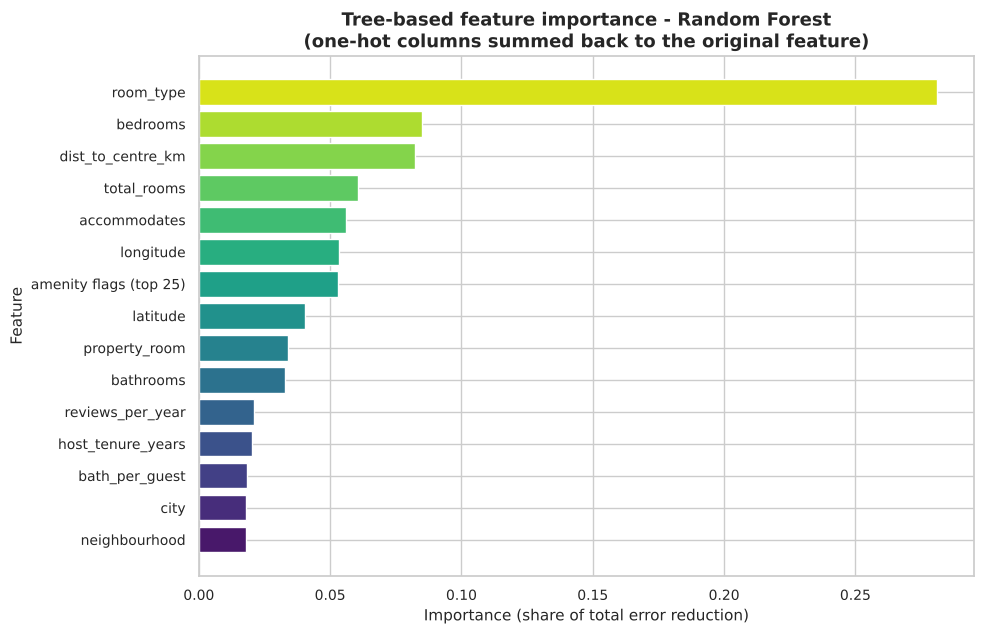

In [44]:
# ---- 1. Tree-based importance (use the final model if it exposes it, otherwise the Random Forest) ----
imp_source = final_name if hasattr(final_estimator, "feature_importances_") else "Random Forest"
imp_pipe = final_model if imp_source == final_name else fitted["Random Forest"]
imp_est = imp_pipe.named_steps["model"]
imp_names = imp_pipe.named_steps["prep"].get_feature_names_out()
imp_df = (pd.DataFrame({"group": [raw_group(n) for n in imp_names], "importance": imp_est.feature_importances_})
          .groupby("group")["importance"].sum().sort_values(ascending=False))
top = imp_df.head(15)[::-1]
plt.figure(figsize=(10, 6.5))
plt.barh(top.index, top.values, color=sns.color_palette("viridis", len(top)))
plt.title(f"Tree-based feature importance - {imp_source}\n(one-hot columns summed back to the original feature)")
plt.xlabel("Importance (share of total error reduction)"); plt.ylabel("Feature")
plt.show()

Permutation importance finished in 16 s


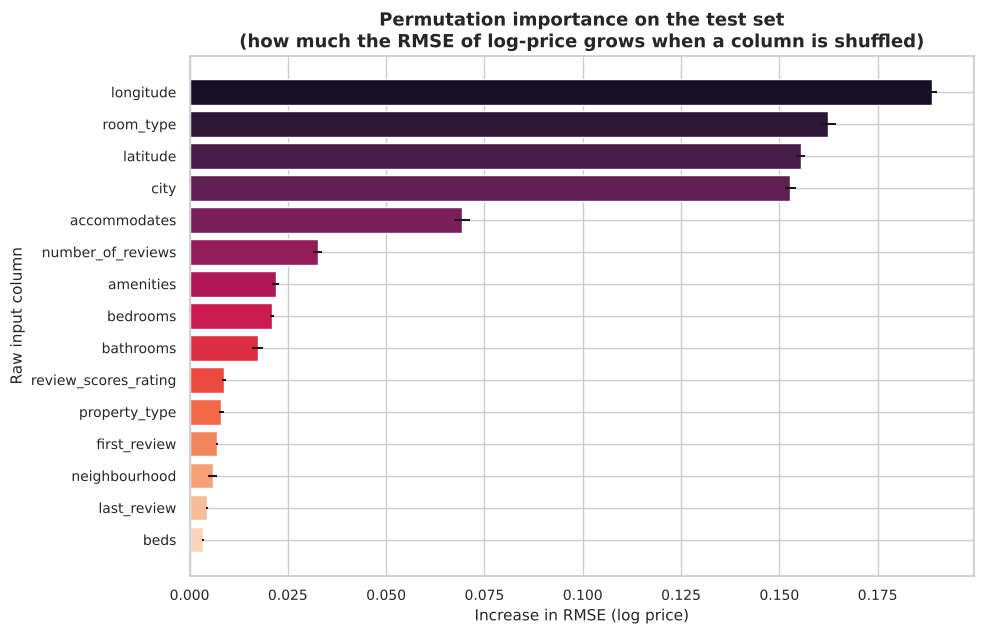

,feature,rmse_increase,std
0,longitude,0.189,0.001
1,room_type,0.162,0.002
2,latitude,0.155,0.001
3,city,0.153,0.001
4,accommodates,0.069,0.002
5,number_of_reviews,0.033,0.001
6,amenities,0.022,0.001
7,bedrooms,0.021,0.001
8,bathrooms,0.017,0.001
9,review_scores_rating,0.009,0.000


In [45]:
# ---- 2. Permutation importance on the TEST set (raw input columns) ----
n_perm = 1500 if QUICK_RUN else 4000
X_perm = X_test.sample(min(n_perm, len(X_test)), random_state=RANDOM_STATE)
y_perm = y_test.loc[X_perm.index]
t0 = time.time()
perm = permutation_importance(final_model, X_perm, y_perm, scoring="neg_root_mean_squared_error",
                              n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
perm_df = (pd.DataFrame({"feature": X_perm.columns, "rmse_increase": perm.importances_mean, "std": perm.importances_std})
           .sort_values("rmse_increase", ascending=False).reset_index(drop=True))
print(f"Permutation importance finished in {time.time()-t0:.0f} s")

top = perm_df.head(15)[::-1]
plt.figure(figsize=(10, 6.5))
plt.barh(top["feature"], top["rmse_increase"], xerr=top["std"], color=sns.color_palette("rocket_r", len(top)))
plt.title("Permutation importance on the test set\n(how much the RMSE of log-price grows when a column is shuffled)")
plt.xlabel("Increase in RMSE (log price)"); plt.ylabel("Raw input column")
plt.show()
display(perm_df.head(10).round(4))

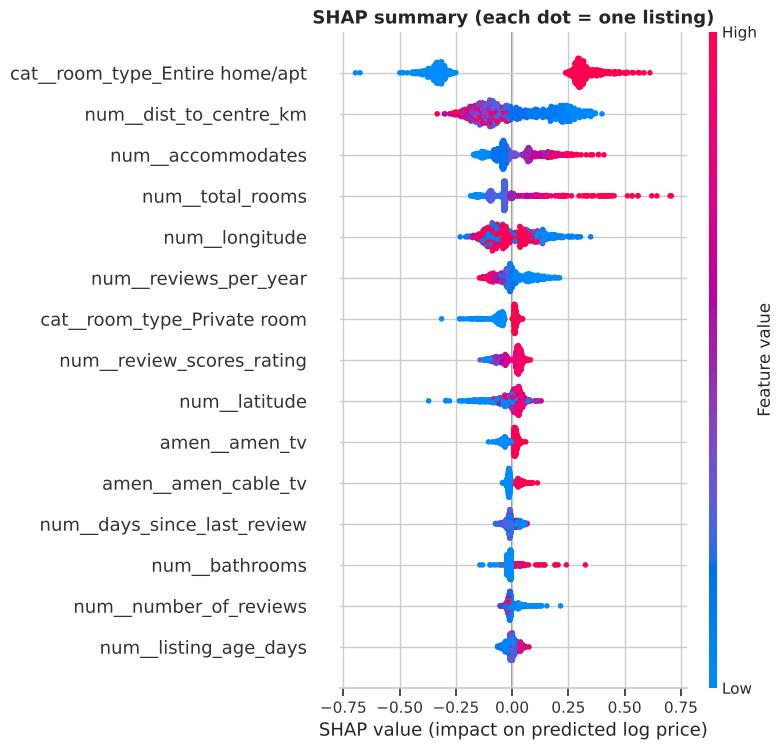

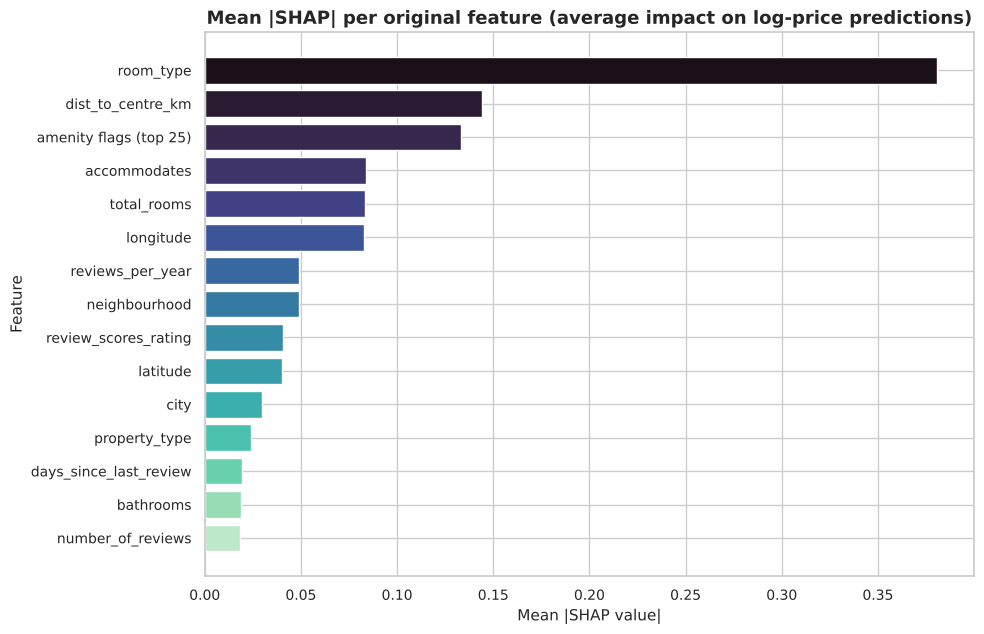

In [46]:
# ---- 3. SHAP (optional, tree models) ----
shap_df = None
if shap is None:
    print("shap is not installed -> skipped (pip install shap).")
else:
    try:
        n_shap = 400 if QUICK_RUN else 1000
        X_shap_raw = X_test.sample(min(n_shap, len(X_test)), random_state=RANDOM_STATE)
        X_shap = prep_fitted.transform(final_model.named_steps["features"].transform(X_shap_raw))
        explainer = shap.TreeExplainer(final_estimator)
        sv = explainer.shap_values(X_shap)
        # (a) beeswarm of the individual encoded features
        plt.figure()
        shap.summary_plot(sv, X_shap, feature_names=encoded_names, max_display=15, show=False)
        plt.title("SHAP summary (each dot = one listing)")
        plt.xlabel("SHAP value (impact on predicted log price)")
        plt.show()
        # (b) mean |SHAP| aggregated per original feature
        shap_df = (pd.DataFrame(np.abs(sv), columns=encoded_groups).T.groupby(level=0).sum().T.mean()
                   .sort_values(ascending=False).rename("mean_abs_shap").to_frame())
        top = shap_df.head(15)[::-1]
        plt.figure(figsize=(10, 6.5))
        plt.barh(top.index, top["mean_abs_shap"], color=sns.color_palette("mako_r", len(top)))
        plt.title("Mean |SHAP| per original feature (average impact on log-price predictions)")
        plt.xlabel("Mean |SHAP value|"); plt.ylabel("Feature")
        plt.show()
    except Exception as exc:
        print("SHAP analysis skipped:", type(exc).__name__, str(exc)[:200])

In [47]:
top_perm = perm_df.head(6)["feature"].tolist()
top_tree = imp_df.head(6).index.tolist()
display(Markdown(f"""
### Interpretation of the most influential factors
* **Permutation importance (test set) - top 6:** {", ".join(f"`{f}`" for f in top_perm)}.
* **Tree-based importance - top 6:** {", ".join(f"`{f}`" for f in top_tree)}.
* Read the lists above together: **where the property is** (latitude/longitude, city - the distance-to-centre feature is built from these), **what kind of space it is** (room type) and **how big it is** (guests, bedrooms, bathrooms) dominate; amenities, policies, and host details add smaller refinements. Note that permutation importance is measured on the *raw* columns, so a column such as `latitude` also carries the effect of the features derived from it.
* Review count / review activity gets a moderate importance: the model uses it as a signal of listing type and popularity (in the SHAP plot, more review activity per year goes together with lower predicted prices - cheaper listings get booked more often). That is a statistical pattern, **not** advice to "get fewer reviews".
* These are *associations learned by the model*, **not proof of cause and effect**. For example, location features partly stand in for things we cannot see (views, safety, nearby attractions).
"""))

feature_importance_results = (perm_df.set_index("feature")[["rmse_increase"]].rename(columns={"rmse_increase": "permutation_importance_rmse_increase"})
                              .join(imp_df.rename(f"tree_importance_{imp_source.replace(' ', '_')}"), how="outer"))
if shap_df is not None:
    feature_importance_results = feature_importance_results.join(shap_df, how="outer")
feature_importance_results = feature_importance_results.sort_values("permutation_importance_rmse_increase", ascending=False)


### Interpretation of the most influential factors
* **Permutation importance (test set) - top 6:** `longitude`, `room_type`, `latitude`, `city`, `accommodates`, `number_of_reviews`.
* **Tree-based importance - top 6:** `room_type`, `bedrooms`, `dist_to_centre_km`, `total_rooms`, `accommodates`, `longitude`.
* Read the lists above together: **where the property is** (latitude/longitude, city - the distance-to-centre feature is built from these), **what kind of space it is** (room type) and **how big it is** (guests, bedrooms, bathrooms) dominate; amenities, policies, and host details add smaller refinements. Note that permutation importance is measured on the *raw* columns, so a column such as `latitude` also carries the effect of the features derived from it.
* Review count / review activity gets a moderate importance: the model uses it as a signal of listing type and popularity (in the SHAP plot, more review activity per year goes together with lower predicted prices - cheaper listings get booked more often). That is a statistical pattern, **not** advice to "get fewer reviews".
* These are *associations learned by the model*, **not proof of cause and effect**. For example, location features partly stand in for things we cannot see (views, safety, nearby attractions).


## 16 - User Input Prediction System

This is the heart of the project: a tool where a user describes a property and receives an estimated nightly price.

**How it works (workflow)**
1. Collect the inputs (widgets, or a plain Python function call).
2. **Validate** them (valid category? number in the range seen in training data?).
3. Convert to a one-row pandas DataFrame with the **exact column names** the pipeline expects.
4. Apply the **same saved pipeline** (feature engineering -> preprocessing -> model).
5. Convert the predicted log-price back with `exp()` and display it prominently, together with a typical range.
6. Explain the main factors (a what-if analysis).

**Inputs that exist in this dataset and are used by the model:** city, neighbourhood, property type, room type, bed type, guests, bedrooms, beds, bathrooms, cancellation policy, cleaning fee, instant booking, host verified, host tenure, number of reviews, review score, days since last review, amenities.

**Not in this dataset - therefore not offered (we do not invent fields):** *availability*, *minimum nights*, season/date of stay, host id, photos. The listing's latitude/longitude are filled automatically from the chosen neighbourhood (median coordinates of training listings).

The estimate is **not a guaranteed market price** - it is what listings with similar characteristics in this 2017-era dataset tended to charge.

In [48]:
# ---- Input specification: valid values are taken from the TRAINING data only ----
fe_final = final_model.named_steps["features"]
MIN_COUNT = 20                                              # categories need >= 20 training listings
def common_values(col, n=None):
    vc = X_train[col].dropna().value_counts()
    return vc[vc >= MIN_COUNT].index.tolist()[:n]

neigh_by_city = {}
for city_name, grp in X_train.dropna(subset=["neighbourhood"]).groupby("city"):
    vc = grp["neighbourhood"].value_counts()
    neigh_by_city[city_name] = sorted(vc[vc >= MIN_COUNT].index.tolist())

prep_in = fe_final.transform(X_train)                       # engineered training features (for medians / ranges)
def rng(series):
    return [float(np.floor(series.min())), float(np.ceil(series.max()))]

INPUT_SPEC = {
    "categories": {"city": sorted(X_train["city"].unique()), "property_type": common_values("property_type"),
                   "room_type": common_values("room_type"), "bed_type": common_values("bed_type"),
                   "cancellation_policy": common_values("cancellation_policy")},
    "neighbourhoods": neigh_by_city,
    "ranges": {"accommodates": rng(prep_in["accommodates"]), "bedrooms": rng(prep_in["bedrooms"]),
               "beds": rng(prep_in["beds"]), "bathrooms": rng(prep_in["bathrooms"]),
               "number_of_reviews": rng(prep_in["number_of_reviews"]), "review_scores_rating": [20.0, 100.0],
               "host_response_rate": [0.0, 100.0], "host_tenure_years": [0.0, 15.0],
               "days_since_last_review": [0.0, float(np.ceil(prep_in["days_since_last_review"].max()))],
               "listing_age_days": [0.0, float(np.ceil(prep_in["listing_age_days"].max()))]},
    "defaults": {"city": X_train["city"].mode()[0], "property_type": X_train["property_type"].mode()[0],
                 "room_type": X_train["room_type"].mode()[0], "bed_type": X_train["bed_type"].mode()[0],
                 "cancellation_policy": X_train["cancellation_policy"].mode()[0],
                 "accommodates": float(prep_in["accommodates"].median()), "bedrooms": float(prep_in["bedrooms"].median()),
                 "beds": float(prep_in["beds"].median()), "bathrooms": float(prep_in["bathrooms"].median()),
                 "cleaning_fee": bool(prep_in["cleaning_fee"].mode()[0]), "instant_bookable": bool(prep_in["instant_bookable"].mode()[0]),
                 "host_identity_verified": bool(prep_in["host_identity_verified"].mode()[0]),
                 "host_has_profile_pic": bool(prep_in["host_has_profile_pic"].mode()[0]),
                 "number_of_reviews": float(prep_in["number_of_reviews"].median()),
                 "review_scores_rating": float(prep_in["review_scores_rating"].median()),
                 "host_response_rate": float(prep_in["host_response_rate"].median()),
                 "host_tenure_years": float(prep_in["host_tenure_years"].median()),
                 "days_since_last_review": float(prep_in["days_since_last_review"].median()),
                 "listing_age_days": float(prep_in["listing_age_days"].median())},
    "amenity_vocabulary": list(fe_final.amenity_vocab_),
    "default_amenities": [a for a in fe_final.amenity_vocab_
                          if prep_in[f"amen_{re.sub('[^a-z0-9]+', '_', a.lower()).strip('_')}"].mean() >= 0.5],
}
# typical +/- range from the test residuals (16th and 84th percentile of actual - predicted, log scale)
INPUT_SPEC["residual_quantiles"] = [float(np.quantile(resid, 0.16)), float(np.quantile(resid, 0.84))]
INPUT_SPEC["currency"] = CURRENCY            # None unless verified (Section 04)

print("Cities:", INPUT_SPEC["categories"]["city"])
print("Room types:", INPUT_SPEC["categories"]["room_type"])
print("Property types offered:", len(INPUT_SPEC["categories"]["property_type"]))
print("Neighbourhood options per city:", {c: len(v) for c, v in INPUT_SPEC["neighbourhoods"].items()})
print("Numeric input ranges (from training data):")
for k, v in INPUT_SPEC["ranges"].items():
    print(f"  {k:<24} {v}")

Cities: ['Boston', 'Chicago', 'DC', 'LA', 'NYC', 'SF']
Room types: ['Entire home/apt', 'Private room', 'Shared room']
Property types offered: 19
Neighbourhood options per city: {'Boston': 20, 'Chicago': 35, 'DC': 42, 'LA': 83, 'NYC': 96, 'SF': 46}
Numeric input ranges (from training data):
  accommodates             [1.0, 16.0]
  bedrooms                 [0.0, 10.0]
  beds                     [0.0, 18.0]
  bathrooms                [0.0, 8.0]
  number_of_reviews        [0.0, 530.0]
  review_scores_rating     [20.0, 100.0]
  host_response_rate       [0.0, 100.0]
  host_tenure_years        [0.0, 15.0]
  days_since_last_review   [0.0, 3179.0]
  listing_age_days         [0.0, 3244.0]


In [49]:
from airbnb_features import predict_price, explain_prediction, validate_inputs, build_input_frame

def fmt_price(value):
    # Show the currency only when it has been verified.
    return f"{INPUT_SPEC['currency']} {value:,.0f}" if INPUT_SPEC["currency"] else f"{value:,.0f}"

def estimate(**inputs):
    # Simple Python function (no widgets needed). Returns the result dict and prints a short summary.
    res = predict_price(final_model, INPUT_SPEC, **inputs)
    print(f"Estimated nightly price: {fmt_price(res['price'])}   (typical range {fmt_price(res['low'])} - {fmt_price(res['high'])})")
    for w in res["warnings"]:
        print("  note:", w)
    return res

# --- Example 1: input validation catches mistakes ---
try:
    predict_price(final_model, INPUT_SPEC, city="Paris", room_type="Villa", accommodates=-2)
except ValueError as e:
    print("Validation works:\n", e)

Validation works:
 Invalid input:
  - 'city' = 'Paris' is not valid. Choose one of: ['Boston', 'Chicago', 'DC', 'LA', 'NYC', 'SF']
  - 'room_type' = 'Villa' is not valid. Choose one of: ['Entire home/apt', 'Private room', 'Shared room']
  - 'accommodates' = -2.0 is outside the range seen in training data (1.0 to 16.0).


In [50]:
examples = {
    "1) Studio-like private room, Manhattan": dict(city="NYC", neighbourhood="Harlem", property_type="Apartment", room_type="Private room",
        accommodates=2, bedrooms=1, beds=1, bathrooms=1, amenities=["Wireless Internet", "Kitchen", "Heating"],
        number_of_reviews=12, review_scores_rating=94, days_since_last_review=30, listing_age_days=500, host_tenure_years=3),
    "2) Family house, Los Angeles": dict(city="LA", neighbourhood="Venice", property_type="House", room_type="Entire home/apt",
        accommodates=6, bedrooms=3, beds=4, bathrooms=2, cleaning_fee=True,
        amenities=["Wireless Internet", "Kitchen", "Air conditioning", "TV", "Washer", "Dryer", "Free parking on premises"],
        number_of_reviews=40, review_scores_rating=97, days_since_last_review=10, listing_age_days=900, host_tenure_years=4),
    "3) Shared room, Boston": dict(city="Boston", neighbourhood="Allston-Brighton", property_type="Apartment", room_type="Shared room",
        accommodates=1, bedrooms=1, beds=1, bathrooms=1, number_of_reviews=0, amenities=["Wireless Internet"]),
    "4) Luxury entire loft, San Francisco": dict(city="SF", neighbourhood="Mission District", property_type="Loft", room_type="Entire home/apt",
        accommodates=4, bedrooms=2, beds=2, bathrooms=2, instant_bookable=True,
        amenities=["Wireless Internet", "Kitchen", "Heating", "Air conditioning", "TV", "Washer", "Dryer", "Laptop friendly workspace"],
        number_of_reviews=25, review_scores_rating=99, days_since_last_review=14, listing_age_days=700, host_tenure_years=5),
}
rows = []
for title, kw in examples.items():
    if kw["neighbourhood"] not in INPUT_SPEC["neighbourhoods"].get(kw["city"], []):
        kw["neighbourhood"] = "Unknown"                 # fall back if the example neighbourhood is not in the training list
    r = predict_price(final_model, INPUT_SPEC, **kw)
    rows.append({"Property": title, "Room type": kw["room_type"], "Guests": kw["accommodates"], "Bedrooms": kw["bedrooms"],
                 "Estimated nightly price": r["price"], "Typical range low": r["low"], "Typical range high": r["high"]})
example_table = pd.DataFrame(rows).set_index("Property")
display(example_table.style.format({"Estimated nightly price": "{:,.0f}", "Typical range low": "{:,.0f}", "Typical range high": "{:,.0f}"}))

# Sanity check against real data: median training price of similar listings
sim = []
for title, kw in examples.items():
    mask = (df_clean["city"] == kw["city"]) & (df_clean["room_type"] == kw["room_type"]) & (df_clean["accommodates"].between(kw["accommodates"] - 1, kw["accommodates"] + 1))
    sim.append({"Property": title, "similar listings in data": int(mask.sum()), "their median price": df_clean.loc[mask, "price"].median()})
display(Markdown("**Sanity check - median price of similar real listings (same city, room type, +/-1 guest)**"))
display(pd.DataFrame(sim).set_index("Property").style.format({"their median price": "{:,.0f}"}))

,Room type,Guests,Bedrooms,Estimated nightly price,Typical range low,Typical range high
Property,,,,,,
"1) Studio-like private room, Manhattan",Private room,2,1,75,55,101
"2) Family house, Los Angeles",Entire home/apt,6,3,369,269,499
"3) Shared room, Boston",Shared room,1,1,60,44,81
"4) Luxury entire loft, San Francisco",Entire home/apt,4,2,309,226,418


**Sanity check - median price of similar real listings (same city, room type, +/-1 guest)**

,similar listings in data,their median price
Property,,
"1) Studio-like private room, Manhattan",14531,70
"2) Family house, Los Angeles",3056,200
"3) Shared room, Boston",42,67
"4) Luxury entire loft, San Francisco",1751,229


**Why this estimate? (Example 2)** - effect of each input compared with a *typical* listing's value of that input, others unchanged

,factor,your value,effect on price
0,bathrooms,bathrooms=2.0,+111.5
1,bedrooms,bedrooms=3.0,+93.2
2,accommodates,accommodates=6.0,+85.0
3,review history,"number_of_reviews=40.0, review_scores_rating=97.0, days_sinc",-71.7
4,property_type,property_type=House,+61.3
5,neighbourhood,neighbourhood=Venice,+30.6
6,amenities,7 amenities,+22.9
7,beds,beds=4.0,+9.4
8,room_type,room_type=Entire home/apt,+0.0
9,bed_type,bed_type=Real Bed,+0.0


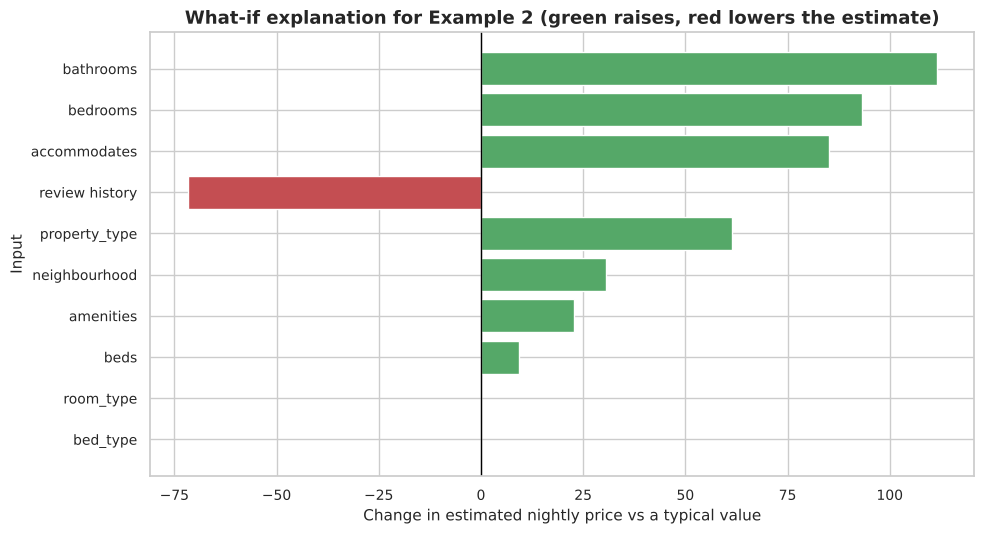

In [51]:
expl = explain_prediction(final_model, INPUT_SPEC, **examples["2) Family house, Los Angeles"])
display(Markdown("**Why this estimate? (Example 2)** - effect of each input compared with a *typical* listing's value of that input, others unchanged"))
display(expl.style.format({"effect on price": "{:+,.1f}"}))
plot_e = expl.head(10)[::-1]
plt.figure(figsize=(10, 5.5))
plt.barh(plot_e["factor"], plot_e["effect on price"], color=np.where(plot_e["effect on price"] >= 0, "#55A868", "#C44E52"))
plt.axvline(0, color="black", lw=1)
plt.title("What-if explanation for Example 2 (green raises, red lowers the estimate)")
plt.xlabel("Change in estimated nightly price vs a typical value"); plt.ylabel("Input")
plt.show()

In [52]:
# ---- Interactive interface (ipywidgets) ----
if widgets is None:
    print("ipywidgets is not installed. Use the estimate(...) function above, or install with: pip install ipywidgets")
else:
    S, D = INPUT_SPEC, INPUT_SPEC["defaults"]
    style = {"description_width": "150px"}
    lay = widgets.Layout(width="360px")

    def dd(label, options, value):
        return widgets.Dropdown(options=options, value=value, description=label, style=style, layout=lay)
    def num_int(label, lo, hi, val):
        return widgets.BoundedIntText(value=int(val), min=int(lo), max=int(hi), description=label, style=style, layout=lay)

    w_city  = dd("City", S["categories"]["city"], D["city"])
    w_neigh = dd("Neighbourhood", ["Unknown"] + S["neighbourhoods"][D["city"]], "Unknown")
    w_prop  = dd("Property type", S["categories"]["property_type"], D["property_type"])
    w_room  = dd("Room type", S["categories"]["room_type"], D["room_type"])
    w_bed   = dd("Bed type", S["categories"]["bed_type"], D["bed_type"])
    w_canc  = dd("Cancellation", S["categories"]["cancellation_policy"], D["cancellation_policy"])
    w_acc   = num_int("Guests", *S["ranges"]["accommodates"], D["accommodates"])
    w_bedr  = num_int("Bedrooms", *S["ranges"]["bedrooms"], D["bedrooms"])
    w_beds  = num_int("Beds", *S["ranges"]["beds"], D["beds"])
    w_bath  = widgets.BoundedFloatText(value=float(D["bathrooms"]), min=S["ranges"]["bathrooms"][0], max=S["ranges"]["bathrooms"][1],
                                       step=0.5, description="Bathrooms", style=style, layout=lay)
    w_clean = widgets.Checkbox(value=D["cleaning_fee"], description="Cleaning fee charged", indent=False)
    w_inst  = widgets.Checkbox(value=D["instant_bookable"], description="Instant bookable", indent=False)
    w_ver   = widgets.Checkbox(value=D["host_identity_verified"], description="Host identity verified", indent=False)
    w_ten   = widgets.BoundedFloatText(value=round(D["host_tenure_years"], 1), min=0, max=15, step=0.5,
                                       description="Host years", style=style, layout=lay)
    w_nrev  = num_int("Number of reviews", *S["ranges"]["number_of_reviews"], 0)
    w_rate  = widgets.BoundedIntText(value=int(D["review_scores_rating"]), min=20, max=100, description="Review score",
                                     style=style, layout=lay)
    w_last  = widgets.BoundedIntText(value=int(D["days_since_last_review"]), min=0, max=int(S["ranges"]["days_since_last_review"][1]),
                                     description="Days since last review", style=style, layout=lay)
    w_amen  = widgets.SelectMultiple(options=S["amenity_vocabulary"], value=tuple(S["default_amenities"]),
                                     description="Amenities", rows=10, style=style, layout=widgets.Layout(width="360px"))
    w_btn   = widgets.Button(description="Predict price", button_style="success", icon="calculator")
    w_clear = widgets.Button(description="Clear history")
    out     = widgets.Output()
    history = []

    def on_city_change(change):                       # neighbourhood list depends on the chosen city
        w_neigh.options = ["Unknown"] + S["neighbourhoods"].get(change["new"], [])
        w_neigh.value = "Unknown"
    w_city.observe(on_city_change, names="value")

    def on_predict(_):
        with out:
            out.clear_output()
            kw = dict(city=w_city.value, neighbourhood=w_neigh.value, property_type=w_prop.value, room_type=w_room.value,
                      bed_type=w_bed.value, cancellation_policy=w_canc.value, accommodates=w_acc.value, bedrooms=w_bedr.value,
                      beds=w_beds.value, bathrooms=w_bath.value, cleaning_fee=w_clean.value, instant_bookable=w_inst.value,
                      host_identity_verified=w_ver.value, host_tenure_years=w_ten.value, number_of_reviews=w_nrev.value,
                      review_scores_rating=w_rate.value if w_nrev.value > 0 else None,
                      days_since_last_review=w_last.value if w_nrev.value > 0 else None, amenities=list(w_amen.value))
            try:
                res = predict_price(final_model, INPUT_SPEC, **kw)
            except ValueError as e:
                display(HTML(f"<div style='color:#b00020'><b>Please fix the input:</b><pre>{e}</pre></div>")); return
            display(HTML(f"""
              <div style='border:2px solid #2e7d32;border-radius:12px;padding:16px 22px;max-width:560px;background:#f1f8f4'>
                <div style='font-size:14px;color:#555'>Estimated nightly price</div>
                <div style='font-size:42px;font-weight:700;color:#1b5e20'>{fmt_price(res['price'])}</div>
                <div style='font-size:14px;color:#333'>Typical range: {fmt_price(res['low'])} - {fmt_price(res['high'])}</div>
                <div style='font-size:12px;color:#666;margin-top:8px'>This is a model <b>estimate</b>, not a guaranteed market price.
                {'Currency is not confirmed in the dataset files.' if not INPUT_SPEC['currency'] else ''}</div>
              </div>"""))
            for w in res["warnings"]:
                print("note:", w)
            history.append({"city": kw["city"], "neighbourhood": kw["neighbourhood"], "room": kw["room_type"], "guests": kw["accommodates"],
                            "bedrooms": kw["bedrooms"], "bathrooms": kw["bathrooms"], "amenities": len(kw["amenities"]),
                            "estimate": round(res["price"])})
            display(Markdown("**Main factors (what-if vs a typical listing)**"))
            display(explain_prediction(final_model, INPUT_SPEC, **kw).head(6).style.format({"effect on price": "{:+,.1f}"}))
            display(Markdown("**Your tried configurations**"))
            display(pd.DataFrame(history))

    def on_clear(_):
        history.clear()
        with out:
            out.clear_output()
    w_btn.on_click(on_predict); w_clear.on_click(on_clear)

    left  = widgets.VBox([widgets.HTML("<b>Location</b>"), w_city, w_neigh, widgets.HTML("<b>Property</b>"), w_prop, w_room, w_bed,
                          w_acc, w_bedr, w_beds, w_bath])
    mid   = widgets.VBox([widgets.HTML("<b>Booking & host</b>"), w_canc, w_clean, w_inst, w_ver, w_ten,
                          widgets.HTML("<b>Reviews (0 = new listing)</b>"), w_nrev, w_rate, w_last])
    right = widgets.VBox([widgets.HTML("<b>Amenities</b> (Ctrl/Cmd-click for several)"), w_amen])
    display(widgets.HBox([left, mid, right]), widgets.HBox([w_btn, w_clear]), out)

Output()

**Using the tool.** Choose a city first (the neighbourhood list updates), set the property details and press **Predict price**. Change one input at a time (e.g. bedrooms 1 -> 3, or entire home -> private room) and press the button again: the table at the bottom keeps every configuration you tried so they can be compared. Without widgets, call `estimate(city="NYC", neighbourhood="Harlem", property_type="Apartment", room_type="Private room", accommodates=2, bedrooms=1, beds=1, bathrooms=1)`.

## 17 - Model Saving and Loading

We save the **complete fitted pipeline** (feature engineering + preprocessing + model) with `joblib` - never just the estimator, because new data must go through exactly the same preprocessing. We also save evaluation results, feature-importance results and the metadata needed to validate inputs (valid categories, ranges, defaults, currency status, library versions).

In [53]:
MODEL_FILE    = "airbnb_price_prediction_model.pkl"
METADATA_FILE = "model_metadata.json"

joblib.dump(final_model, MODEL_FILE, compress=3)

comparison.to_csv("model_comparison_results.csv", index=False)
summary.to_csv("model_evaluation_results.csv")
feature_importance_results.to_csv("feature_importance_results.csv")

metadata = {
    "final_model": final_name,
    "target": "log_price (natural log of nightly price); price = exp(prediction)",
    "currency_verified": INPUT_SPEC["currency"],
    "test_metrics": {k: float(v) for k, v in final_report.items()},
    "random_state": RANDOM_STATE, "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "raw_input_columns": RAW_INPUT_COLUMNS,
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
    "input_spec": INPUT_SPEC,
}
Path(METADATA_FILE).write_text(json.dumps(metadata, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))

files = [MODEL_FILE, METADATA_FILE, "model_comparison_results.csv", "model_evaluation_results.csv", "feature_importance_results.csv", "airbnb_features.py"]
display(pd.DataFrame({"file": files, "size (KB)": [Path(f).stat().st_size / 1024 for f in files]}).set_index("file").round(1))

,size (KB)
file,
airbnb_price_prediction_model.pkl,"1,300.400"
model_metadata.json,12.000
model_comparison_results.csv,1.400
model_evaluation_results.csv,0.600
feature_importance_results.csv,2.400
airbnb_features.py,16.900


In [54]:
# ---- Reload and predict WITHOUT retraining ----
reloaded = joblib.load(MODEL_FILE)
meta = json.loads(Path(METADATA_FILE).read_text())

same = np.allclose(reloaded.predict(X_test.head(500)), final_model.predict(X_test.head(500)))
print("Reloaded model gives identical predictions to the in-memory model:", same)

res = predict_price(reloaded, meta["input_spec"], city="NYC", neighbourhood="Harlem", property_type="Apartment", room_type="Private room",
                    accommodates=2, bedrooms=1, beds=1, bathrooms=1, amenities=["Wireless Internet", "Kitchen"])
print(f"Prediction from the reloaded model: {res['price']:,.0f}  (range {res['low']:,.0f} - {res['high']:,.0f})")

Reloaded model gives identical predictions to the in-memory model: True
Prediction from the reloaded model: 79  (range 58 - 107)


In [55]:
# ---- Prove the saved model works in a brand-new Python process (like app.py would) ----
import subprocess, sys, textwrap
snippet = textwrap.dedent("""
    import json, joblib
    from airbnb_features import predict_price
    m = joblib.load("airbnb_price_prediction_model.pkl")
    spec = json.load(open("model_metadata.json"))["input_spec"]
    r = predict_price(m, spec, city="LA", property_type="House", room_type="Entire home/apt",
                      accommodates=6, bedrooms=3, beds=4, bathrooms=2)
    print("fresh process prediction:", round(r["price"]))
""")
proc = subprocess.run([sys.executable, "-c", snippet], capture_output=True, text=True)
print(proc.stdout.strip() or proc.stderr[-500:])

fresh process prediction: 360


## 18 - Optional Streamlit Deployment

> **This section is optional.** The notebook above is complete without it. Streamlit turns the saved model into a small web page that runs **on your own computer** (`localhost`). *Nothing is deployed online* unless you separately publish it (e.g. Streamlit Community Cloud) - this notebook does not do that.

The cells below create two files next to the notebook:
* `app.py` - the Streamlit app (project title, input form, **Predict price** button, estimated price, short explanation),
* `requirements.txt` - the dependencies.

It re-uses `airbnb_features.py`, `airbnb_price_prediction_model.pkl` and `model_metadata.json` created earlier, so the app uses exactly the same validation and the same pipeline as the notebook.

In [56]:
%%writefile app.py
"""
Airbnb Price Prediction - optional Streamlit app.
Run with:  streamlit run app.py
Needs in the SAME folder: airbnb_features.py, airbnb_price_prediction_model.pkl, model_metadata.json
(all three are created by running the notebook).
"""
import json
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

from airbnb_features import predict_price, explain_prediction

HERE = Path(__file__).parent
MODEL_FILE, META_FILE = HERE / "airbnb_price_prediction_model.pkl", HERE / "model_metadata.json"

st.set_page_config(page_title="Airbnb Price Predictor", page_icon="🏠", layout="wide")
st.title("🏠 Airbnb Nightly Price Predictor")
st.caption("College ML mini-project - a regression model trained on ~74,000 Airbnb listings from six US cities.")


@st.cache_resource(show_spinner="Loading model ...")
def load_artifacts():
    return joblib.load(MODEL_FILE), json.loads(META_FILE.read_text())


if not (MODEL_FILE.exists() and META_FILE.exists()):
    st.error("Model files not found. Run the notebook first (Section 17) so that "
             "airbnb_price_prediction_model.pkl and model_metadata.json are created next to app.py.")
    st.stop()

model, meta = load_artifacts()
spec = meta["input_spec"]
currency = spec.get("currency")


def money(v):
    return f"{currency} {v:,.0f}" if currency else f"{v:,.0f}"


# City & neighbourhood live outside the form so the neighbourhood list updates immediately.
c1, c2 = st.columns(2)
city = c1.selectbox("City", spec["categories"]["city"], index=spec["categories"]["city"].index(spec["defaults"]["city"]))
neighbourhood = c2.selectbox("Neighbourhood", ["Unknown"] + spec["neighbourhoods"].get(city, []))

with st.form("listing_form"):
    a, b, c = st.columns(3)
    with a:
        st.subheader("Property")
        property_type = st.selectbox("Property type", spec["categories"]["property_type"])
        room_type = st.selectbox("Room type", spec["categories"]["room_type"])
        bed_type = st.selectbox("Bed type", spec["categories"]["bed_type"])
        accommodates = st.number_input("Guests", *map(int, spec["ranges"]["accommodates"]), value=int(spec["defaults"]["accommodates"]))
        bedrooms = st.number_input("Bedrooms", *map(int, spec["ranges"]["bedrooms"]), value=int(spec["defaults"]["bedrooms"]))
        beds = st.number_input("Beds", *map(int, spec["ranges"]["beds"]), value=int(spec["defaults"]["beds"]))
        bathrooms = st.number_input("Bathrooms", float(spec["ranges"]["bathrooms"][0]), float(spec["ranges"]["bathrooms"][1]),
                                    value=float(spec["defaults"]["bathrooms"]), step=0.5)
    with b:
        st.subheader("Booking & host")
        cancellation_policy = st.selectbox("Cancellation policy", spec["categories"]["cancellation_policy"])
        cleaning_fee = st.checkbox("Cleaning fee charged", value=spec["defaults"]["cleaning_fee"])
        instant_bookable = st.checkbox("Instant bookable", value=spec["defaults"]["instant_bookable"])
        host_identity_verified = st.checkbox("Host identity verified", value=spec["defaults"]["host_identity_verified"])
        host_tenure_years = st.number_input("Years as a host", 0.0, 15.0, value=round(spec["defaults"]["host_tenure_years"], 1), step=0.5)
        st.subheader("Reviews")
        number_of_reviews = st.number_input("Number of reviews (0 = new listing)", 0, int(spec["ranges"]["number_of_reviews"][1]), value=0)
        review_scores_rating = st.number_input("Review score (20-100)", 20, 100, value=int(spec["defaults"]["review_scores_rating"]))
        days_since_last_review = st.number_input("Days since last review", 0, int(spec["ranges"]["days_since_last_review"][1]),
                                                 value=int(spec["defaults"]["days_since_last_review"]))
    with c:
        st.subheader("Amenities")
        amenities = st.multiselect("Select amenities", spec["amenity_vocabulary"], default=spec["default_amenities"])
    submitted = st.form_submit_button("Predict price", type="primary")

if submitted:
    inputs = dict(city=city, neighbourhood=neighbourhood, property_type=property_type, room_type=room_type, bed_type=bed_type,
                  cancellation_policy=cancellation_policy, accommodates=accommodates, bedrooms=bedrooms, beds=beds,
                  bathrooms=bathrooms, cleaning_fee=cleaning_fee, instant_bookable=instant_bookable,
                  host_identity_verified=host_identity_verified, host_tenure_years=host_tenure_years,
                  number_of_reviews=number_of_reviews, amenities=amenities,
                  review_scores_rating=review_scores_rating if number_of_reviews > 0 else None,
                  days_since_last_review=days_since_last_review if number_of_reviews > 0 else None)
    try:
        result = predict_price(model, spec, **inputs)
    except ValueError as err:
        st.error(str(err))
        st.stop()

    st.markdown("### Estimated nightly price")
    st.metric(label="Model estimate", value=money(result["price"]))
    st.write(f"Typical range: **{money(result['low'])} - {money(result['high'])}**")
    for w in result["warnings"]:
        st.warning(w)
    st.info("This is a statistical **estimate** based on similar listings in the training data. It is not a guaranteed market price. "
            + ("" if currency else "The currency is not confirmed in the dataset files."))

    st.markdown("### Why this estimate?")
    st.caption("Effect of each input compared with a typical listing's value of that input (others unchanged). "
               "A what-if analysis, not proof of cause and effect.")
    expl = explain_prediction(model, spec, **inputs).head(8)
    st.bar_chart(expl.set_index("factor")["effect on price"])
    st.dataframe(expl, hide_index=True)

Writing app.py


In [57]:
%%writefile requirements.txt
pandas>=1.5
numpy>=1.23
matplotlib>=3.6
seaborn>=0.12
scikit-learn>=1.2
scipy>=1.9
joblib>=1.2
kagglehub>=0.2
shap>=0.42
ipywidgets>=8.0
jupyter>=1.0
streamlit>=1.30

Writing requirements.txt


In [58]:
import py_compile
py_compile.compile("app.py", doraise=True)
print("app.py compiles without syntax errors.")
print("""
How to run the app (in a terminal, in this folder):
    pip install -r requirements.txt
    streamlit run app.py
Then open the address Streamlit prints (usually http://localhost:8501).
""")

app.py compiles without syntax errors.

How to run the app (in a terminal, in this folder):
    pip install -r requirements.txt
    streamlit run app.py
Then open the address Streamlit prints (usually http://localhost:8501).



**Notes:** keep `app.py`, `airbnb_features.py`, `airbnb_price_prediction_model.pkl` and `model_metadata.json` in the same folder. If you move the project to a computer with a different scikit-learn version, simply re-run the notebook there to regenerate the model file (pickles can be version-sensitive).

## 19 - Conclusion

In [59]:
imp_top = ", ".join(f"`{f}`" for f in perm_df.head(6)["feature"])
display(Markdown(f"""
### Final project results (computed from this run)

| Item | Result |
|---|---|
| **Final model selected** | **{final_name}** (chosen by cross-validated RMSE on the training data; Linear Regression and other models were compared) |
| Test R² (log price) | **{final_report['R2 (log)']:.3f}** (explained variance, not accuracy) |
| Test RMSE / MAE (log price) | {final_report['RMSE (log)']:.3f} / {final_report['MAE (log)']:.3f} |
| Test MAE / RMSE (price units) | {final_report['MAE (price)']:,.1f} / {final_report['RMSE (price)']:,.1f} |
| Median absolute % error | {np.median(abs_pct):.0%};  {np.mean(abs_pct <= 0.25):.0%} of predictions within ±25 % |
| Improvement over median baseline (RMSE log) | {100*(1-final_report['RMSE (log)']/baseline_report['RMSE (log)']):.0f} % lower error |
| Most influential inputs (permutation importance) | {imp_top} |
| Training / test rows | {len(X_train):,} / {len(X_test):,} |
"""))


### Final project results (computed from this run)

| Item | Result |
|---|---|
| **Final model selected** | **HistGradientBoosting (tuned)** (chosen by cross-validated RMSE on the training data; Linear Regression and other models were compared) |
| Test R² (log price) | **0.723** (explained variance, not accuracy) |
| Test RMSE / MAE (log price) | 0.381 / 0.273 |
| Test MAE / RMSE (price units) | 49.1 / 115.5 |
| Median absolute % error | 20%;  59% of predictions within ±25 % |
| Improvement over median baseline (RMSE log) | 48 % lower error |
| Most influential inputs (permutation importance) | `longitude`, `room_type`, `latitude`, `city`, `accommodates`, `number_of_reviews` |
| Training / test rows | 59,287 / 14,822 |


### Main EDA findings
* Prices are right-skewed -> modelling `log_price` is appropriate.
* **City, room type, size (guests/bedrooms/bathrooms) and location inside the city** are the main price drivers; review and host variables matter much less.
* Outliers are mostly genuine luxury/large listings and were kept.

### Model limitations (be honest in the viva)
1. **Data age & scope:** listings are a 2017-era snapshot from six US cities; prices have changed and other cities are not covered.
2. **Missing information:** no availability, minimum nights, season/date, photos, exact view or building quality - these matter to real prices. Description/title text was not used.
3. **No seasonality / demand:** the target is one price per listing, not a calendar of prices.
4. **Review variables:** a brand-new listing has no reviews, so the review-related inputs are imputed; the model is less reliable for new listings.
5. **Currency not verified** in the dataset files, so the tool does not print a currency symbol until it is confirmed.
6. **Accuracy limit:** typical errors are tens of percent; the tool is a guide, not an appraisal. Extremely expensive listings are the hardest, and the model tends to over-predict the very cheapest and under-predict the most expensive listings (shrinkage towards the average).
7. **Fairness / market effects:** the model reproduces existing price patterns (including any biases); it does not tell a host what price is *optimal* for revenue.
8. **Group leakage:** no host id exists, so same-host listings could appear in both train and test.

### Future improvements
* Add text features from `description`/`name` (TF-IDF or embeddings) and image features.
* Use newer data with calendar/seasonality and availability; model price over time.
* Try a spatial/neighbourhood model, quantile regression for proper prediction intervals, and larger hyper-parameter searches or stacking.
* Monitor the deployed model and retrain regularly (data drift).

### Real-world applications
Host price suggestions, guest "fair-price" indicators, property-investment revenue estimation, and as a starting point for dynamic-pricing engines.

### Final conclusion
We built a complete, leak-free regression pipeline: data download -> understanding -> cleaning -> EDA -> feature engineering -> train/test split -> model comparison by cross-validation -> tuning -> honest test evaluation -> explainability -> interactive prediction tool -> saved reusable model -> optional Streamlit app. The chosen boosted-tree model clearly beats the baseline and a plain linear model, and its behaviour is sensible and explainable (location, room type and size dominate). It is a useful *price guide*, with limitations that are documented above.

### Project workflow diagram
```mermaid
flowchart LR
    A[Dataset] --> B[Data Understanding] --> C[Cleaning] --> D[EDA] --> E[Feature Engineering]
    E --> F[Train/Test Split] --> G[Model Training] --> H[Evaluation] --> I[Tuning]
    I --> J[Final Prediction] --> K[Model Saving] --> L[Optional Deployment]
```

If Mermaid is not rendered in your Jupyter version, use this plain flowchart:

```
Dataset -> Data Understanding -> Cleaning -> EDA -> Feature Engineering -> Train/Test Split
   -> Model Training -> Evaluation -> Tuning -> Final Prediction -> Model Saving -> Optional Deployment
```

## 20 - Viva Questions

### A. 26 questions and answers

**1. What is Machine Learning?** Teaching a computer to find patterns from data so it can make predictions on new data without being explicitly programmed with rules.

**2. What is regression? How is it different from classification?** Regression predicts a *continuous number* (nightly price); classification predicts a *category* (e.g. "cheap/expensive"). Accuracy/precision/recall are classification metrics; MAE/RMSE/R² are regression metrics.

**3. Which dataset did you use and what is the target?** An Airbnb listings dataset (~74k listings from six US cities) with listing attributes. The target is `log_price`, the natural log of the nightly price; we recover the price with `exp()`.

**4. Why did you predict the log of the price?** Prices are right-skewed; the log makes the distribution close to symmetric, reduces the influence of extreme prices and makes errors relative (percentage-like).

**5. What is EDA and why do it?** Exploratory Data Analysis = summarising and visualising data to understand distributions, relationships, outliers and quality problems *before* modelling, so we make informed decisions.

**6. How did you handle missing values?** Numerical columns: median imputation; categorical: the label "Unknown"; binary flags: most frequent value. Imputation is inside the Pipeline, so medians come from training data only. Missing reviews also produce a `has_reviews` flag because "no reviews" is itself informative.

**7. What is an outlier and what did you do about it?** A value far from the others. We investigated with box plots/IQR; very high prices were real luxury/large listings, so we kept them and used the log target. Only invalid records (price < 10, impossible values) were removed/blanked.

**8. Why encode categorical variables? Which method?** Models need numbers. We used one-hot encoding (a 0/1 column per category), grouping categories with < 50 listings and handling unseen categories safely.

**9. What is feature scaling? Did you need it?** Putting numeric features on a similar range (we used standardisation). It matters for Linear Regression, not for tree-based models, so scaling was applied only in the linear pipeline.

**10. What is feature engineering? Give examples.** Creating new informative columns: guests per bedroom, amenity count and flags, distance to city centre, property-room combination, host tenure, review activity.

**11. Why split into train and test?** To measure performance on unseen data. Evaluating on training data would reward memorisation.

**12. What is `random_state`?** The seed for random operations; the same seed gives the same split/model every time (reproducibility).

**13. How does Linear Regression work, and what are its limits?** It fits `y = b0 + b1x1 + ...` by minimising squared error. It is simple and interpretable but cannot capture non-linear effects or interactions, so it did worse than tree ensembles here.

**14. How does Random Forest work?** It trains many decision trees on random samples of rows and features and averages them (bagging), which reduces overfitting compared with a single tree.

**15. How does Gradient Boosting differ from Random Forest?** Boosting builds trees sequentially, each one correcting the previous errors (reduces bias); a forest builds trees independently and averages them (reduces variance).

**16. What is MAE?** Average absolute difference between actual and predicted values - "on average we are off by this much."

**17. What is RMSE and how is it different from MAE?** Square root of the mean squared error. It penalises large errors more, so RMSE >= MAE; a large gap means some big mistakes.

**18. What does R² mean? Is it accuracy?** R² is the share of variance in the target explained by the model (1 = perfect, 0 = same as predicting the mean). It is **not** percentage accuracy; classification accuracy does not apply to regression.

**19. What are overfitting and underfitting? How did you detect/control overfitting?** Overfitting: great on train, poor on test (memorising noise). Underfitting: poor on both. We compared train vs test scores, used cross-validation, limited tree depth/leaf size and tuned regularising hyper-parameters.

**20. What is cross-validation?** The training data is split into k folds; the model trains on k-1 folds and validates on the remaining one, rotating through all folds, and the scores are averaged - a more reliable estimate than a single split.

**21. What is hyper-parameter tuning?** Searching for the best model settings (learning rate, depth, number of trees ...). We used `RandomizedSearchCV` with cross-validation on the training set only, and kept the tuned model only if the CV score improved.

**22. What is data leakage and how did you avoid it?** Information from the test set (or the future) influencing training. We fitted imputers, encoders, scalers, the amenity vocabulary and the models only on training data via a Pipeline, tuned with CV inside the training set, and touched the test set only for the final evaluation.

**23. Difference between correlation and feature importance? Does importance prove causation?** Correlation describes how two columns move together in the data; feature importance describes how much a trained model *uses* a feature (including non-linear effects). Neither proves causation.

**24. What is SHAP / permutation importance?** Permutation importance = how much the test error rises when one column is shuffled. SHAP = each feature's signed contribution to each individual prediction.

**25. Why save the whole pipeline with joblib instead of only the model?** New data must go through exactly the same feature engineering/imputation/encoding; saving only the estimator would cause a training/serving mismatch.

**26. How is the model deployed?** The pipeline and metadata are loaded by a Streamlit app (`streamlit run app.py`), which validates user inputs, builds a DataFrame with the expected columns, predicts, and shows the price. It runs locally; it is not deployed online unless published separately.

In [60]:
display(Markdown(f"""
### B. Two-minute project explanation (for the presentation)

*"Good morning. My project predicts the **nightly price of an Airbnb listing** from its characteristics. This is a **regression** problem, because the output is a number.*

*I used a public dataset of about **{len(df_raw):,} listings from six US cities**. After removing invalid records I explored the data and found that price is right-skewed, so I predict the **log of the price**. The main price drivers are the **city and location, the room type and the size** of the property.*

*I built one scikit-learn **pipeline** that engineers features - such as guests per bedroom, amenity flags and distance to the city centre - then imputes, encodes and scales, and finally applies the model. Everything is fitted on the **training set only**, so there is **no data leakage**.*

*I compared {len(model_specs)} models with 3-fold cross-validation, and the best was **{best_name}**; I tuned it and evaluated it once on the untouched test set. It reaches an **R² of {final_report['R2 (log)']:.2f}** on log price, with a typical error of about **{np.median(abs_pct):.0%}** and **{np.mean(abs_pct <= 0.25):.0%}** of predictions within 25 % of the real price. It clearly beats the median baseline.*

*I explained the model with feature importance, permutation importance and SHAP, and built an **interactive tool** where the user enters the property details and gets an estimated price with a typical range. The whole pipeline is saved with joblib and can be run as a Streamlit app.*

*The limitations are that the data is an older snapshot, it has no availability or seasonality, and the tool is a **price guide, not an exact valuation**. Thank you."*
"""))


### B. Two-minute project explanation (for the presentation)

*"Good morning. My project predicts the **nightly price of an Airbnb listing** from its characteristics. This is a **regression** problem, because the output is a number.*

*I used a public dataset of about **74,111 listings from six US cities**. After removing invalid records I explored the data and found that price is right-skewed, so I predict the **log of the price**. The main price drivers are the **city and location, the room type and the size** of the property.*

*I built one scikit-learn **pipeline** that engineers features - such as guests per bedroom, amenity flags and distance to the city centre - then imputes, encodes and scales, and finally applies the model. Everything is fitted on the **training set only**, so there is **no data leakage**.*

*I compared 6 models with 3-fold cross-validation, and the best was **HistGradientBoosting**; I tuned it and evaluated it once on the untouched test set. It reaches an **R² of 0.72** on log price, with a typical error of about **20%** and **59%** of predictions within 25 % of the real price. It clearly beats the median baseline.*

*I explained the model with feature importance, permutation importance and SHAP, and built an **interactive tool** where the user enters the property details and gets an estimated price with a typical range. The whole pipeline is saved with joblib and can be run as a Streamlit app.*

*The limitations are that the data is an older snapshot, it has no availability or seasonality, and the tool is a **price guide, not an exact valuation**. Thank you."*


### C. Step-by-step demonstration script (about 5 minutes)

1. **Show the problem** (Section 01): "Predict the nightly price of a listing."
2. **Show the data** (Sections 03-05): the downloaded folder, the shape, a few rows, and the missing-value table.
3. **Show two EDA charts** (Section 07): the price histogram (skew -> log) and the price-by-city / room-type chart.
4. **Explain the pipeline diagram** (Section 09): feature engineering -> imputation/encoding -> model; "fitted on training data only".
5. **Show the comparison table** (Section 12): baseline vs Linear Regression vs tree models; point to the chosen model.
6. **Show the evaluation plots** (Section 14): actual vs predicted, residuals; read MAE/RMSE/R² correctly (R² is not accuracy).
7. **Show feature importance / SHAP** (Section 15): location, room type and size dominate.
8. **Live demo** (Section 16): open the widget, predict an entire home in Manhattan, then change it to a private room and press *Predict* again - the price drops; show the what-if explanation and the history table.
9. **Show saving/loading** (Section 17): the `.pkl` file and the reload test; optionally run `streamlit run app.py`.
10. **Close with limitations and future work** (Section 19).

### D. Five likely examiner questions about design and limitations

1. **"Why is your R² not higher / can you trust the predictions?"** - Important price drivers are missing from the data (photos, view, season, availability, exact condition), so some variation is unexplainable. The tool is a guide; the typical error is reported honestly in Section 14.
2. **"Why did you not remove the very expensive listings?"** - They are genuine luxury/large properties, not errors; removing them would make the model unable to price premium homes. The log transform reduces their influence.
3. **"Could the same host's listings be in both train and test? Is your score inflated?"** - The dataset has no host id, so we cannot group by host. We discussed it and ran a stricter neighbourhood-group split in Section 14 to show how performance changes for unseen areas.
4. **"How do you know you did not tune on the test set?"** - Model choice and tuning used only cross-validation inside the training set; the test set was used once at the end (Section 14). Preprocessing is inside the Pipeline, so it is fitted on training folds only.
5. **"What happens for a city, category or value the model has not seen?"** - The tool only offers categories seen in training and validates numeric ranges; the encoder ignores unseen categories safely; for out-of-range input the tool returns a clear error rather than a misleading price. The model should not be used for other cities or years without retraining.